# Violência sexual contra meninas e mulheres no Brasil: o que revelam os registros de saúde e de polícia

**Análise Exploratória de Dados e Visualização** · Prof. João Rulff · FGV EMAp · 2026.2
Fabrício Rafael da Mata Aguiar, Gabrielle Eduarda Azevedo, Laura Varaldo Oliveira

Repositório: https://github.com/gabrielleazev/aedv-violencia-sexual

## Introdução

A violência sexual é um dos crimes mais frequentes e menos visíveis do Brasil. Em 2025, as polícias registraram 84.388 vítimas de estupro e de estupro de vulnerável, crime cometido contra menores de 14 anos (FBSP, 2026). Nove em cada dez vítimas eram do sexo feminino. Esses números são só a parte visível do problema: o Ipea estima ao menos 822 mil estupros por ano no país, dos quais apenas 8,5% chegam à polícia e 4,2% ao sistema de saúde (Ipea, 2023).

Um caso de violência sexual pode chegar aos dados por dois caminhos: o boletim de ocorrência, na polícia, e a notificação compulsória, feita pelos serviços de saúde no Sistema de Informação de Agravos de Notificação (SINAN). Neste trabalho, exploramos o que esses registros revelam sobre a violência sexual contra meninas e mulheres: quem são as vítimas, onde e quando a violência acontece, quem são os agressores, como os serviços respondem e se saúde e polícia contam a mesma história. Como cada sistema só enxerga os casos que chegam até ele, tratamos a diferença entre registro e ocorrência como parte do problema, e não como um detalhe técnico.

A escolha do tema também teve uma motivação próxima: a repercussão, em setembro de 2026, da ação judicial em que uma ex-aluna da Universidade Cornell, nos Estados Unidos, acusa sete membros de uma fraternidade de estupro. O caso nos levou a perguntar como esse tipo de violência aparece nos dados brasileiros.

**Principais achados.**

- As notificações de violência sexual contra meninas e mulheres quase triplicaram entre 2015 e 2024 (de 23,6 para 67,6 por 100 mil mulheres), com uma queda em 2020, na pandemia. O crescimento mistura mais violência e mais notificação, efeitos que os dados não permitem separar (seção 1).
- Nas crianças, as notificações acompanham o calendário escolar: concentram-se nos dias úteis e caem nas férias, o que sugere que a escola é um lugar importante para revelar a violência (seção 2).
- Mais da metade das vítimas tem menos de 14 anos, e a taxa é máxima entre 10 e 14 anos (187 por 100 mil por ano). Mulheres pretas, pardas e indígenas têm taxas maiores que as brancas, mesmo com a idade padronizada (seção 3).
- Para as crianças, a violência é sobretudo doméstica (80% dos casos em casa), cometida por pais, padrastos e conhecidos, e repetida. Entre as adultas, crescem os agressores desconhecidos (38%), os parceiros e a via pública (seção 4).
- A taxa de notificação é maior nos municípios mais ricos, nos maiores e nas capitais, um padrão mais coerente com diferenças na capacidade de notificar do que na violência (seção 5).
- Mesmo entre as vítimas notificadas dentro do prazo de 72 horas, só cerca de um terço recebe profilaxia de IST ou HIV (seção 6).
- Saúde e polícia registram volumes parecidos no país, mas discordam sobre os estados e sobre as vítimas: a polícia registra mais crianças, e a saúde, mais meninas e mulheres de 14 anos ou mais (seção 7).
- Os estados não formam grupos muito separados, mas se destacam um perfil do Norte, com muitas notificações concentradas em crianças, e um do Nordeste, com poucas notificações, provavelmente ligado à subnotificação (seção 8).

**Estrutura.** Depois da descrição dos dados, o artigo tem uma seção por pergunta, das mais descritivas às mais analíticas: evolução no tempo (1), calendário (2), perfil das vítimas (3), local e agressores (4), distribuição geográfica e socioeconômica (5), atendimento (6), comparação entre saúde e polícia (7) e agrupamento dos estados (8). A conclusão reúne os achados, as recomendações e as limitações.

## Dados


**SINAN (Ministério da Saúde):** notificações de violência interpessoal, 2015–2024, baixadas com a biblioteca PySUS (ver `notebooks/00_download_sinan.ipynb`). Filtramos as notificações com violência sexual (`VIOL_SEXU = 1`) e vítima do sexo feminino (`CS_SEXO = F`).

**População:** estimativas de população feminina por UF e por faixa etária, 2015–2024, Ministério da Saúde (TabNet). Para cor/raça e deficiência, que não existem nessas estimativas, usamos o Censo Demográfico 2022 do IBGE (SIDRA, tabela 9606, para população feminina por cor ou raça; e a divulgação dos resultados sobre pessoas com deficiência).

**Polícia:** *Anuário Brasileiro de Segurança Pública 2026*, do Fórum Brasileiro de Segurança Pública (FBSP), com as vítimas mulheres de estupro e de estupro de vulnerável por UF em 2024, transcritas da publicação (seção 7).

**Municípios (IBGE, Censo 2022):** população feminina por município (SIDRA, tabela 9514) e renda domiciliar per capita média por município (SIDRA, tabela 10295), baixadas pela API do SIDRA (seção 5).

**Mapas:** malhas de estados e municípios do IBGE, pela biblioteca `geobr`.

**Período:** 2015 a 2024. A notificação de violências passou a ser obrigatória em todos os serviços de saúde em 2011 (Portaria MS nº 104/2011), e parte do crescimento dos anos seguintes reflete a implantação do sistema; em 2014, a violência sexual passou a ser de notificação imediata (Portaria MS nº 1.271/2014). Assim, 2015 é o primeiro ano completo com as regras atuais. Os dados nacionais do SINAN de 2025 ainda são preliminares.

**Como executar:** o notebook roda no Google Colab. A primeira célula de código baixa o repositório, com os dados já processados, e instala as bibliotecas que faltam.

In [1]:
# Configuração do ambiente e todos os imports usados no notebook.
# No Google Colab: baixa o repositório (com os dados) e instala as bibliotecas que faltam.
# Fora do Colab (por exemplo, no VS Code, dentro da pasta notebooks/), o bloco do Colab é ignorado.

# --- Biblioteca padrão ---
import contextlib
import functools
import io
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    REPO = "/content/aedv-violencia-sexual"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/gabrielleazev/aedv-violencia-sexual", REPO], check=True)
    os.chdir(REPO + "/notebooks")
    # o geobr (mapas) ainda não funciona com o duckdb 2.0, por isso fixamos uma versão 1.x
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "geobr", "duckdb<2", "plotly"], check=True)
    if "duckdb" in sys.modules and not sys.modules["duckdb"].__version__.startswith("1."):
        raise RuntimeError("Reinicie a sessão (Ambiente de execução → Reiniciar sessão) e execute tudo de novo.")

# --- Dados ---
import numpy as np
import pandas as pd
import requests

# --- Geoespacial ---
import geobr
import geopandas as gpd  # noqa: F401 (os mapas do geobr são GeoDataFrames do geopandas)
from shapely.ops import polylabel

# --- Visualização ---
import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MultipleLocator
from matplotlib.transforms import Bbox

# --- Modelagem ---
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# pasta das figuras salvas (para o README e os slides)
os.makedirs("../figures", exist_ok=True)

ModuleNotFoundError: No module named 'geobr'

In [ ]:
# Estilo comum dos gráficos, paleta, constantes e funções de apoio usadas ao longo do notebook
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 11, "axes.titlelocation": "center", "axes.titlepad": 10,
    "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
})

# --- Paleta ---
# cor principal: vermelho escuro, que remete a sangue; a versão clara é usada nos elementos sem destaque
VERMELHO, VERMELHO_CLARO = "#850E19", "#D4ABAE"
LARANJA, VERDE, AZUL, CINZA = "#E07B39", "#2A9D8F", "#3B75AF", "#7A7A7A"
CORES_FAIXA = {"0 a 13 anos": VERMELHO, "14 a 17 anos": LARANJA, "18 anos ou mais": VERDE}

# --- Constantes de layout ---
# Padrão de todos os gráficos: título preto, tamanho 11, em negrito, centralizado na imagem inteira e a 10 pontos
# do início do gráfico; fonte sempre à mesma distância do fim do gráfico
DISTANCIA_TITULO = 10  # pontos entre o início do gráfico e o título (o mesmo que pad=10)
DISTANCIA_FONTE = 19   # pontos entre o fim do gráfico e a fonte (o mesmo que o y=-0.03 dava nos gráficos 6 e 7)

# --- Constantes de dados ---
FAIXAS_IDADE = ["0 a 13 anos", "14 a 17 anos", "18 anos ou mais"]
FAIXAS_POP = ["0 a 4 anos", "5 a 9 anos", "10 a 14 anos", "15 a 19 anos", "20 a 29 anos", "30 a 39 anos",
              "40 a 49 anos", "50 a 59 anos", "60 a 69 anos", "70 a 79 anos", "80 anos e mais"]
PLURAL_RACA = {"Branca": "Brancas", "Preta": "Pretas", "Parda": "Pardas", "Amarela": "Amarelas", "Indígena": "Indígenas"}


# --- Esconde as barras de progresso que o geobr mostra quando baixa um mapa pela primeira vez ---
def _sem_barra_de_progresso(funcao):
    @functools.wraps(funcao)
    def nova(*args, **kwargs):
        with contextlib.redirect_stderr(io.StringIO()):
            return funcao(*args, **kwargs)
    return nova


for _nome in ["read_state", "read_region", "read_municipality"]:
    _funcao = getattr(geobr, _nome)
    if not getattr(_funcao, "_sem_barra", False):  # não embrulha de novo se a célula rodar mais de uma vez
        _funcao = _sem_barra_de_progresso(_funcao)
        _funcao._sem_barra = True
        setattr(geobr, _nome, _funcao)


# --- Limpeza de códigos e números no padrão brasileiro ---
def limpa_codigo(col):
    """Código da ficha como texto: "1.0" -> "1"; "nan" e "None" -> vazio (NaN)."""
    return col.astype(str).str.removesuffix(".0").replace({"nan": np.nan, "None": np.nan})


def ptbr(valor, casas=1):
    """Número no padrão brasileiro: 1234.5 -> '1.234,5'."""
    return f"{valor:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")


def ptbr_curto(valor):
    """Como ptbr(), mas sem ',0' no fim: 8.0 -> '8', 7.5 -> '7,5'."""
    texto = ptbr(valor, 1)
    return texto[:-2] if texto.endswith(",0") else texto


fmt_milhar = FuncFormatter(lambda v, _: ptbr(v, 0))
fmt_pct = FuncFormatter(lambda v, _: ptbr_curto(v) + "%")
fmt_decimal = FuncFormatter(lambda v, _: ptbr_curto(v))
fmt_mil = FuncFormatter(lambda v, _: ptbr_curto(v / 1000))  # 10.000 -> "10" (o "mil" vai no rótulo da escala)


# --- Rótulos ---
def rotula_ufs(ax, mapa, coluna="abbrev_state", tamanho=7):
    """Escreve a sigla de cada UF dentro do estado, com contorno branco para ser lida sobre qualquer cor."""
    for _, uf in mapa.iterrows():
        p = uf.geometry.representative_point()
        ax.annotate(uf[coluna], (p.x, p.y), ha="center", va="center", fontsize=tamanho, color="#222222",
                    fontweight="bold", path_effects=[pe.withStroke(linewidth=2, foreground="white")])


def ponto_da_sigla(geometria):
    """Ponto onde a sigla fica visualmente no meio do estado: o centro geométrico da maior parte do estado
    (ignorando ilhas); se ele cair fora do estado ou muito perto da divisa, o centro do maior círculo que cabe
    dentro dele."""
    if geometria.geom_type == "MultiPolygon":
        geometria = max(geometria.geoms, key=lambda parte: parte.area)
    centro = geometria.centroid
    if centro.within(geometria) and geometria.boundary.distance(centro) > 0.4:
        return centro
    return polylabel(geometria, tolerance=0.01)


def espalha_posicoes(pos, espaco, tolerancia=0.0):
    """Recebe posições em ordem crescente e as empurra para cima/baixo até todas ficarem a pelo menos `espaco` umas
    das outras (usada para rótulos no fim de linhas). Devolve um novo array."""
    pos = np.asarray(pos, dtype=float).copy()
    for _ in range(200):
        mudou = False
        for k in range(1, len(pos)):
            falta = espaco - (pos[k] - pos[k - 1])
            if falta > tolerancia:
                pos[k - 1] -= falta / 2
                pos[k] += falta / 2
                mudou = True
        if not mudou:
            break
    return pos


def rotulos_sem_sobrepor(ax, xs, ys, textos, tamanho=8.5, cor="#333333", evitar=(), com_seta=True):
    """Coloca um rótulo perto de cada ponto, testando posições (das mais próximas para as mais distantes) até achar
    uma que não cubra outro rótulo, outro ponto ou os elementos em `evitar`. Rótulos afastados ganham uma linha fina
    até o ponto. Devolve os textos que não couberam em lugar nenhum."""
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    pontos = ax.transData.transform(np.column_stack([xs, ys]))
    ocupado = [Bbox.from_extents(px - 5, py - 5, px + 5, py + 5) for px, py in pontos]
    ocupado += [e.get_window_extent(renderer) for e in evitar]
    area = ax.get_window_extent(renderer)
    perto = [(6, 2, "left", "bottom"), (6, -2, "left", "top"), (-6, 2, "right", "bottom"), (-6, -2, "right", "top"),
             (0, 7, "center", "bottom"), (0, -7, "center", "top")]
    longe = [(dx, dy, "left" if dx > 0 else "right", "center") for dx, dy in
             [(22, 14), (22, -14), (-22, 14), (-22, -14), (34, 0), (-34, 0), (30, 26), (30, -26), (-30, 26), (-30, -26)]]
    sem_rotulo = []
    for texto, x, y in zip(textos, xs, ys):
        for dx, dy, ha, va in perto + longe:
            seta = dict(arrowstyle="-", color="#AAAAAA", lw=0.6, shrinkA=0, shrinkB=4) \
                if com_seta and (dx, dy, ha, va) in longe else None
            r = ax.annotate(texto, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                            fontsize=tamanho, color=cor, arrowprops=seta)
            caixa = r.get_window_extent(renderer).expanded(1.06, 1.12)
            dentro = area.x0 <= caixa.x0 and caixa.x1 <= area.x1 and area.y0 <= caixa.y0 and caixa.y1 <= area.y1
            if dentro and not any(caixa.overlaps(c) for c in ocupado):
                ocupado.append(caixa)
                break
            r.remove()
        else:
            sem_rotulo.append(texto)
    return sem_rotulo


def rotulos_fim_de_linha(ax, x, ys, textos, cores, dx=8, espaco_pt=11):
    """Rótulos no fim de várias linhas, afastados na vertical para não se sobreporem (com um traço até o ponto)."""
    fig = ax.figure
    fig.canvas.draw()
    alturas = ax.transData.transform(np.column_stack([np.full(len(ys), x), ys]))[:, 1]
    ordem = np.argsort(alturas)
    pos = espalha_posicoes(alturas[ordem], espaco_pt * fig.dpi / 72)
    for k, i in enumerate(ordem):
        desloc_pt = (pos[k] - alturas[i]) * 72 / fig.dpi
        ax.annotate(textos[i], (x, ys[i]), xytext=(dx, desloc_pt), textcoords="offset points", va="center",
                    fontsize=8.5, color=cores[i], fontweight="bold",
                    arrowprops=dict(arrowstyle="-", color=cores[i], lw=0.6, shrinkA=0, shrinkB=3, alpha=0.6))


def barras_por_faixa(ax, tabela):
    """Barras horizontais agrupadas: um grupo por coluna de `tabela` (local, vínculo...), uma barra por faixa etária
    (linhas de `tabela`), com o valor em % no fim de cada barra."""
    y = np.arange(len(tabela.columns))
    altura = 0.26
    for k, faixa in enumerate(tabela.index):
        valores = tabela.loc[faixa].to_numpy()
        barras = ax.barh(y + (k - 1) * altura, valores, height=altura, color=CORES_FAIXA[faixa], label=faixa)
        for b, v in zip(barras, valores):
            ax.annotate(f"{v:.1f}%".replace(".", ","), (v, b.get_y() + b.get_height() / 2), xytext=(4, 0),
                        textcoords="offset points", va="center", fontsize=8.5, color="#333333")
    ax.set_yticks(y)
    ax.set_yticklabels(tabela.columns)
    ax.invert_yaxis()
    ax.set_xlim(0, tabela.to_numpy().max() * 1.15)


# --- Título, fonte e subtítulos ---
def nota_de_fonte(fig, texto):
    """Nota de fonte no rodapé, sempre a DISTANCIA_FONTE pontos do fim do gráfico e começando na borda esquerda do
    conteúdo. Usar depois do plt.tight_layout() e de tudo o que mexe no gráfico."""
    fig.canvas.draw()
    caixa = fig.get_tightbbox(fig.canvas.get_renderer())  # em polegadas
    x0 = caixa.x0 / fig.get_figwidth()
    y = (caixa.y0 - DISTANCIA_FONTE / 72) / fig.get_figheight()
    return fig.text(x0, y, texto, fontsize=8, color="gray", va="top", gid="fonte")


def centro_da_imagem(fig, ignorar=()):
    """Posição horizontal (em fração da largura da figura) do centro da imagem salva com bbox_inches="tight".
    Os elementos em `ignorar` (por exemplo, o próprio título) não entram na conta."""
    for elemento in ignorar:
        elemento.set_visible(False)
    fig.canvas.draw()
    caixa = fig.get_tightbbox(fig.canvas.get_renderer())  # em polegadas
    for elemento in ignorar:
        elemento.set_visible(True)
    return (caixa.x0 + caixa.x1) / 2 / fig.get_figwidth()


def centraliza_subtitulos(fig, eixos):
    """Quando a imagem tem vários gráficos, centraliza o subtítulo de cada um na largura do próprio gráfico,
    contando os rótulos dos eixos (e não só a área desenhada)."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for ax in eixos:
        if not ax.get_title():
            continue
        ax.title.set_visible(False)
        caixa = ax.get_tightbbox(renderer)
        ax.title.set_visible(True)
        ax.title.set_x(ax.transAxes.inverted().transform(((caixa.x0 + caixa.x1) / 2, 0))[0])
        ax.title.set_horizontalalignment("center")


def titulo_na_imagem(fig, texto):
    """Título preto, tamanho 11, em negrito, centralizado na imagem inteira e a DISTANCIA_TITULO pontos do início do
    gráfico (borda de cima dos eixos, subtítulos, legendas e textos acima deles). Usar por último, depois da fonte."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    caixas = []
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        caixas.append(ax.get_window_extent(renderer))
        for elemento in [ax.title, ax.get_legend(), *ax.texts]:
            if elemento is None or not elemento.get_visible():
                continue
            if hasattr(elemento, "get_text") and not elemento.get_text():
                continue
            caixas.append(elemento.get_window_extent(renderer))
    for elemento in [*fig.legends, *fig.texts]:
        if elemento.get_visible() and elemento.get_gid() not in ("fonte", "titulo"):
            caixas.append(elemento.get_window_extent(renderer))
    topo = fig.transFigure.inverted().transform((0, max(c.y1 for c in caixas)))[1]
    return fig.text(centro_da_imagem(fig), topo + DISTANCIA_TITULO / 72 / fig.get_figheight(), texto, ha="center",
                    va="baseline", fontsize=11, fontweight="bold", color="black", gid="titulo")

### Limpeza e padronização

Convertemos os tipos (ano, data), decodificamos a idade (no SINAN, o primeiro dígito indica a unidade: 4 = anos), traduzimos os códigos de raça/cor e deficiência e medimos a proporção de campos ignorados ou vazios, que afeta a confiabilidade de cada análise.

In [ ]:
# Leitura dos dados do SINAN (notificações de violência sexual, vítimas do sexo feminino, 2015–2024)
sinan = pd.read_parquet("../data/processed/sinan_violencia_sexual_f_2015_2024.parquet")
memoria_antes = sinan.memory_usage(deep=True).sum() / 1e6
print(sinan.shape)
display(sinan.head())

# ano, UF de notificação (código do IBGE) e municípios (6 dígitos) de ocorrência, residência e notificação
sinan["ANO"] = sinan["ANO_ARQUIVO"].astype("int16")
N_ANOS = sinan["ANO"].nunique()
sinan["COD_UF"] = pd.to_numeric(limpa_codigo(sinan["SG_UF_NOT"])).astype("int16")
for coluna_mun, coluna_nova in [("ID_MN_OCOR", "MUN_OCOR"), ("ID_MN_RESI", "MUN_RESI"), ("ID_MUNICIP", "MUN_NOTIF")]:
    sinan[coluna_nova] = limpa_codigo(sinan[coluna_mun]).str.slice(0, 6)

# datas (AAAAMMDD; vazio vira NaT)
sinan["DT_OCOR"] = pd.to_datetime(sinan["DT_OCOR"], errors="coerce", format="%Y%m%d")
sinan["DT_NOTIFIC"] = pd.to_datetime(limpa_codigo(sinan["DT_NOTIFIC"]), errors="coerce", format="%Y%m%d")

# idade: no SINAN, o primeiro dígito indica a unidade (4 = anos; 1, 2 e 3 = horas, dias e meses, ou seja, 0 anos)
idade_cod = pd.to_numeric(sinan["NU_IDADE_N"], errors="coerce")
if idade_cod.max() > 200:
    unidade, valor = idade_cod // 1000, idade_cod % 1000
    sinan["IDADE"] = np.where(unidade == 4, valor, np.where(unidade.isin([1, 2, 3]), 0, np.nan))
else:
    sinan["IDADE"] = idade_cod
sinan.loc[sinan["IDADE"] > 110, "IDADE"] = np.nan   # idades impossíveis
sinan["IDADE"] = sinan["IDADE"].astype("float32")    # float: a idade pode faltar (NaN)

# faixas etárias: as três da análise e as faixas de 5 ou 10 anos das estimativas de população
sinan["FAIXA"] = pd.cut(sinan["IDADE"], bins=[-1, 13, 17, 120], labels=FAIXAS_IDADE)
sinan["FAIXA_POP"] = pd.cut(sinan["IDADE"], bins=[-1, 4, 9, 14, 19, 29, 39, 49, 59, 69, 79, 200], labels=FAIXAS_POP)

# raça/cor e deficiência
sinan["RACA"] = limpa_codigo(sinan["CS_RACA"]).map(
    {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda", "5": "Indígena"}).fillna("Ignorado").astype("category")
sinan["DEFICIENCIA"] = limpa_codigo(sinan["DEF_TRANS"]).map(
    {"1": "Sim", "2": "Não"}).fillna("Ignorado").astype("category")

# Memória: guarda só os campos da ficha usados nas próximas seções, como categorias (poucos valores repetidos)
campos_usados = (["DEF_MENTAL", "DEF_FISICA", "DEF_VISUAL", "DEF_AUDITI", "TRAN_MENT", "TRAN_COMP",
                  "LOCAL_OCOR", "OUT_VEZES", "NUM_ENVOLV", "PROC_DST", "PROC_HIV", "PROC_CONTR",
                  "DELEG_MULH", "DELEG_CRIA", "DELEG", "SEX_ESTUPR"]
                 + [c for c in sinan.columns if c.startswith("REL_")])
derivadas = ["ANO", "COD_UF", "MUN_OCOR", "MUN_RESI", "MUN_NOTIF", "DT_OCOR", "DT_NOTIFIC", "IDADE", "FAIXA",
             "FAIXA_POP", "RACA", "DEFICIENCIA"]
sinan = sinan[derivadas + campos_usados].astype({c: "category" for c in campos_usados})
del idade_cod
print(f"Memória do DataFrame: {memoria_antes:,.0f} MB → {sinan.memory_usage(deep=True).sum() / 1e6:,.0f} MB")

(433517, 160)


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,DT_OCOR,SEM_PRI,ANO_NASC,...,DELEG_IDOS,DIR_HUMAN,MPU,DELEG_CRIA,DELEG_MULH,DELEG,INFAN_JUV,DEFEN_PUBL,DT_ENCERRA,ANO_ARQUIVO
0,2,Y09,20150720,201529,2015,35,3510609,20150720,201529,2006,...,2,2,2,2,1,2,2,2,20150819,2015
1,2,Y09,20150826,201534,2015,33,3301702,20150826,201534,2005,...,2,2,2,2,2,2,2,2,20150826,2015
2,2,Y09,20150714,201528,2015,26,2606002,20150714,201528,2005,...,2,2,2,2,2,2,2,2,20150715,2015
3,2,Y09,20150317,201511,2015,13,1302504,20150317,201508,2006,...,2,2,2,2,2,2,2,2,20150317,2015
4,2,Y09,20150407,201514,2015,42,4205407,20150407,201514,2006,...,2,2,2,2,2,2,2,2,20150407,2015


Memória do DataFrame: 638 MB → 48 MB


In [ ]:
# qualidade do preenchimento
qualidade = pd.Series({
    "Data da ocorrência": sinan["DT_OCOR"].isna().mean() * 100,
    "Idade": sinan["IDADE"].isna().mean() * 100,
    "Raça/cor": (sinan["RACA"] == "Ignorado").mean() * 100,
    "Deficiência": (sinan["DEFICIENCIA"] == "Ignorado").mean() * 100,
}).round(1)
qualidade.to_frame("% ignorado ou vazio")

,% ignorado ou vazio
Data da ocorrência,0.0
Idade,0.1
Raça/cor,5.7
Deficiência,11.5


## 1. Como os registros evoluíram de 2015 a 2024, e o que mudou durante a pandemia?

**Pergunta de dados:** qual a taxa anual de notificações de violência sexual contra meninas e mulheres por 100 mil mulheres, de 2015 a 2024?

**Transformação:** contamos as notificações por ano, juntamos com a população feminina do mesmo ano e calculamos a taxa (notificações ÷ população × 100 mil).

In [ ]:
# casos por ano
por_ano = sinan["ANO"].value_counts().sort_index()
por_ano.to_frame()

,count
ANO,
2015,24393
2016,27354
2017,33028
2018,36891
2019,40451
2020,35210
2021,42106
2022,50996
2023,69450


População feminina no Brasil ao longo do tempo:

In [ ]:
pop_uf = pd.read_csv(
    "../data/processed/pop_feminina_uf_2015_2024.csv",
    sep=";", encoding="latin-1", skiprows=4
)

# mantém só as linhas dos estados ("11 Rondônia"...) e a linha Total
primeira_col = pop_uf.columns[0]
pop_uf = pop_uf[pop_uf[primeira_col].str.match(r"^\d{2} |^Total", na=False)]
pop_uf = pop_uf.rename(columns={primeira_col: "UF"})

# converte os anos para número
anos = [str(a) for a in range(2015, 2025)]
pop_uf[anos] = pop_uf[anos].astype(int)

# só os estados, com o código do IBGE e a população somada dos 10 anos (usados nas seções 1, 7 e 8)
pop_estados = pop_uf[pop_uf["UF"] != "Total"].copy()
pop_estados["COD_UF"] = pop_estados["UF"].str.slice(0, 2).astype(int)
pop_estados["pop_soma_10anos"] = pop_estados[anos].sum(axis=1)

pop_uf

,UF,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,11 Rondônia,823859,830690,836728,842204,847870,853458,857719,861124,864583,868133
1,12 Acre,411807,416618,420751,424282,427514,430469,432894,434993,436943,438884
2,13 Amazonas,1919387,1946666,1972066,1997414,2024152,2048341,2068548,2088745,2109003,2129205
3,14 Roraima,264285,271147,278905,290159,304699,315780,322900,332008,342577,352946
4,15 Pará,4040935,4079424,4113792,4145850,4178794,4210629,4239966,4265962,4289392,4313795
5,16 Amapá,372653,377575,381877,385476,388806,391956,394822,397233,399205,401255
6,17 Tocantins,725946,733236,740135,747064,754167,761101,767204,772489,777887,783522
7,21 Maranhão,3448611,3466600,3481536,3496284,3512440,3526357,3537244,3544278,3548427,3553820
8,22 Piauí,1659286,1667619,1675605,1684307,1693536,1701793,1708534,1713847,1718885,1724357
9,23 Ceará,4529007,4558855,4585717,4612952,4643029,4671192,4693811,4712189,4730055,4749310


In [ ]:
# população feminina do Brasil por ano (linha Total)
pop_brasil = pop_uf[pop_uf["UF"] == "Total"][anos].iloc[0]
pop_brasil.index = pop_brasil.index.astype(int)

taxa = (por_ano / pop_brasil * 100_000).round(1)

tabela_p1 = pd.DataFrame({
    "notificacoes": por_ano,
    "pop_feminina": pop_brasil,
    "taxa_100mil": taxa
})
tabela_p1

,notificacoes,pop_feminina,taxa_100mil
2015,24393,103476277,23.6
2016,27354,104241004,26.2
2017,33028,104943736,31.5
2018,36891,105633483,34.9
2019,40451,106348865,38.0
2020,35210,107023935,32.9
2021,42106,107552789,39.1
2022,50996,107987869,47.2
2023,69450,108443605,64.0
2024,73638,108921464,67.6


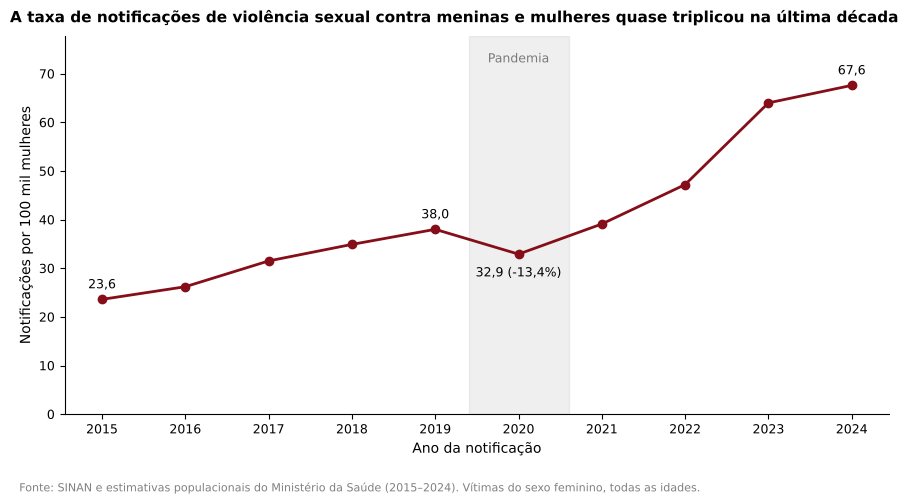

Taxa 2015: 23.6  |  Taxa 2024: 67.6  |  Aumento: 2.9x
Variação 2019 → 2020: -13.4%


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.plot(taxa.index, taxa.values, marker="o", color=VERMELHO, linewidth=2)

# destaque da pandemia
ax.axvspan(2019.4, 2020.6, color="gray", alpha=0.12)
ax.text(2020, taxa.max() * 1.07, "Pandemia", ha="center", fontsize=9, color=CINZA)

# valor em 2015, 2019 e 2024, e a queda de 2020
for ano in [2015, 2019, 2024]:
    ax.annotate(ptbr(taxa[ano]), (ano, taxa[ano]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
queda = (taxa[2020] / taxa[2019] - 1) * 100
ax.annotate(f"{ptbr(taxa[2020])} ({ptbr(queda, 1)}%)", (2020, taxa[2020]), textcoords="offset points",
            xytext=(0, -16), ha="center", fontsize=9)

ax.set_xlabel("Ano da notificação")
ax.set_ylabel("Notificações por 100 mil mulheres")
ax.set_xticks(taxa.index)
ax.set_ylim(0, taxa.max() * 1.15)
plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN e estimativas populacionais do Ministério da Saúde (2015–2024). Vítimas do sexo feminino, "
                   "todas as idades.")
titulo_na_imagem(fig, "A taxa de notificações de violência sexual contra meninas e mulheres quase triplicou na última década")
plt.savefig("../figures/p1_taxa_anual.png", dpi=200, bbox_inches="tight")
plt.show()

# números para o texto
print(f"Taxa 2015: {taxa[2015]}  |  Taxa 2024: {taxa[2024]}  |  Aumento: {taxa[2024]/taxa[2015]:.1f}x")
print(f"Variação 2019 → 2020: {(taxa[2020]/taxa[2019] - 1)*100:.1f}%")

**O que o gráfico mostra.** Entre 2015 e 2024, a taxa de notificações de violência sexual contra meninas e mulheres no SINAN passou de 23,6 para 67,6 por 100 mil mulheres, um aumento de 2,9 vezes. Como a taxa já desconta o crescimento da população, esse aumento não se explica por haver mais mulheres no país. O crescimento foi contínuo, com uma única interrupção: em 2020, primeiro ano da pandemia de Covid-19, a taxa caiu 13,4% em relação a 2019.

**Como interpretar.** A queda de 2020 não indica necessariamente menos violência: com o isolamento social e os serviços de saúde sobrecarregados, menos vítimas chegaram a um atendimento onde o caso pudesse ser notificado. Em 2021 a taxa já havia superado o patamar pré-pandemia. Da mesma forma, o crescimento ao longo da década mistura dois efeitos que estes dados não permitem separar: o aumento real da violência e a ampliação da capacidade de notificação dos serviços. Os registros policiais (FBSP), analisados na pergunta 7, ajudam a avaliar se a tendência aparece também fora do sistema de saúde.

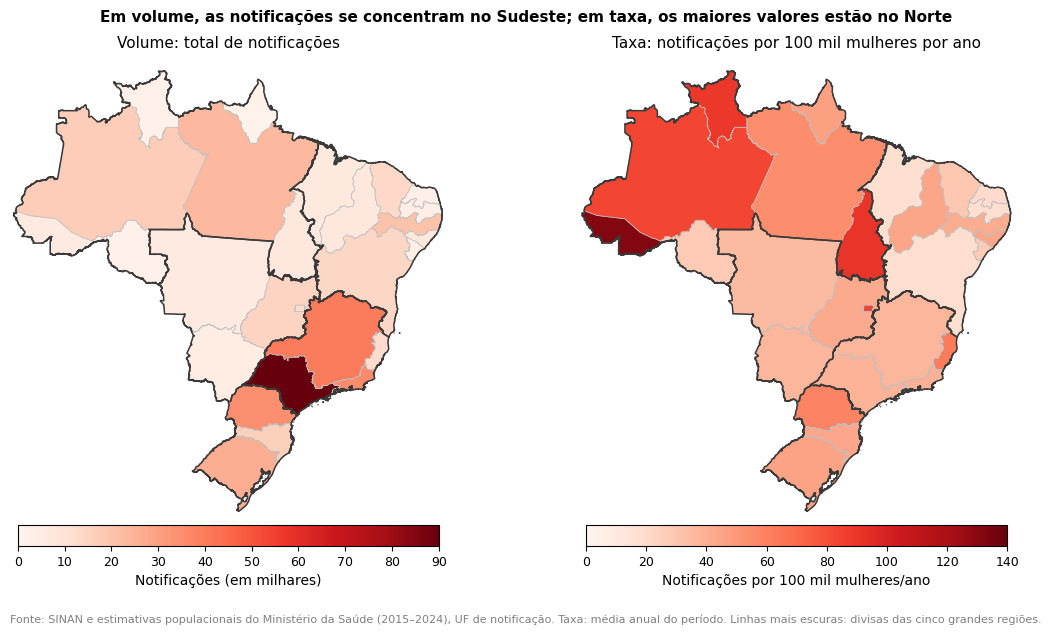

In [ ]:
# 1. Notificações por UF de notificação (2015-2024) e taxa média anual por 100 mil mulheres
df_uf = sinan.groupby("COD_UF").size().reset_index(name="notificacoes")
df_uf = df_uf.merge(pop_estados[["COD_UF", "pop_soma_10anos"]], on="COD_UF")
df_uf["taxa_anual_100mil"] = (df_uf["notificacoes"] / df_uf["pop_soma_10anos"] * 100_000).round(1)

# 2. Mapa oficial do Brasil por estados (baixado uma vez e reaproveitado nas seções 3, 6 e 8)
mapa_brasil = geobr.read_state(year=2020)
mapa_brasil["code_state"] = mapa_brasil["code_state"].astype(int)

# 3. Faz o cruzamento pelo código numérico do IBGE (code_state == COD_UF)
mapa_merge = mapa_brasil.merge(df_uf, left_on="code_state", right_on="COD_UF")

# 4. Divisas das cinco grandes regiões, desenhadas por cima das divisas dos estados
try:
    regioes = geobr.read_region(year=2020)
except Exception:  # se o download falhar, junta os estados de cada região
    regioes = mapa_brasil.dissolve(by="code_region")

# 5. Dois mapas lado a lado: volume absoluto e taxa por 100 mil mulheres
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
for ax, coluna, passo, titulo, rotulo, formato in [
    (ax1, "notificacoes", 10_000, "Volume: total de notificações", "Notificações (em milhares)", fmt_mil),
    (ax2, "taxa_anual_100mil", 20, "Taxa: notificações por 100 mil mulheres por ano",
     "Notificações por 100 mil mulheres/ano", fmt_decimal),
]:
    # a escala vai de 0 até o primeiro múltiplo de `passo` acima do maior valor, com números de ponta a ponta
    topo = np.ceil(mapa_merge[coluna].max() / passo) * passo
    mapa_merge.plot(column=coluna, cmap="Reds", vmin=0, vmax=topo, linewidth=0.5, ax=ax, edgecolor="0.75",
                    legend=True, legend_kwds={"label": rotulo, "orientation": "horizontal", "shrink": 0.7,
                                              "pad": 0.02, "format": formato,
                                              "ticks": np.arange(0, topo + passo / 2, passo)})
    regioes.boundary.plot(ax=ax, color="#3A3A3A", linewidth=1.1)
    # enquadra só o continente (as ilhas oceânicas, muito a leste, deixavam o mapa deslocado para a esquerda)
    ax.set_xlim(-74.3, -34.4)
    ax.set_ylim(-34.0, 5.6)
    ax.set_title(titulo, fontsize=11, loc="center", pad=14)
    ax.axis("off")

plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN e estimativas populacionais do Ministério da Saúde (2015–2024), UF de notificação. "
                   "Taxa: média anual do período. Linhas mais escuras: divisas das cinco grandes regiões.")
titulo_na_imagem(fig, "Em volume, as notificações se concentram no Sudeste; em taxa, os maiores valores estão no Norte")
plt.savefig("../figures/p1_mapa_uf.png", dpi=200, bbox_inches="tight")
plt.show()

**O que os mapas mostram:** O mapa da esquerda (volume absoluto) apresenta o número total bruto de notificações por estado entre 2015 e 2024. Nele, Unidades da Federação com maior contingente populacional, como São Paulo, Minas Gerais e Rio de Janeiro, naturalmente concentram as cores mais escuras devido à magnitude de suas populações. Já o mapa da direita revela o cenário corrigido: ao calcular a taxa média anual por 100 mil mulheres, removemos o peso do tamanho da população. Essa padronização desloca o foco, evidenciando que as maiores incidências relativas de notificação muitas vezes não estão no Sudeste, mas sim em estados das regiões Centro-Oeste, Norte ou Sul.

**Como interpretar:** Olhar apenas para o volume absoluto pode gerar falsas conclusões, pois é estatisticamente esperado que estados maiores tenham mais casos. A taxa por 100 mil mulheres é a métrica mais adequada para comparações regionais, pois nivela a régua. No entanto, é fundamental ler essas taxas com cautela no contexto do SINAN: uma taxa muito alta em um estado pode significar que há de fato mais violência, mas também pode ser reflexo de uma rede de saúde e de conselhos tutelares mais bem estruturados e ágeis para identificar e notificar os casos. Da mesma forma, estados com taxas muito "claras" (baixas) no mapa proporcional podem estar sofrendo de grave subnotificação, refletindo a dificuldade das vítimas em acessar a rede de saúde e segurança, e não necessariamente a ausência do crime.

## 2. Em que meses e dias da semana os casos se concentram? O ritmo é o mesmo para crianças e adultas?

**Pergunta de dados:** como as notificações se distribuem por mês e por dia da semana da ocorrência, separando as vítimas em três faixas etárias (0 a 13, 14 a 17 e 18 anos ou mais)?

**Transformação:** convertemos a data da ocorrência (`DT_OCOR`) em data, extraímos o mês e o dia da semana, e usamos as faixas etárias criadas na limpeza. Como as faixas têm tamanhos muito diferentes, comparamos a **porcentagem** dos casos de cada faixa em cada mês ou dia, e não a contagem. Excluímos as ocorrências registradas em 1º de janeiro: nas vítimas de 0 a 13 anos, 2,56% dos casos tinham essa data, quase dez vezes o esperado se as datas fossem distribuídas igualmente (0,27%). Isso indica que a data costuma ser preenchida por aproximação quando a data real é desconhecida, como em abusos repetidos.

In [ ]:
# só ocorrências dentro do período e com data e faixa válidas (só as colunas usadas nesta seção)
p2 = sinan.loc[sinan["DT_OCOR"].dt.year.between(2015, 2024) & sinan["FAIXA"].notna(), ["DT_OCOR", "FAIXA"]]
# exclui 1º de janeiro: data usada como preenchimento quando a data real é desconhecida
p2 = p2[~((p2["DT_OCOR"].dt.month == 1) & (p2["DT_OCOR"].dt.day == 1))].assign(
    MES=lambda d: d["DT_OCOR"].dt.month,
    DIA_SEMANA=lambda d: d["DT_OCOR"].dt.dayofweek,  # 0 = segunda
)

print(f"Casos usados na P2: {len(p2)} de {len(sinan)} ({len(p2)/len(sinan):.1%})")
# casos por faixa etária, na ordem crianças, adolescentes e adultas
p2["FAIXA"].value_counts().reindex(FAIXAS_IDADE).to_frame()

Casos usados na P2: 416001 de 433517 (96.0%)


,count
FAIXA,
0 a 13 anos,210819
14 a 17 anos,72453
18 anos ou mais,132729


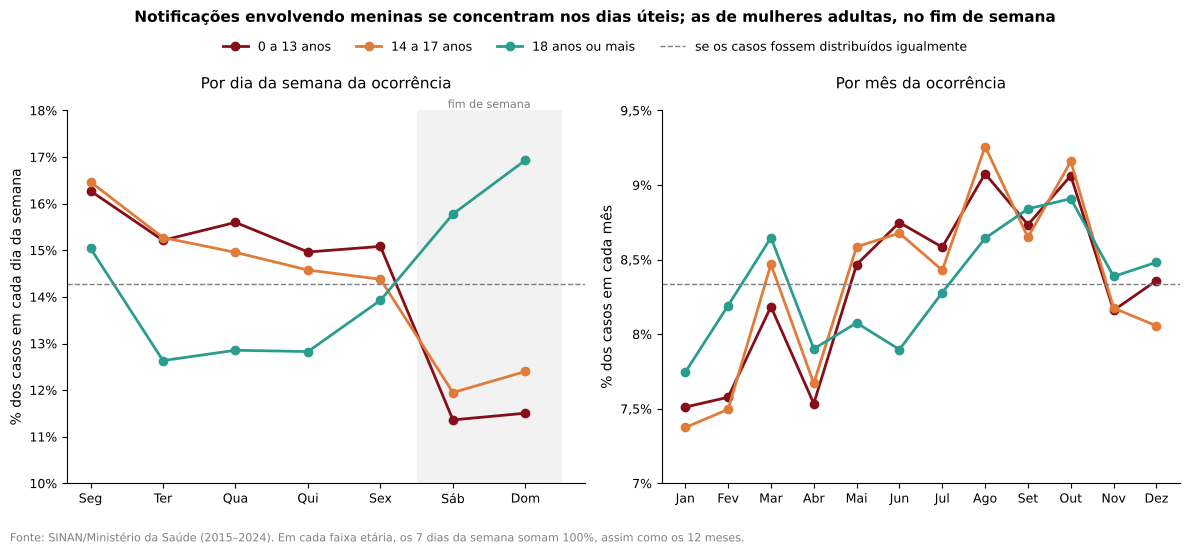

In [ ]:
meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

pct_mes = pd.crosstab(p2["MES"], p2["FAIXA"], normalize="columns") * 100
pct_dia = pd.crosstab(p2["DIA_SEMANA"], p2["FAIXA"], normalize="columns") * 100

fig, (ax_dia, ax_mes) = plt.subplots(1, 2, figsize=(12, 4.6))

# faixa de fundo no fim de semana
ax_dia.axvspan(4.5, 6.5, color="gray", alpha=0.10, lw=0)
ax_dia.text(5.5, 1.0, "fim de semana", transform=ax_dia.get_xaxis_transform(), ha="center", va="bottom",
            fontsize=8, color=CINZA)

for faixa, cor in CORES_FAIXA.items():
    ax_dia.plot(pct_dia.index, pct_dia[faixa], marker="o", color=cor, label=faixa, linewidth=2)
    ax_mes.plot(pct_mes.index, pct_mes[faixa], marker="o", color=cor, label=faixa, linewidth=2)
ax_dia.axhline(100 / 7, color="gray", linestyle="--", linewidth=1)
ax_mes.axhline(100 / 12, color="gray", linestyle="--", linewidth=1)

ax_dia.set_xticks(range(7), dias)
ax_dia.set_title("Por dia da semana da ocorrência", fontsize=11, pad=16, loc="center")
ax_dia.set_ylabel("% dos casos em cada dia da semana")
ax_dia.set_ylim(10, 18)
ax_dia.yaxis.set_major_locator(MultipleLocator(1))

ax_mes.set_xticks(range(1, 13), meses)
ax_mes.set_title("Por mês da ocorrência", fontsize=11, pad=16, loc="center")
ax_mes.set_ylabel("% dos casos em cada mês")
ax_mes.set_ylim(7, 9.5)
ax_mes.yaxis.set_major_locator(MultipleLocator(0.5))

for ax in (ax_dia, ax_mes):
    ax.yaxis.set_major_formatter(fmt_pct)

# uma legenda só, centralizada acima dos dois gráficos, com a linha tracejada explicada
alcas = [Line2D([], [], color=c, marker="o", lw=2, label=f) for f, c in CORES_FAIXA.items()]
alcas.append(Line2D([], [], color="gray", ls="--", lw=1, label="se os casos fossem distribuídos igualmente"))
plt.tight_layout()
# a legenda entra depois do layout, logo acima dos subtítulos e centralizada na imagem
fig.canvas.draw()
topo_subtitulos = max(ax.title.get_window_extent(fig.canvas.get_renderer()).y1 for ax in (ax_dia, ax_mes))
topo_subtitulos = fig.transFigure.inverted().transform((0, topo_subtitulos))[1]
fig.legend(handles=alcas, loc="lower center", ncol=4, fontsize=9,
           bbox_to_anchor=(centro_da_imagem(fig), topo_subtitulos + 8 / 72 / fig.get_figheight()))
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (2015–2024). Em cada faixa etária, os 7 dias da semana somam 100%, "
                   "assim como os 12 meses.")
titulo_na_imagem(fig, "Notificações envolvendo meninas se concentram nos dias úteis; as de mulheres adultas, no fim de semana")
plt.savefig("../figures/p2_mes_dia_semana.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** O dia da semana separa claramente as faixas etárias. Entre mulheres adultas, os casos se concentram no fim de semana: domingo reúne 17% das ocorrências e sábado quase 16%, acima dos 14,3% esperados. Entre meninas de 0 a 13 e de 14 a 17 anos, o padrão se inverte: as ocorrências se concentram nos dias úteis, com pico na segunda-feira, e caem para 11% a 12,5% no fim de semana.

**Como interpretar.** Para as adultas, o padrão é compatível com situações de lazer e convívio social. Para as meninas, ele acompanha o calendário escolar: além da concentração nos dias úteis, os meses com menos notificações são janeiro, fevereiro e abril, com uma queda também em julho, enquanto os picos ocorrem em março, agosto e outubro, logo após o retorno das aulas. Entre as adultas, a variação entre meses é menor e não segue esse calendário. Uma hipótese é que parte da violência contra crianças, frequentemente cometida em casa e de forma repetida, seja registrada na data em que é revelada, muitas vezes por professores ou em serviços ligados à escola, e não na data em que aconteceu. Se for assim, as férias escolares não reduziriam a violência, mas sim a chance de ela ser identificada. Observação: fevereiro tem menos dias que os outros meses, o que explica parte do seu valor mais baixo.

**Cuidado com os dados.** A concentração de datas em 1º de janeiro mostra que a data da ocorrência é menos confiável para crianças, justamente o grupo em que a violência tende a ser contínua.

## 3. Quem são as vítimas? Como as taxas variam por idade, cor/raça e deficiência?

**Pergunta de dados:** qual a idade das vítimas notificadas e qual a taxa de notificação por 100 mil mulheres em cada faixa etária, cor/raça e condição de deficiência?

**Transformação:** usamos a idade decodificada na etapa de limpeza. Primeiro olhamos a distribuição das notificações por idade simples (contagem); depois dividimos pelo tamanho de cada grupo na população para obter taxas. Para idade, usamos as estimativas anuais 2015–2024. Para cor/raça, a população só está disponível no Censo 2022, então comparamos com a média anual de notificações de 2021 a 2023, centrada no ano do Censo.

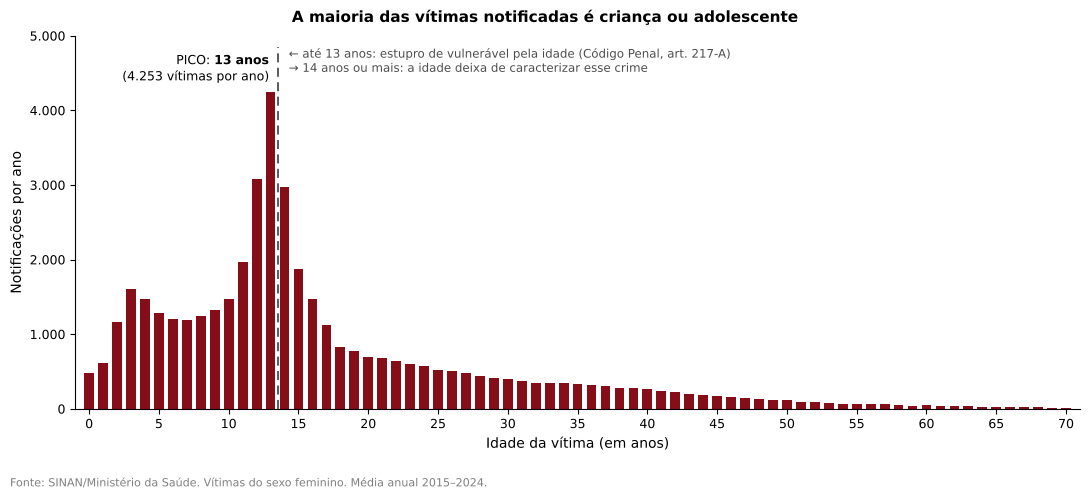

Vítimas com menos de 14 anos: 51.6%
Vítimas com menos de 18 anos: 68.7%


In [ ]:
# média anual de notificações por idade simples (0 a 70 anos)
por_idade = (sinan[sinan["IDADE"].between(0, 70)]
             .groupby("IDADE").size() / 10)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(por_idade.index, por_idade.values, color=VERMELHO, width=0.7)  # colunas mais finas: mais espaço entre elas

# limite legal do estupro de vulnerável: linha entre as colunas de 13 e 14 anos, mais alta que a maior coluna
topo_linha = 4_850
ax.vlines(13.5, 0, topo_linha, color="#4D4D4D", linestyle=(0, (5, 3)), linewidth=1.3, zorder=3)
ax.text(14.3, topo_linha, "← até 13 anos: estupro de vulnerável pela idade (Código Penal, art. 217-A)\n"
                          "→ 14 anos ou mais: a idade deixa de caracterizar esse crime",
        fontsize=8.5, color="#4D4D4D", va="top")

# pico, à esquerda da linha, com a idade em negrito
idade_pico = int(por_idade.idxmax())
ax.annotate(rf"PICO: $\bf{{{idade_pico}\ anos}}$" + f"\n({ptbr(por_idade.max(), 0)} vítimas por ano)",
            (13.2, por_idade.max()), textcoords="offset points", xytext=(-3, 5), ha="right", va="bottom",
            fontsize=9, multialignment="right")

ax.set_xlabel("Idade da vítima (em anos)")
ax.set_ylabel("Notificações por ano")
ax.set_xticks(range(0, 71, 5))
ax.set_xlim(-1, 71)
ax.set_ylim(0, 5_000)
ax.yaxis.set_major_locator(MultipleLocator(1_000))
ax.yaxis.set_major_formatter(fmt_milhar)

plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde. Vítimas do sexo feminino. Média anual 2015–2024.")
titulo_na_imagem(fig, "A maioria das vítimas notificadas é criança ou adolescente")
plt.savefig("../figures/p3_idade.png", dpi=200, bbox_inches="tight")
plt.show()

menores_14 = (sinan["IDADE"] < 14).mean() * 100
menores_18 = (sinan["IDADE"] < 18).mean() * 100
print(f"Vítimas com menos de 14 anos: {menores_14:.1f}%")
print(f"Vítimas com menos de 18 anos: {menores_18:.1f}%")

**O que o gráfico mostra.** Mais da metade das vítimas notificadas (51,6%) tinha menos de 14 anos, e 68,7% eram menores de 18. A idade com mais notificações é 13 anos, logo antes do limite legal do estupro de vulnerável. Há também um segundo pico entre 3 e 4 anos. Depois dos 15 anos, as notificações caem de forma contínua com a idade.

### Taxa por faixa etária

A contagem não leva em conta que cada idade tem um número diferente de mulheres na população. Por isso, dividimos as notificações de cada faixa pela população feminina da mesma faixa. A taxa abaixo é uma média anual: notificações de 2015 a 2024 ÷ população somada dos 10 anos × 100 mil.

In [ ]:
pop_idade = pd.read_csv("../data/processed/pop_feminina_idade_2015_2024.csv",
                        sep=";", encoding="latin-1", skiprows=4)
pop_idade = pop_idade.rename(columns={pop_idade.columns[0]: "FAIXA_POP"})
pop_idade = pop_idade[pop_idade["FAIXA_POP"].str.contains("anos", na=False)].copy()
pop_idade["FAIXA_POP"] = pop_idade["FAIXA_POP"].str.strip()
pop_idade["pop_total"] = pop_idade[anos].astype(int).sum(axis=1)   # soma 2015–2024 (ignora 2014)

# as faixas da população são as mesmas da coluna FAIXA_POP criada na limpeza
faixas_pop = pop_idade["FAIXA_POP"].tolist()
assert faixas_pop == FAIXAS_POP

notif = sinan["FAIXA_POP"].value_counts().reindex(faixas_pop).values
tabela_p3 = pd.DataFrame({
    "notificacoes": notif,
    "pop_mulher_ano": pop_idade["pop_total"].values,
    "taxa_100mil": (notif / pop_idade["pop_total"].values * 100_000).round(1),
}, index=faixas_pop)
tabela_p3

,notificacoes,pop_mulher_ano,taxa_100mil
0 a 4 anos,53426,69293007,77.1
5 a 9 anos,62517,71286615,87.7
10 a 14 anos,137436,73542227,186.9
15 a 19 anos,60647,78832700,76.9
20 a 29 anos,55510,165724883,33.5
30 a 39 anos,33453,169255439,19.8
40 a 49 anos,18186,149190261,12.2
50 a 59 anos,7342,123468624,5.9
60 a 69 anos,2903,88436285,3.3
70 a 79 anos,1183,49836433,2.4


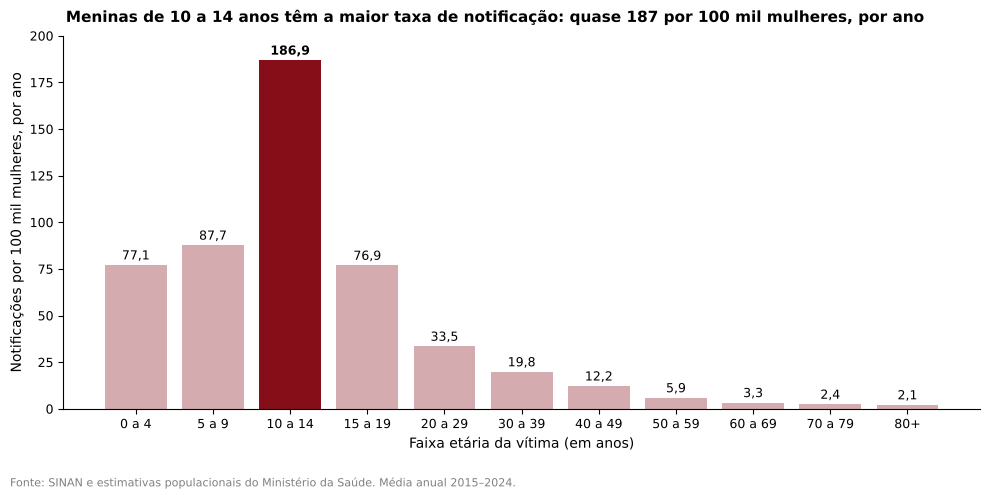

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))

cores_barras = [VERMELHO if f == "10 a 14 anos" else VERMELHO_CLARO for f in tabela_p3.index]
ax.bar(range(len(tabela_p3)), tabela_p3["taxa_100mil"], color=cores_barras)

# valor em cima de cada coluna; o da faixa de 10 a 14 anos em negrito
for i, (faixa, v) in enumerate(tabela_p3["taxa_100mil"].items()):
    ax.text(i, v + 3, ptbr(v), ha="center", fontsize=9, fontweight="bold" if faixa == "10 a 14 anos" else "normal")

ax.set_xticks(range(len(tabela_p3)), [f.replace(" anos", "").replace(" e mais", "+") for f in tabela_p3.index])
ax.set_xlabel("Faixa etária da vítima (em anos)")
ax.set_ylabel("Notificações por 100 mil mulheres, por ano")
ax.set_ylim(0, 200)
ax.yaxis.set_major_locator(MultipleLocator(25))
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN e estimativas populacionais do Ministério da Saúde. Média anual 2015–2024.")
titulo_na_imagem(fig, "Meninas de 10 a 14 anos têm a maior taxa de notificação: quase 187 por 100 mil mulheres, por ano")
plt.savefig("../figures/p3_taxa_idade.png", dpi=200, bbox_inches="tight")
plt.show()


**O que o gráfico mostra.** Ao considerar o tamanho de cada grupo na população, a concentração na infância e no início da adolescência fica ainda mais clara. A faixa de 10 a 14 anos tem 186,9 notificações por 100 mil meninas por ano, mais que o dobro das faixas vizinhas (87,7 entre 5 e 9 anos e 76,9 entre 15 e 19). A partir dos 20 anos, a taxa cai rapidamente: 33,5 entre 20 e 29 anos e menos de 6 a partir dos 50.

**Como interpretar.** Parte da diferença pode refletir onde a notificação acontece: crianças e adolescentes passam por serviços (escola, conselho tutelar, unidades de saúde) que identificam e notificam a violência, enquanto mulheres adultas podem procurar diretamente a polícia ou não procurar atendimento. Ainda assim, a magnitude da taxa entre 10 e 14 anos aponta esse grupo como prioritário para prevenção.

### Taxa por cor/raça

Como a população feminina por cor/raça só existe no Censo, usamos a população de 2022 (IBGE, SIDRA 9606) e a média anual de notificações de 2021 a 2023. Notificações com cor/raça ignorada (4,5% nesse período) ficam de fora da taxa.

In [ ]:
pop_raca = pd.read_csv("../data/processed/pop_feminina_raca_censo2022.csv", sep=";", index_col="cor_raca")

notif_raca = (sinan[sinan["ANO"].between(2021, 2023)]["RACA"].value_counts() / 3).reindex(pop_raca.index)

tabela_raca = pd.DataFrame({
    "notificacoes_ano": notif_raca.round(0),
    "pop_feminina_2022": pop_raca["pop_feminina_2022"],
    "taxa_100mil": (notif_raca / pop_raca["pop_feminina_2022"] * 100_000).round(1),
}).sort_values("taxa_100mil")

# mulheres negras = pretas + pardas
negras = (notif_raca[["Preta", "Parda"]].sum() / pop_raca.loc[["Preta", "Parda"], "pop_feminina_2022"].sum() * 100_000)
print(f"Taxa mulheres negras (pretas + pardas): {negras:.1f}  |  brancas: {tabela_raca.loc['Branca', 'taxa_100mil']}")
tabela_raca

Taxa mulheres negras (pretas + pardas): 55.4  |  brancas: 40.7


,notificacoes_ano,pop_feminina_2022,taxa_100mil
cor_raca,,,
Branca,18925.0,46463555,40.7
Preta,5326.0,10130438,52.6
Parda,26246.0,46883709,56.0
Amarela,491.0,449273,109.2
Indígena,748.0,616574,121.4


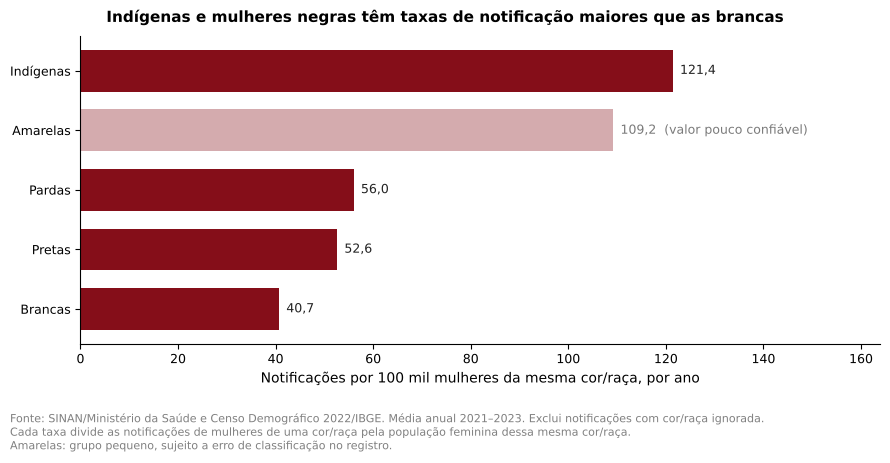

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.8))

# amarelas em tom claro: grupo pequeno e com suspeita de erro de classificação (ver texto)
cores_raca = [VERMELHO_CLARO if grupo == "Amarela" else VERMELHO for grupo in tabela_raca.index]
ax.barh([PLURAL_RACA[g] for g in tabela_raca.index], tabela_raca["taxa_100mil"], color=cores_raca, height=0.7)
for i, (grupo, v) in enumerate(tabela_raca["taxa_100mil"].items()):
    rotulo = ptbr(v) + ("  (valor pouco confiável)" if grupo == "Amarela" else "")
    ax.text(v + 1.5, i, rotulo, va="center", fontsize=9, color=CINZA if grupo == "Amarela" else "#222222")

ax.set_xlabel("Notificações por 100 mil mulheres da mesma cor/raça, por ano")
ax.set_xlim(0, tabela_raca["taxa_100mil"].max() * 1.35)

plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde e Censo Demográfico 2022/IBGE. Média anual 2021–2023. Exclui notificações com "
                   "cor/raça ignorada.\nCada taxa divide as notificações de mulheres de uma cor/raça pela população feminina dessa "
                   "mesma cor/raça.\nAmarelas: grupo pequeno, sujeito a erro de classificação no registro.")
titulo_na_imagem(fig, "Indígenas e mulheres negras têm taxas de notificação maiores que as brancas")
plt.savefig("../figures/p3_taxa_raca.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** Mulheres pretas (52,6 por 100 mil por ano) e pardas (56,0) têm taxas de notificação maiores que as brancas (40,7). Somadas, as mulheres negras chegam a 55,4, cerca de 1,4 vez a taxa das brancas. As maiores taxas são das indígenas (121,4), quase três vezes a das brancas.

**Cuidados.** Estas são taxas brutas: grupos com população mais jovem, como as indígenas, tendem a ter taxas maiores simplesmente porque a violência sexual notificada se concentra na infância e na adolescência. Por isso, logo abaixo padronizamos as taxas por idade. A taxa das amarelas (109,2) deve ser lida com cautela. Ela não significa que haja mais vítimas amarelas do que pardas: em números absolutos, são cerca de 491 notificações de mulheres amarelas por ano, contra 26.246 de mulheres pardas. A taxa sai alta porque esses poucos casos são divididos por uma população muito pequena (0,4% das mulheres do país). Com uma base tão pequena, poucos erros de registro pesam muito: no SINAN, a cor/raça é preenchida pelo profissional de saúde e a categoria amarela pode ser marcada por engano, enquanto no Censo ela é autodeclarada.

#### Taxa por cor/raça padronizada por idade

As taxas acima são brutas: um grupo com população mais jovem tende a ter taxa maior, porque a violência sexual notificada se concentra na infância e na adolescência. Para separar o efeito da cor/raça do efeito da idade, padronizamos as taxas pela estrutura etária de todas as mulheres do Brasil.

In [ ]:
pop_ri = pd.read_csv("../data/processed/pop_feminina_raca_idade_censo2022.csv",
                     sep=";", encoding="utf-8-sig", skiprows=6, nrows=21, header=None,
                     names=["nivel", "idade", "Branca", "Preta", "Amarela", "Parda", "Indígena"])
pop_ri = pop_ri.drop(columns="nivel").set_index("idade").astype(int)

# conferência: a soma de cada coluna deve bater com a população total por cor/raça que já usamos
pd.DataFrame({"soma_por_idade": pop_ri.sum(),
              "total_usado_antes": pop_raca["pop_feminina_2022"]})

,soma_por_idade,total_usado_antes
Branca,46463555,46463555
Preta,10130438,10130438
Amarela,449273,449273
Parda,46883709,46883709
Indígena,616574,616574


**Como funciona a padronização.** Primeiro calculamos a taxa de cada cor/raça dentro de cada faixa etária (por exemplo, a taxa de meninas indígenas de 10 a 14 anos). Depois fazemos uma média dessas taxas usando sempre os mesmos pesos: a proporção de cada faixa etária entre todas as mulheres do Brasil. O resultado responde à pergunta: *qual seria a taxa de cada grupo se todos tivessem a mesma distribuição de idade?* Usamos faixas de 5 anos, agrupando 80 anos ou mais, e a média anual de notificações de 2021 a 2023.

In [ ]:
# faixas de 5 anos, agrupando 80 anos ou mais
faixas_5 = list(pop_ri.index[:16]) + ["80 anos ou mais"]
pop_r5 = pop_ri.iloc[:16].copy()
pop_r5.loc["80 anos ou mais"] = pop_ri.iloc[16:].sum()

# notificações por cor/raça e faixa etária (média anual 2021–2023)
notif_r = sinan.loc[sinan["ANO"].between(2021, 2023) & (sinan["RACA"] != "Ignorado"), ["IDADE", "RACA"]]
notif_r = notif_r.assign(FAIXA_5=pd.cut(notif_r["IDADE"], bins=list(range(-1, 80, 5)) + [200], labels=faixas_5))
n_r5 = pd.crosstab(notif_r["FAIXA_5"], notif_r["RACA"]).reindex(index=faixas_5, columns=pop_r5.columns) / 3

# taxa específica por idade (por 100 mil por ano)
taxa_r5 = n_r5 / pop_r5 * 100_000

# pesos: estrutura etária de todas as mulheres do Brasil
pesos = pop_r5.sum(axis=1) / pop_r5.sum().sum()

tabela_padr = pd.DataFrame({
    "taxa_bruta": (n_r5.sum() / pop_r5.sum() * 100_000).round(1),
    "taxa_padronizada": taxa_r5.mul(pesos, axis=0).sum().round(1),
})
tabela_padr["razao_vs_branca"] = (tabela_padr["taxa_padronizada"] / tabela_padr.loc["Branca", "taxa_padronizada"]).round(2)

# mulheres negras (pretas + pardas)
n_neg, p_neg = n_r5[["Preta", "Parda"]].sum(axis=1), pop_r5[["Preta", "Parda"]].sum(axis=1)

# primeiro a tabela, depois a frase das mulheres negras
display(tabela_padr.sort_values("taxa_padronizada"))
bruta_neg = n_neg.sum() / p_neg.sum() * 100_000
padr_neg = ((n_neg / p_neg * 100_000) * pesos).sum()
razao_neg = round(padr_neg, 1) / tabela_padr.loc["Branca", "taxa_padronizada"]  # mesma conta da coluna razao_vs_branca
print(f"Mulheres negras: taxa_bruta {bruta_neg:.1f}  |  taxa_padronizada {padr_neg:.1f}  |  razao_vs_branca {razao_neg:.2f}")

,taxa_bruta,taxa_padronizada,razao_vs_branca
Branca,40.7,43.5,1.00
Parda,55.9,51.3,1.18
Preta,52.5,58.8,1.35
Indígena,120.9,82.3,1.89
Amarela,109.1,160.2,3.68


Mulheres negras: taxa_bruta 55.3  |  taxa_padronizada 52.6  |  razao_vs_branca 1.21


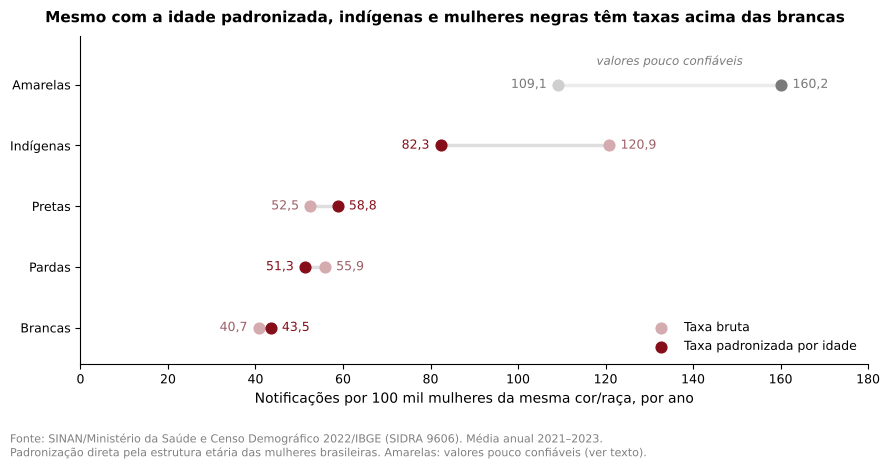

In [ ]:
ordem = tabela_padr.sort_values("taxa_padronizada").index
CINZA_LINHA = "#DEDEDE"  # linha que liga a taxa bruta à padronizada

fig, ax = plt.subplots(figsize=(9, 4))
for i, grupo in enumerate(ordem):
    bruta, padr = tabela_padr.loc[grupo, ["taxa_bruta", "taxa_padronizada"]]
    if grupo == "Amarela":  # amarelas em cinza: valores pouco confiáveis (ver texto)
        cor_bruta, cor_padr, cor_linha = "#CFCFCF", CINZA, "#EBEBEB"
        cor_txt_bruta = cor_txt_padr = CINZA
    else:
        cor_bruta, cor_padr, cor_linha = VERMELHO_CLARO, VERMELHO, CINZA_LINHA
        cor_txt_bruta, cor_txt_padr = "#9C5F66", VERMELHO
    ax.plot([bruta, padr], [i, i], color=cor_linha, linewidth=2.5, zorder=1)
    ax.scatter(bruta, i, color=cor_bruta, s=60, zorder=2)
    ax.scatter(padr, i, color=cor_padr, s=60, zorder=3)
    # rótulos para fora: o menor valor à esquerda do seu ponto, o maior à direita
    for valor, cor, menor in [(bruta, cor_txt_bruta, bruta <= padr), (padr, cor_txt_padr, padr < bruta)]:
        ax.annotate(ptbr(valor), (valor, i), textcoords="offset points", xytext=(-8 if menor else 8, 0),
                    ha="right" if menor else "left", va="center", fontsize=9, color=cor)
    if grupo == "Amarela":
        ax.text((bruta + padr) / 2, i + 0.28, "valores pouco confiáveis", ha="center", va="bottom", fontsize=8.5,
                color=CINZA, style="italic")

ax.scatter([], [], color=VERMELHO_CLARO, s=60, label="Taxa bruta")
ax.scatter([], [], color=VERMELHO, s=60, label="Taxa padronizada por idade")
ax.legend(frameon=False, loc="lower right")

ax.set_yticks(range(len(ordem)), [PLURAL_RACA[g] for g in ordem])
ax.set_ylim(-0.6, len(ordem) - 0.2)
ax.set_xlim(0, 180)
ax.xaxis.set_major_locator(MultipleLocator(20))
ax.set_xlabel("Notificações por 100 mil mulheres da mesma cor/raça, por ano")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde e Censo Demográfico 2022/IBGE (SIDRA 9606). Média anual 2021–2023.\n"
                   "Padronização direta pela estrutura etária das mulheres brasileiras. Amarelas: valores pouco confiáveis "
                   "(ver texto).")
titulo_na_imagem(fig, "Mesmo com a idade padronizada, indígenas e mulheres negras têm taxas acima das brancas")
plt.savefig("../figures/p3_taxa_raca_padronizada.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** A padronização muda bastante o quadro para alguns grupos. A taxa das indígenas cai de cerca de 121 para 82,3, porque 32% das mulheres indígenas têm menos de 15 anos, contra 18% das brancas. Mesmo assim, continua quase o dobro da taxa das brancas (43,5). Entre as mulheres negras, a diferença também diminui, mas não desaparece: pretas têm 58,8 (1,35 vez a das brancas) e pardas, 51,3 (1,18 vez).

**Como interpretar.** A maior parte da diferença entre indígenas e brancas não se explica pela idade, o que reforça que a violência sexual notificada atinge de forma desigual os grupos por cor/raça. Já para as amarelas, a padronização faz a taxa subir para 160,2, porque essa população é mais velha. Esse número não é plausível: a taxa de meninas amarelas de 10 a 14 anos passaria de 800 por 100 mil por ano, mais de quatro vezes a das brancas da mesma idade. Isso reforça a hipótese de erro de classificação de cor/raça no registro, e por isso não tiramos conclusões sobre esse grupo.

### Deficiência e transtornos

A ficha do SINAN registra se a vítima tem deficiência (física, intelectual, visual, auditiva) ou transtorno (mental ou de comportamento). Essa definição é mais ampla que a do Censo e muda conforme a idade, por isso, nesta etapa, olhamos a **proporção de vítimas** com cada condição em cada faixa etária, em vez de uma taxa populacional.

In [ ]:
tipos = {
    "DEF_MENTAL": "Deficiência intelectual",
    "DEF_FISICA": "Deficiência física",
    "DEF_VISUAL": "Deficiência visual",
    "DEF_AUDITI": "Deficiência auditiva",
    "TRAN_MENT": "Transtorno mental",
    "TRAN_COMP": "Transtorno de comportamento",
}

# só notificações em que o campo deficiência/transtorno foi preenchido (Sim ou Não)
pd_def = sinan.loc[sinan["DEFICIENCIA"] != "Ignorado", ["FAIXA", "DEFICIENCIA", *tipos]]
pd_def = pd_def.assign(**{col: limpa_codigo(pd_def[col]).eq("1") for col in tipos})

pct_tipo = (pd_def.groupby("FAIXA", observed=True)[list(tipos)].mean() * 100).rename(columns=tipos).T.round(1)
pct_alguma = (pd_def["DEFICIENCIA"].eq("Sim").groupby(pd_def["FAIXA"], observed=True).mean() * 100).round(1)

# uma tabela só: a última linha é a % de vítimas com pelo menos uma deficiência ou transtorno.
# Ela não é a soma das outras linhas, porque uma mesma vítima pode ter mais de uma condição marcada.
# (pct_tipo continua separada porque é a base do gráfico abaixo)
print("Porcentagem de vítimas com cada deficiência ou transtorno, por faixa etária:")
tabela_def = pd.concat([pct_tipo, pct_alguma.to_frame("Alguma deficiência ou transtorno").T])
tabela_def = tabela_def.rename_axis(columns="FAIXA ETÁRIA")  # título do cabeçalho das colunas

# tudo centralizado: números, nomes das linhas e cabeçalhos
(tabela_def.style
    .format(precision=1)
    .set_table_styles([{"selector": "th, td", "props": [("text-align", "center")]}]))

Porcentagem de vítimas com cada deficiência ou transtorno, por faixa etária:


FAIXA ETÁRIA,0 a 13 anos,14 a 17 anos,18 anos ou mais
Deficiência intelectual,1.3,3.0,4.2
Deficiência física,0.3,0.5,1.3
Deficiência visual,0.2,0.3,0.7
Deficiência auditiva,0.1,0.3,0.7
Transtorno mental,1.6,4.4,8.4
Transtorno de comportamento,1.4,2.9,3.7
Alguma deficiência ou transtorno,5.0,10.3,16.1


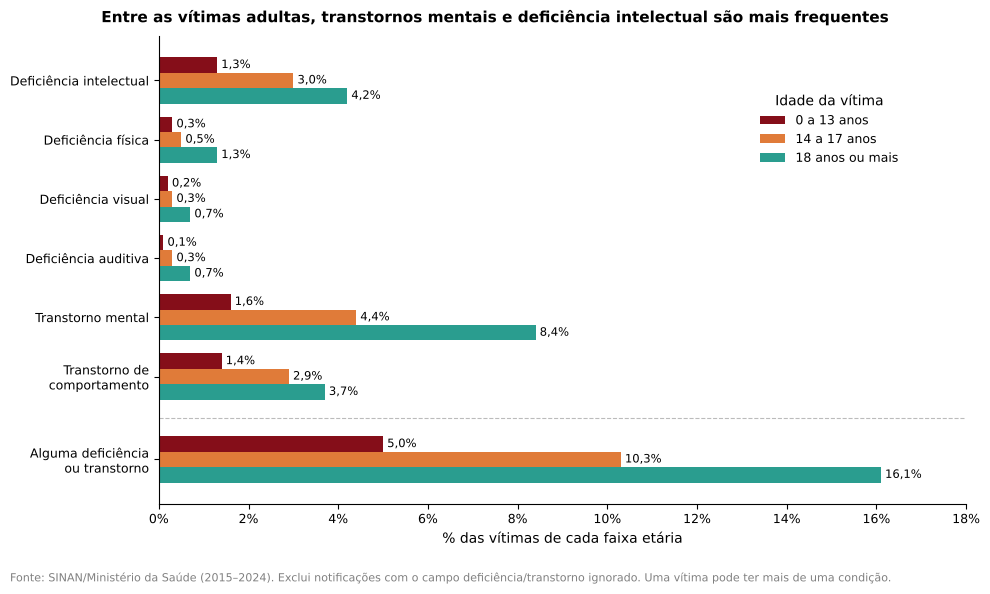

In [ ]:
# os seis tipos e, por último, "Alguma deficiência ou transtorno" (a mesma tabela mostrada acima)
dados_def = tabela_def

fig, ax = plt.subplots(figsize=(10, 5.4))

y = np.arange(len(dados_def), dtype=float)
y[-1] += 0.4  # um respiro antes de "Alguma deficiência ou transtorno", que não é mais um tipo
altura = 0.26
for k, (faixa, cor) in enumerate(CORES_FAIXA.items()):
    # (k - 1): a primeira faixa fica em cima em cada grupo, na mesma ordem da legenda
    barras = ax.barh(y + (k - 1) * altura, dados_def[faixa], height=altura, color=cor, label=faixa)
    for b, v in zip(barras, dados_def[faixa]):
        ax.annotate(ptbr(v) + "%", (v, b.get_y() + b.get_height() / 2), xytext=(3, 0), textcoords="offset points",
                    va="center", fontsize=8.3, color="black")

# linha separando os tipos do total de vítimas com alguma condição
ax.axhline((y[-2] + y[-1]) / 2, color="#BBBBBB", linestyle="--", linewidth=0.8)

# nomes compridos em duas linhas
quebra = {"Transtorno de comportamento": "Transtorno de\ncomportamento",
          "Alguma deficiência ou transtorno": "Alguma deficiência\nou transtorno"}
ax.set_yticks(y, [quebra.get(nome, nome) for nome in dados_def.index])
ax.invert_yaxis()
ax.set_xlabel("% das vítimas de cada faixa etária")
ax.set_xlim(0, 18)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.xaxis.set_major_formatter(fmt_pct)
ax.legend(title="Idade da vítima", loc="upper right", bbox_to_anchor=(0.93, 0.9))

plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (2015–2024). Exclui notificações com o campo deficiência/transtorno ignorado. "
                   "Uma vítima pode ter mais de uma condição.")
titulo_na_imagem(fig, "Entre as vítimas adultas, transtornos mentais e deficiência intelectual são mais frequentes")
plt.savefig("../figures/p3_deficiencia.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** Entre as notificações com o campo preenchido, 5,0% das vítimas de 0 a 13 anos tinham alguma deficiência ou transtorno, proporção que sobe para 10,3% entre 14 e 17 anos e 16,1% entre adultas. As condições mais frequentes são o transtorno mental (8,4% das vítimas adultas) e a deficiência intelectual (4,2%). Deficiências física, visual e auditiva aparecem em menos de 1,5% dos casos em todas as faixas.

**Como interpretar.** Deficiência intelectual e transtornos mentais podem aumentar a vulnerabilidade, porque dificultam reconhecer a violência, pedir ajuda ou ser ouvida, e aumentam a dependência de cuidadores. Entre crianças, a proporção menor pode refletir, em parte, que essas condições ainda não foram diagnosticadas. Como a definição do SINAN é mais ampla que a do Censo e a prevalência de deficiência muda muito com a idade, nesta etapa não calculamos uma taxa populacional; o campo também tem 11,5% de respostas ignoradas.

### Proporção de vítimas com menos de 14 anos, por UF

A concentração das vítimas na infância é igual em todo o país? Para cada UF, calculamos a porcentagem das notificações de 2015 a 2024 em que a vítima tinha menos de 14 anos (UF de notificação).

Maiores proporções: TO 66.6%, PA 62.3%, PI 61.8%, SE 61.8%, AM 61.4%
Menores proporções: PE 36.3%, BA 36.5%, PB 36.7%, CE 40.5%, AC 43.3%


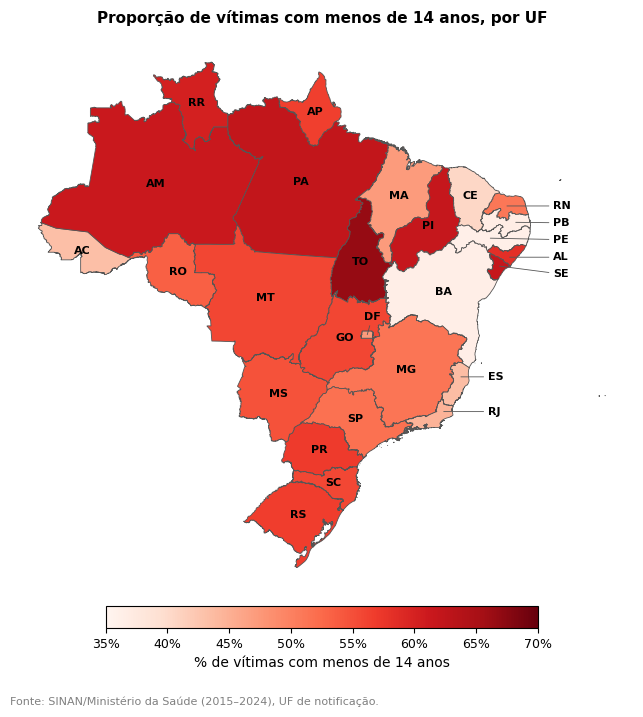

In [ ]:
# 1. Total de casos e casos de menores de 14 anos por UF, e a porcentagem de menores de 14 anos
menor_14 = sinan["IDADE"] < 14
df_idade_uf = (menor_14.groupby(sinan["COD_UF"]).agg(total_casos="size", casos_menores_14="sum")
               .reset_index().astype({"COD_UF": int}))
df_idade_uf["pct_menores_14"] = (df_idade_uf["casos_menores_14"] / df_idade_uf["total_casos"] * 100).round(1)

# 2. Cruza com o mapa dos estados (baixado na seção 1) pelo código do IBGE
mapa_merge = mapa_brasil.merge(df_idade_uf, left_on="code_state", right_on="COD_UF")

# Ranking das UFs
ranking_menores = mapa_merge.sort_values("pct_menores_14", ascending=False)
print("Maiores proporções:", ", ".join(f"{r.abbrev_state} {r.pct_menores_14:.1f}%" for r in ranking_menores.head(5).itertuples()))
print("Menores proporções:", ", ".join(f"{r.abbrev_state} {r.pct_menores_14:.1f}%"
                                      for r in ranking_menores.tail(5).iloc[::-1].itertuples()))  # da menor para a maior

# 3. Mapa coroplético com a sigla de cada UF, na mesma escala de vermelhos dos outros mapas, indo de 35% a 70%
fig, ax = plt.subplots(1, 1, figsize=(7.5, 7))
mapa_merge.plot(column="pct_menores_14", cmap="Reds", vmin=35, vmax=70, linewidth=0.6, ax=ax,
                edgecolor="#555555", legend=True,
                legend_kwds={"label": "% de vítimas com menos de 14 anos", "orientation": "horizontal",
                             "shrink": 0.6, "pad": 0.02, "format": fmt_pct, "ticks": np.arange(35, 71, 5)})

# siglas pretas, em negrito e sem contorno
TAMANHO_SIGLA = 8
# estados pequenos demais para a sigla caber dentro: a sigla vai para o mar, numa coluna à direita do litoral
# (x = longitude da coluna), ligada ao estado por uma linha fina
SIGLAS_NO_MAR = {"RN": -33.0, "PB": -33.0, "PE": -33.0, "AL": -33.0, "SE": -33.0, "ES": -38.2, "RJ": -38.2}
# posição escolhida à mão (longitude, latitude) para siglas que ficariam em cima de uma divisa
POSICAO_MANUAL = {"AC": (-70.5, -9.3)}

for _, uf in mapa_merge[~mapa_merge["abbrev_state"].isin(list(SIGLAS_NO_MAR) + ["DF"])].iterrows():
    p = ponto_da_sigla(uf.geometry)
    x, y = POSICAO_MANUAL.get(uf["abbrev_state"], (p.x, p.y))
    ax.annotate(uf["abbrev_state"], (x, y), ha="center", va="center", fontsize=TAMANHO_SIGLA,
                fontweight="bold", color="black")

linha = dict(arrowstyle="-", color="#555555", lw=0.6, shrinkA=1, shrinkB=0)
no_mar = mapa_merge[mapa_merge["abbrev_state"].isin(list(SIGLAS_NO_MAR))].copy()
no_mar["y_ponto"] = [ponto_da_sigla(g).y for g in no_mar.geometry]
no_mar["x_sigla"] = no_mar["abbrev_state"].map(SIGLAS_NO_MAR)
for x_sigla, grupo in no_mar.groupby("x_sigla"):
    y_anterior = None
    for _, uf in grupo.sort_values("y_ponto", ascending=False).iterrows():  # de norte para sul
        p = ponto_da_sigla(uf.geometry)
        y_sigla = p.y if y_anterior is None else min(p.y, y_anterior - 1.3)  # no mínimo 1,3 grau entre as siglas
        ax.annotate(uf["abbrev_state"], (p.x, p.y), xytext=(x_sigla, y_sigla), ha="left", va="center",
                    fontsize=TAMANHO_SIGLA, fontweight="bold", color="black", arrowprops=linha)
        y_anterior = y_sigla

# Distrito Federal: sigla logo acima do DF, ainda dentro de Goiás (longe da divisa com a Bahia),
# ligada ao DF por uma linha curta
p = ponto_da_sigla(mapa_merge.loc[mapa_merge["abbrev_state"] == "DF", "geometry"].iloc[0])
ax.annotate("DF", (p.x, p.y), xytext=(p.x + 0.4, p.y + 1.4), ha="center", va="center", fontsize=TAMANHO_SIGLA,
            fontweight="bold", color="black", arrowprops=linha)
ax.axis("off")
plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (2015–2024), UF de notificação.")
titulo_na_imagem(fig, "Proporção de vítimas com menos de 14 anos, por UF")
plt.savefig("../figures/p3_mapa_menores_uf.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o mapa mostra.** A proporção de vítimas com menos de 14 anos varia bastante entre as UFs: vai de cerca de 36% em Pernambuco, na Bahia e na Paraíba a 67% no Tocantins. As maiores proporções estão no Norte e em parte do Nordeste (Tocantins, Pará, Piauí, Sergipe e Amazonas, todos acima de 61%). As menores estão em estados do Nordeste (Pernambuco, Bahia, Paraíba e Ceará) e no Acre (43%).

**Como interpretar.** A proporção depende de quem chega à notificação, então as diferenças podem refletir tanto o perfil da violência quanto a forma como cada rede de saúde identifica e notifica casos de crianças e de adultas. Em Pernambuco, Bahia, Paraíba e Ceará, a seção 7 mostra a polícia registrando mais casos de crianças que a saúde (na Bahia, mais de quatro vezes), o que sugere que, nesses estados, muitas crianças vítimas não passam pela notificação de saúde.

### Síntese da pergunta 3

As notificações se concentram em meninas: mais da metade das vítimas tem menos de 14 anos, e a taxa entre 10 e 14 anos (187 por 100 mil por ano) é a mais alta de todas as faixas. Mulheres negras e indígenas têm taxas maiores que as brancas, mesmo depois de padronizar pela idade, e cerca de uma em cada seis vítimas adultas tem alguma deficiência ou transtorno. A proporção de crianças entre as vítimas também varia muito entre os estados, de cerca de 36% a 67%. Uma limitação que permanece é a deficiência: como a definição do SINAN é diferente da do Censo, não calculamos taxas populacionais para esse grupo.

## 4. Onde a violência acontece e quem são os agressores? Com que frequência há mais de um agressor ou a violência se repete, e isso muda com a idade da vítima?

**Pergunta de dados:** em que tipo de local aconteceram as violências notificadas, qual era o vínculo do agressor com a vítima e em que proporção das notificações a violência já tinha ocorrido antes ou envolveu dois ou mais agressores, separando as vítimas por idade?

**Transformação:** traduzimos os códigos da ficha do SINAN para local da ocorrência (`LOCAL_OCOR`), vínculo com o agressor (os campos `REL_*`, um para cada tipo de vínculo), repetição (`OUT_VEZES`, "ocorreu outras vezes?") e número de envolvidos (`NUM_ENVOLV`). Como as faixas etárias têm tamanhos muito diferentes, comparamos porcentagens dentro de cada faixa. Para local, repetição e número de agressores, a porcentagem considera só as notificações com o campo preenchido. No vínculo, uma mesma notificação pode ter mais de um agressor marcado, então as porcentagens de uma faixa podem somar mais de 100%; juntamos vínculos parecidos (por exemplo, cônjuge, ex-cônjuge, namorado e ex-namorado em "parceiro ou ex-parceiro").

Notificações com o local informado: 89.6%


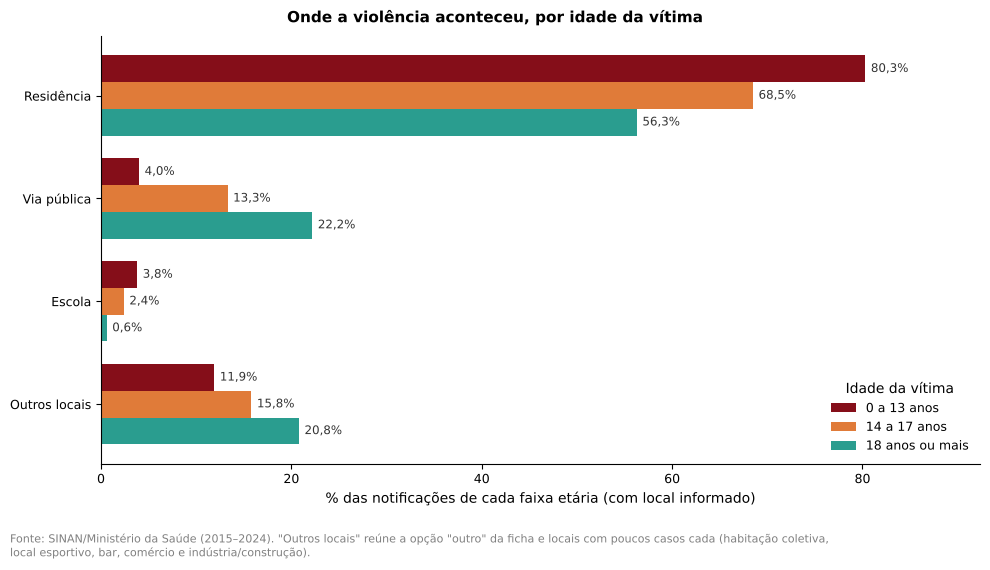

In [ ]:
# 1. Traduz os códigos do SINAN: local da ocorrência, repetição e número de agressores
mapa_local = {"1": "Residência", "2": "Habitação coletiva", "3": "Escola", "4": "Local de prática esportiva",
              "5": "Bar ou similar", "6": "Via pública", "7": "Comércio/serviços", "8": "Indústria/construção",
              "9": "Outro"}
sinan["LOCAL_NOME"] = limpa_codigo(sinan["LOCAL_OCOR"]).str.lstrip("0").map(mapa_local).fillna("Ignorado")
sinan["REPETICAO"] = limpa_codigo(sinan["OUT_VEZES"]).map({"1": "Sim", "2": "Não"}).fillna("Ignorado")
sinan["MULTIPLOS_AGRESSORES"] = limpa_codigo(sinan["NUM_ENVOLV"]).map({"1": "Um", "2": "Dois ou mais"}).fillna("Ignorado")

# 2. Distribuição dos locais dentro de cada faixa etária (só notificações com o local informado)
locais_principais = ["Residência", "Via pública", "Escola"]
validos = sinan[(sinan["LOCAL_NOME"] != "Ignorado") & sinan["FAIXA"].notna()]
pct_local = pd.crosstab(validos["FAIXA"], validos["LOCAL_NOME"], normalize="index") * 100
# "Outros locais": a opção "outro" da ficha mais os cinco locais com poucos casos cada
pct_local["Outros locais"] = pct_local.drop(columns=locais_principais, errors="ignore").sum(axis=1)
pct_local = pct_local.reindex(columns=locais_principais + ["Outros locais"], fill_value=0).round(1)
print(f"Notificações com o local informado: {len(validos) / sinan['FAIXA'].notna().sum() * 100:.1f}%")

# 3. Barras horizontais agrupadas: um grupo por local, uma barra por faixa etária
fig, ax = plt.subplots(figsize=(10, 5))
barras_por_faixa(ax, pct_local)
ax.set_xlabel("% das notificações de cada faixa etária (com local informado)")
ax.legend(title="Idade da vítima", frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (2015–2024). \"Outros locais\" reúne a opção \"outro\" da ficha e "
                   "locais com poucos casos cada (habitação coletiva,\nlocal esportivo, bar, comércio e "
                   "indústria/construção).")
titulo_na_imagem(fig, "Onde a violência aconteceu, por idade da vítima")
plt.savefig("../figures/p4_local_por_idade.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** A residência é o local mais comum em todas as idades, mas o peso dela cai conforme a vítima é mais velha: 80,3% dos casos entre crianças de 0 a 13 anos, 68,5% entre 14 e 17 anos e 56,3% entre mulheres adultas. A via pública faz o caminho inverso: 4,0% entre crianças, 13,3% entre adolescentes e 22,2% entre adultas. A escola aparece pouco, mesmo entre crianças (3,8%). O local foi informado em 89,6% das notificações.

**Como interpretar.** Para as crianças, a violência sexual notificada é sobretudo doméstica, o que dificulta que ela seja percebida e denunciada, já que o agressor costuma estar dentro de casa. Entre as adultas, os espaços públicos ganham peso.

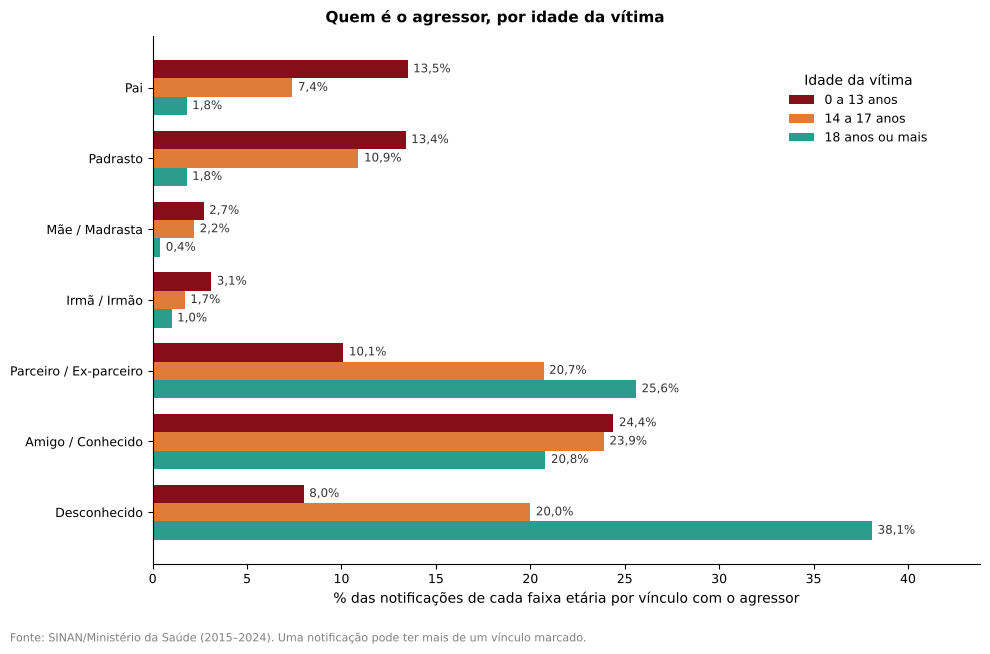

In [ ]:
# Vínculo com o agressor por faixa etária. Cada tipo de vínculo é um campo da ficha (1 = sim);
# juntamos campos parecidos e calculamos a % das notificações da faixa em que o vínculo foi marcado.
grupos_vinculo = {
    "Pai": ["REL_PAI"],
    "Padrasto": ["REL_PAD"],
    "Mãe / Madrasta": ["REL_MAE", "REL_MAD"],
    "Irmã / Irmão": ["REL_IRMAO"],  # a ficha tem um campo só para os dois
    "Parceiro / Ex-parceiro": ["REL_CONJ", "REL_EXCON", "REL_NAMO", "REL_EXNAM"],
    "Amigo / Conhecido": ["REL_CONHEC"],
    "Desconhecido": ["REL_DESCO"],
}
# campo marcado ("1") em cada notificação, calculado uma vez e reaproveitado na seção 8
rel_sim = pd.DataFrame({c: limpa_codigo(sinan[c]).eq("1") for c in sorted({c for cs in grupos_vinculo.values() for c in cs})})
marcado = pd.DataFrame({nome: rel_sim[colunas_rel].any(axis=1) for nome, colunas_rel in grupos_vinculo.items()})
com_faixa = sinan["FAIXA"].notna()
pct_vinc = (marcado[com_faixa].groupby(sinan.loc[com_faixa, "FAIXA"], observed=True).mean() * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 6))  # mais alto: agora são 7 vínculos
barras_por_faixa(ax, pct_vinc)
ax.set_xlabel("% das notificações de cada faixa etária por vínculo com o agressor")
ax.legend(title="Idade da vítima", frameon=False, loc="upper right", bbox_to_anchor=(0.95, 0.95))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (2015–2024). Uma notificação pode ter mais de um vínculo marcado.")
titulo_na_imagem(fig, "Quem é o agressor, por idade da vítima")
plt.savefig("../figures/p4_vinculo_por_idade.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** O agressor muda com a idade da vítima. Entre crianças de 0 a 13 anos, o pai (13,5%) e o padrasto (13,4%) somam 26,9% das notificações, e conhecidos ou amigos aparecem em 24,4%; desconhecidos, em só 8,0%. Entre mulheres adultas, o desconhecido é o vínculo mais frequente (38,1%), seguido do parceiro ou ex-parceiro (25,6%), e pai e padrasto quase desaparecem (1,8% cada). As adolescentes de 14 a 17 anos ficam no meio do caminho.

**Como interpretar.** Também chama a atenção que 10,1% das notificações de crianças tenham um parceiro ou ex-parceiro como agressor. Provavelmente são, em boa parte, namorados de meninas perto dos 13 anos, a idade com mais notificações (seção 3); pela lei, qualquer ato sexual com menor de 14 anos é estupro de vulnerável, haja ou não um namoro. Os percentuais de uma faixa não somam 100% porque uma notificação pode ter mais de um vínculo marcado, e vínculos menos frequentes (como cuidador ou patrão) não aparecem no gráfico.

Violência repetida: 49.4% das notificações com tal campo preenchido
Dois ou mais agressores: 14.3% das notificações com tal campo preenchido


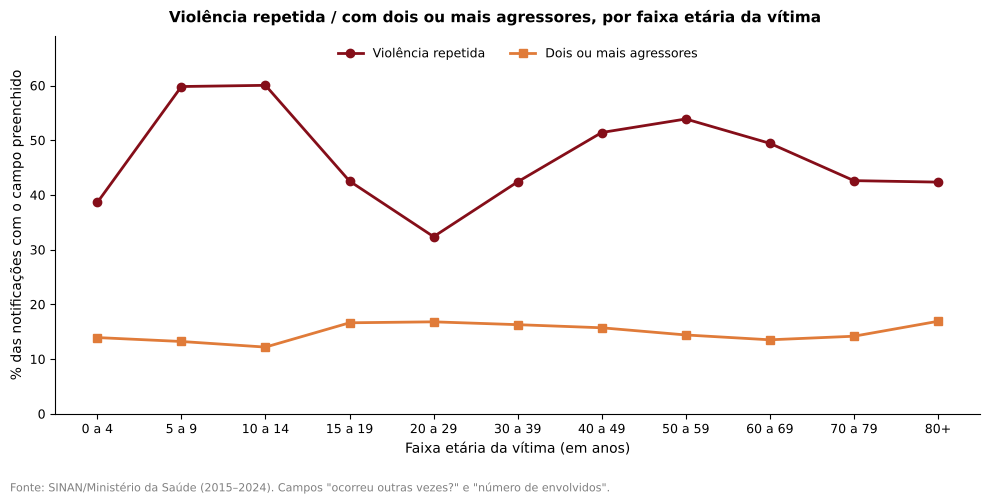

In [ ]:
# Violência repetida e dois ou mais agressores, por faixa etária de 5 ou 10 anos (coluna FAIXA_POP, da limpeza)
def pct_sim(coluna, valor_sim, valores_validos):
    d = sinan.loc[sinan[coluna].isin(valores_validos) & sinan["FAIXA_POP"].notna(), [coluna, "FAIXA_POP"]]
    return d[coluna].eq(valor_sim).groupby(d["FAIXA_POP"], observed=True).mean().mul(100).reindex(faixas_pop)

rep_pct = pct_sim("REPETICAO", "Sim", ["Sim", "Não"])
mult_pct = pct_sim("MULTIPLOS_AGRESSORES", "Dois ou mais", ["Um", "Dois ou mais"])
total_rep = (sinan.loc[sinan["REPETICAO"] != "Ignorado", "REPETICAO"] == "Sim").mean() * 100
total_mult = (sinan.loc[sinan["MULTIPLOS_AGRESSORES"] != "Ignorado", "MULTIPLOS_AGRESSORES"] == "Dois ou mais").mean() * 100
print(f"Violência repetida: {total_rep:.1f}% das notificações com tal campo preenchido")
print(f"Dois ou mais agressores: {total_mult:.1f}% das notificações com tal campo preenchido")

rotulos = [f.replace(" anos", "").replace(" e mais", "+") for f in faixas_pop]
# Versão estática (imagem salva na pasta figures, para o README e os slides). Fica visível no notebook porque o
# GitHub não mostra gráficos do plotly (JavaScript): sem ela, o notebook aberto no GitHub teria um espaço em branco
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rotulos, rep_pct.values, marker="o", lw=2, color=VERMELHO)
ax.plot(rotulos, mult_pct.values, marker="s", lw=2, color=LARANJA)
ax.set_ylim(0, max(rep_pct.max(), mult_pct.max()) * 1.15)
ax.set_xlim(-0.5, len(rotulos) - 0.5)
ax.set_xlabel("Faixa etária da vítima (em anos)")
ax.set_ylabel("% das notificações com o campo preenchido")
ax.legend(["Violência repetida", "Dois ou mais agressores"], frameon=False, loc="upper center", ncol=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (2015–2024). Campos \"ocorreu outras vezes?\" e \"número de envolvidos\".")
titulo_na_imagem(fig, "Violência repetida / com dois ou mais agressores, por faixa etária da vítima")
plt.savefig("../figures/p4_repeticao_multiplos_idade.png", dpi=200, bbox_inches="tight")
plt.show()

# Versão interativa (plotly): passe o mouse sobre um ponto para ver os valores exatos daquela faixa etária
# o balão mostra a faixa etária completa ("15 a 19 anos") e os dois valores dessa faixa
dados_balao = list(zip(faixas_pop, rep_pct.values, mult_pct.values))
balao = ("<b>%{customdata[0]}</b><br>Violência repetida: %{customdata[1]:.1f}%<br>"
         "Dois ou mais agressores: %{customdata[2]:.1f}%<extra></extra>")

fig_int = go.Figure()
for nome, serie, cor, simbolo in [("Violência repetida", rep_pct, VERMELHO, "circle"),
                                  ("Dois ou mais agressores", mult_pct, LARANJA, "square")]:
    fig_int.add_trace(go.Scatter(
        x=rotulos, y=serie.values, name=nome, mode="lines+markers", customdata=dados_balao,
        line=dict(color=cor, width=2.5), marker=dict(color=cor, size=8, symbol=simbolo), hovertemplate=balao))

# nota de fonte no rodapé, encostada na esquerda da imagem (xshift puxa a nota para a esquerda, para dentro da margem)
fig_int.add_annotation(text="Fonte: SINAN/Ministério da Saúde (2015–2024). Campos \"ocorreu outras vezes?\" e "
                            "\"número de envolvidos\".", xref="paper", yref="paper", x=0, xshift=-70, y=-0.28,
                       xanchor="left", yanchor="top", align="left", showarrow=False, font=dict(size=11, color="gray"))

fig_int.update_layout(
    width=900, height=470, template="simple_white", separators=",.", margin=dict(l=80, r=40, t=100, b=100),
    font=dict(family="DejaVu Sans, Verdana, Arial, sans-serif", size=13, color="#222222"),
    title=dict(text="<b>Violência repetida / com dois ou mais agressores, por faixa etária da vítima</b>",
               x=0.5, xanchor="center", y=0.96, yanchor="top", font=dict(size=15, color="black")),
    legend=dict(orientation="h", x=0.5, xanchor="center", y=1.02, yanchor="bottom"),
    hovermode="closest", hoverlabel=dict(bgcolor="white", font_size=12),
    xaxis=dict(title="Faixa etária da vítima (em anos)"),
    yaxis=dict(title="% das notificações com o campo preenchido", ticksuffix="%",
               range=[0, max(rep_pct.max(), mult_pct.max()) * 1.15]),
)
fig_int.show()

**O que o gráfico mostra.** Em 49,4% das notificações com o campo preenchido, a violência já tinha acontecido antes, e em 14,3% havia dois ou mais agressores. A repetição varia muito com a idade: chega a 60% entre 5 e 14 anos, cai para 32,4% entre 20 e 29 anos e volta a subir depois dos 40 (53,9% entre 50 e 59). A proporção de dois ou mais agressores varia menos, entre 12% e 17%, e é um pouco maior entre 15 e 29 anos e acima dos 80.

**Como interpretar.** A repetição alta entre crianças é coerente com uma violência doméstica e cometida por pessoas próximas: o abuso tende a se prolongar até ser revelado. Entre as adultas jovens, predominam episódios isolados, mais ligados a desconhecidos e a espaços públicos. A violência com dois ou mais agressores, como a do caso que motivou este trabalho, não é rara: aparece em cerca de uma em cada sete notificações.

### Síntese da pergunta 4

A violência sexual notificada contra crianças acontece sobretudo em casa, é cometida por pais, padrastos e conhecidos e costuma se repetir. Entre as adultas, crescem o peso dos desconhecidos, dos parceiros e da via pública, e a violência é mais frequentemente um episódio isolado.

## 5. Como as taxas se distribuem entre estados e municípios? Elas diferem entre municípios mais pobres e mais ricos, ou mais urbanos e mais rurais?

**Pergunta de dados:** quais estados e municípios concentram mais notificações e quais têm as maiores taxas por 100 mil mulheres? A taxa muda entre municípios de renda mais baixa e mais alta, entre municípios pequenos e grandes e entre capitais e interior?

**Transformação:** começamos pelo volume, contando as notificações por estado e por município, e depois passamos para as taxas. Para as taxas municipais, usamos o município de residência da vítima, e não o município em que o caso foi notificado: cidades com hospitais de referência atendem vítimas de toda a região, o que inflaria as suas taxas. A população feminina vem do Censo 2022 (SIDRA 9514), e a renda domiciliar per capita média de cada município, também do Censo 2022 (SIDRA 10295). Para comparar municípios mais pobres e mais ricos, dividimos os municípios em cinco grupos com o mesmo número de municípios (quintos), do de menor ao de maior renda. Não usamos a situação urbana ou rural do domicílio; como aproximação do grau de urbanização, comparamos o porte do município e as capitais com o interior.

**Cuidado:** as comparações por renda e porte são entre municípios, não entre pessoas. Uma taxa maior nos municípios mais ricos, por exemplo, não quer dizer que as vítimas sejam mais ricas, e pode refletir uma rede de saúde que notifica mais.

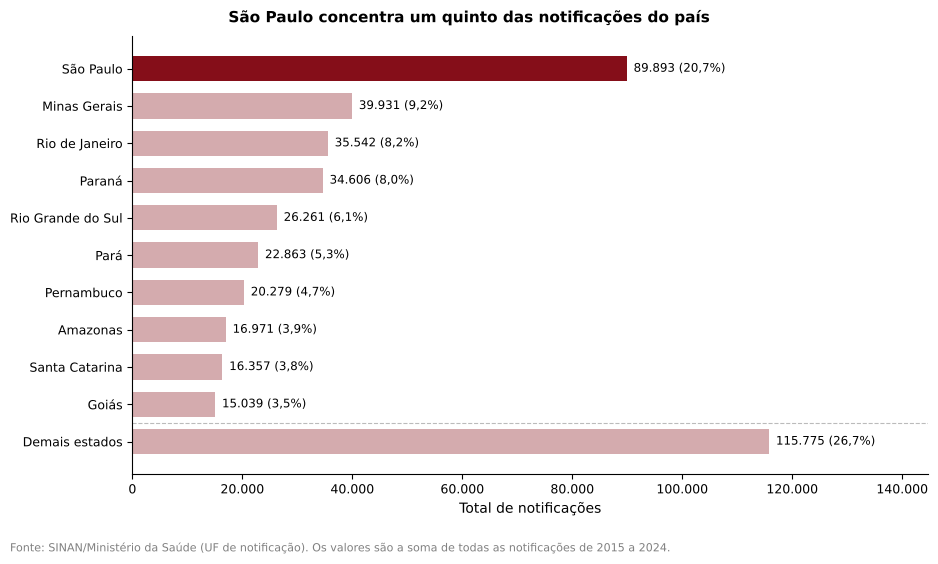

In [ ]:
# Dicionário IBGE de códigos para nomes de UF
nomes_uf = {
    11: "Rondônia", 12: "Acre", 13: "Amazonas", 14: "Roraima", 15: "Pará",
    16: "Amapá", 17: "Tocantins", 21: "Maranhão", 22: "Piauí", 23: "Ceará",
    24: "Rio Grande do Norte", 25: "Paraíba", 26: "Pernambuco", 27: "Alagoas",
    28: "Sergipe", 29: "Bahia", 31: "Minas Gerais", 32: "Espírito Santo",
    33: "Rio de Janeiro", 35: "São Paulo", 41: "Paraná", 42: "Santa Catarina",
    43: "Rio Grande do Sul", 50: "Mato Grosso do Sul", 51: "Mato Grosso",
    52: "Goiás", 53: "Distrito Federal"
}

# 1. Ranking de notificações por estado (2015–2024)
ranking_uf = (
    sinan.groupby("COD_UF").size()
    .reset_index(name="notificacoes")
    .astype({"COD_UF": int})
    .sort_values("notificacoes", ascending=False)
)
ranking_uf["Estado"] = ranking_uf["COD_UF"].map(nomes_uf)
ranking_uf["pct_brasil"] = (ranking_uf["notificacoes"] / ranking_uf["notificacoes"].sum() * 100).round(1)

# Extrai automaticamente o Top 3 estados
top3_df = ranking_uf.head(3)
top3_ufs = list(zip(top3_df["COD_UF"], top3_df["Estado"]))

# 2. Gráfico de barras do Top 10 estados destacando o estado com mais notificações (São Paulo),
#    com uma barra a mais, embaixo, somando todos os demais estados
top10_plot = ranking_uf.head(10).sort_values("notificacoes")
demais = ranking_uf.iloc[10:]
barra_demais = pd.DataFrame({
    "COD_UF": [0], "Estado": ["Demais estados"], "notificacoes": [demais["notificacoes"].sum()],
    "pct_brasil": [round(demais["notificacoes"].sum() / ranking_uf["notificacoes"].sum() * 100, 1)]})
dados_plot = pd.concat([barra_demais, top10_plot], ignore_index=True)  # a primeira linha vira a barra de baixo
cores_uf = [VERMELHO if c == ranking_uf["COD_UF"].iloc[0] else VERMELHO_CLARO for c in dados_plot["COD_UF"]]

fig, ax = plt.subplots(figsize=(9.5, 5.1))
barras = ax.barh(dados_plot["Estado"], dados_plot["notificacoes"], color=cores_uf, height=0.68)
for b, (_, row) in zip(barras, dados_plot.iterrows()):
    ax.annotate(f"{ptbr(row['notificacoes'], 0)} ({ptbr(row['pct_brasil'])}%)", (b.get_width(), b.get_y() + b.get_height() / 2),
                textcoords="offset points", xytext=(5, 0), va="center", fontsize=8.5)
# linha separando os 10 estados da soma dos demais
ax.axhline(0.5, color="#BBBBBB", linestyle="--", linewidth=0.8)

ax.set_xlabel("Total de notificações")
ax.set_xlim(0, dados_plot["notificacoes"].max() * 1.25)
ax.xaxis.set_major_formatter(fmt_milhar)
plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (UF de notificação). Os valores são a soma de todas as notificações "
                   "de 2015 a 2024.")
titulo_na_imagem(fig, "São Paulo concentra um quinto das notificações do país")
plt.savefig("../figures/p5_top_estados_volume.png", dpi=200, bbox_inches="tight")
plt.show()

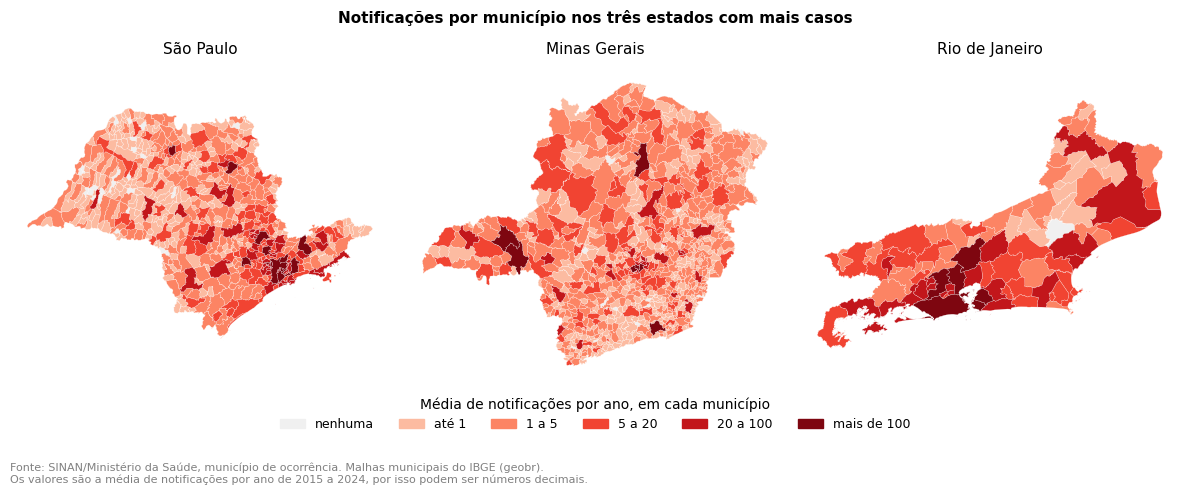

In [ ]:
# 1. Média anual de notificações por município de OCORRÊNCIA (6 dígitos)
notif_mun_ocor = sinan.groupby("MUN_OCOR").size().div(N_ANOS).rename("media_anual").rename_axis("COD_MUN_6").reset_index()

# Classes fixas, iguais nos três estados, para que as cores sejam comparáveis
limites = [-0.001, 0, 1, 5, 20, 100, np.inf]
classes = ["nenhuma", "até 1", "1 a 5", "5 a 20", "20 a 100", "mais de 100"]
cores_classe = dict(zip(classes, ["#F0F0F0"] + [plt.cm.Reds(v) for v in [0.25, 0.42, 0.6, 0.78, 0.95]]))

# 2. Mapas municipais dos três estados com mais notificações
fig, eixos = plt.subplots(1, 3, figsize=(12, 4.6))
malhas = {}
for ax, (cod_uf, nome_uf) in zip(eixos, top3_ufs):
    malha = geobr.read_municipality(code_muni=cod_uf, year=2020)
    malha["COD_MUN_6"] = malha["code_muni"].astype(int).astype(str).str.slice(0, 6)
    malhas[cod_uf] = malha
    mapa_uf = malha.merge(notif_mun_ocor, on="COD_MUN_6", how="left")
    mapa_uf["classe"] = pd.cut(mapa_uf["media_anual"].fillna(0), bins=limites, labels=classes)
    for classe in classes:
        parte = mapa_uf[mapa_uf["classe"] == classe]
        if len(parte):
            parte.plot(ax=ax, color=cores_classe[classe], edgecolor="white", linewidth=0.15)
    ax.set_title(nome_uf, fontsize=11)
    ax.axis("off")
plt.tight_layout(rect=(0, 0.12, 1, 1))

# Cada estado tem um formato, então cada mapa fica com uma altura; os três ficam centralizados na vertical, uns em
# relação aos outros. Os subtítulos vão todos para a mesma altura: 10 pontos acima do topo do mapa mais alto
fig.canvas.draw()
topo_mapas = max(ax.get_position().y1 for ax in eixos)
base_mapas = min(ax.get_position().y0 for ax in eixos)
for ax, (cod_uf, nome_uf) in zip(eixos, top3_ufs):
    pos = ax.get_position()
    ax.set_title(nome_uf, fontsize=11, y=(topo_mapas - pos.y0) / pos.height)

# legenda logo abaixo dos mapas, centralizada na imagem
fig.legend(handles=[Patch(color=cores_classe[c], label=c) for c in classes], loc="upper center", ncol=6,
           bbox_to_anchor=(centro_da_imagem(fig), base_mapas - 4 / 72 / fig.get_figheight()),
           title="Média de notificações por ano, em cada município", fontsize=9)
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde, município de ocorrência. Malhas municipais do IBGE (geobr).\n"
                   "Os valores são a média de notificações por ano de 2015 a 2024, por isso podem ser números decimais.")
centraliza_subtitulos(fig, eixos)
titulo = titulo_na_imagem(fig, "Notificações por município nos três estados com mais casos")
titulo.set_y(titulo.get_position()[1] + 4 / 72 / fig.get_figheight())  # 4 pontos a mais entre o título e os subtítulos
plt.savefig("../figures/p5_mapas_municipios_top3.png", dpi=200, bbox_inches="tight")
plt.show()

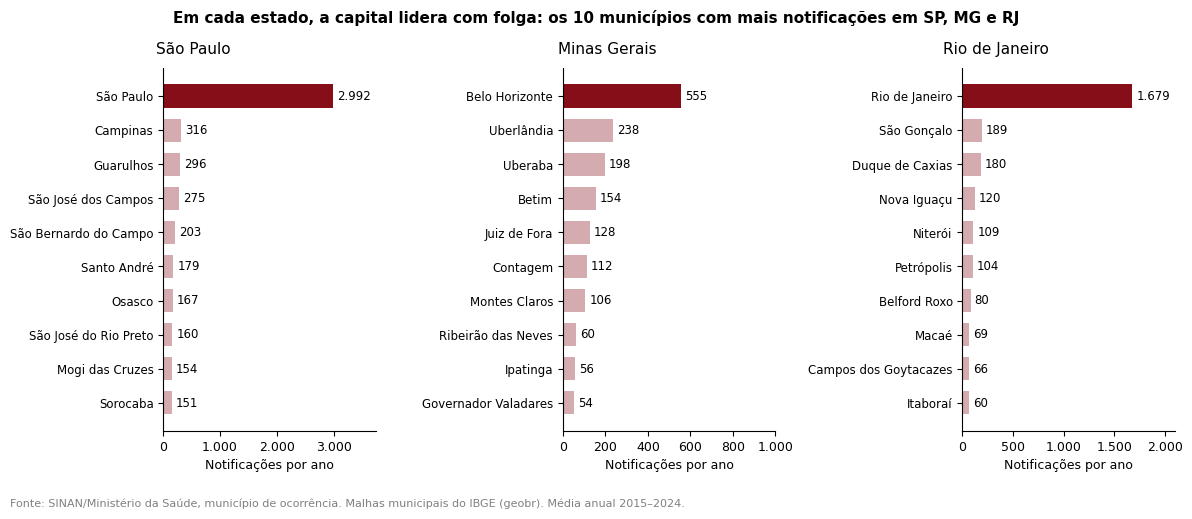

In [ ]:
# 3. Os 10 municípios com mais notificações em cada um desses estados
fig, eixos = plt.subplots(1, 3, figsize=(12, 4.6))
for ax, (cod_uf, nome_uf) in zip(eixos, top3_ufs):
    malha = malhas[cod_uf]
    nomes = dict(zip(malha["COD_MUN_6"], malha["name_muni"]))
    top10_mun = (notif_mun_ocor[notif_mun_ocor["COD_MUN_6"].str.startswith(str(cod_uf))]
                 .assign(nome=lambda d: d["COD_MUN_6"].map(nomes)).dropna(subset=["nome"])
                 .nlargest(10, "media_anual").sort_values("media_anual"))
    cores_bar = [VERMELHO_CLARO] * (len(top10_mun) - 1) + [VERMELHO]
    barras = ax.barh(top10_mun["nome"], top10_mun["media_anual"], color=cores_bar, height=0.68)
    for b, v in zip(barras, top10_mun["media_anual"]):
        ax.annotate(ptbr(v, 0), (v, b.get_y() + b.get_height() / 2), textcoords="offset points", xytext=(3, 0),
                    va="center", fontsize=8.5)
    ax.set_title(nome_uf, fontsize=11)
    # Minas Gerais com o eixo x até 1.000; os outros estados, até 25% além da maior barra
    ax.set_xlim(0, 1000 if nome_uf == "Minas Gerais" else top10_mun["media_anual"].max() * 1.25)
    ax.xaxis.set_major_formatter(fmt_milhar)
    ax.tick_params(axis="y", labelsize=8.5)
    ax.set_xlabel("Notificações por ano", fontsize=9)
plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde, município de ocorrência. Malhas municipais do IBGE (geobr). "
                   "Média anual 2015–2024.")
centraliza_subtitulos(fig, eixos)
titulo = titulo_na_imagem(fig, "Em cada estado, a capital lidera com folga: os 10 municípios com mais notificações em SP, MG e RJ")
titulo.set_y(titulo.get_position()[1] + 4 / 72 / fig.get_figheight())  # 4 pontos a mais entre o título e os subtítulos
plt.savefig("../figures/p5_top3_estados_e_top10_municipios.png", dpi=200, bbox_inches="tight")
plt.show()

**O que os gráficos mostram.** Em volume, as notificações se concentram nos estados mais populosos: São Paulo responde por 20,7% do total de 2015 a 2024, seguido de Minas Gerais (9,2%) e do Rio de Janeiro (8,2%). Dentro desses estados, as capitais lideram com folga: a cidade de São Paulo registra, em média, cerca de 2.950 notificações por ano; o Rio de Janeiro, cerca de 1.650; e Belo Horizonte, cerca de 545.

**Como interpretar.** Esses números mostram onde está o volume de atendimentos, mas não onde o risco é maior, porque dependem do tamanho da população. Por isso, a seguir passamos às taxas.

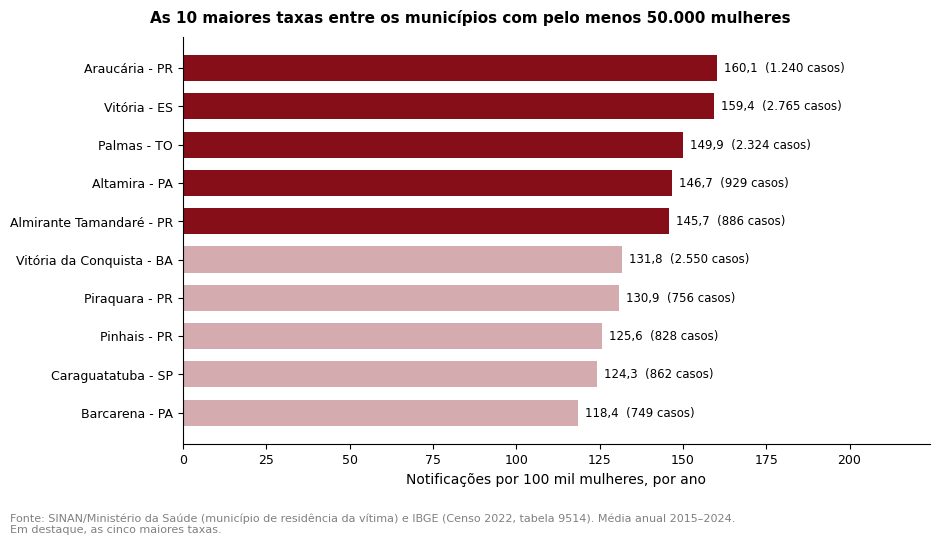

In [ ]:
# 1. Usa o município de RESIDÊNCIA da vítima (coluna MUN_RESI), para que cidades com hospitais de referência
#    não tenham a taxa inflada

# 2. Baixa população feminina por município (Censo 2022 - IBGE SIDRA tabela 9514, sexo=Feminino)
url_sidra = "https://apisidra.ibge.gov.br/values/t/9514/n6/all/v/93/p/2022/c2/5"
resp = requests.get(url_sidra, timeout=60).json()

pop_mun = pd.DataFrame(resp[1:])[["D1C", "D1N", "V"]].rename(
    columns={"D1C": "COD_MUN_7", "D1N": "MUNICIPIO_UF", "V": "pop_feminina_2022"}
)
pop_mun["COD_MUN_6"] = pop_mun["COD_MUN_7"].astype(str).str.slice(0, 6)
pop_mun["pop_feminina_2022"] = pd.to_numeric(pop_mun["pop_feminina_2022"], errors="coerce")
pop_mun = pop_mun.dropna(subset=["pop_feminina_2022"]).drop_duplicates(subset=["COD_MUN_6"])

# 3. Agrega notificações por município e calcula a taxa média anual (por 100 mil mulheres)
notif_mun = sinan.groupby("MUN_RESI").size().rename_axis("COD_MUN_6").reset_index(name="notificacoes_total")
df_mun = pop_mun.merge(notif_mun, on="COD_MUN_6", how="left")
df_mun["notificacoes_total"] = df_mun["notificacoes_total"].fillna(0).astype(int)
df_mun["media_anual"] = df_mun["notificacoes_total"] / N_ANOS
df_mun["taxa_100mil_ano"] = (df_mun["media_anual"] / df_mun["pop_feminina_2022"] * 100_000).round(1)

# 4. Filtra municípios com pelo menos 50 mil mulheres (~100 mil hab.) para evitar distorção de cidades muito pequenas
POP_MINIMA = 50_000
df_mun_porte = df_mun[df_mun["pop_feminina_2022"] >= POP_MINIMA].copy()
top10_taxa = df_mun_porte.nlargest(10, "taxa_100mil_ano").sort_values("taxa_100mil_ano")

# --- GRÁFICO 1: as 10 maiores taxas ---
fig, ax = plt.subplots(figsize=(9.5, 4.8))  # altura menor: 10 barras em vez de 15
cores = [VERMELHO_CLARO] * (len(top10_taxa) - 5) + [VERMELHO] * 5
barras = ax.barh(top10_taxa["MUNICIPIO_UF"], top10_taxa["taxa_100mil_ano"], color=cores, height=0.68)
for b, (_, row) in zip(barras, top10_taxa.iterrows()):
    ax.annotate(f"{ptbr(row['taxa_100mil_ano'])}  ({ptbr(row['notificacoes_total'], 0)} casos)",
                (b.get_width(), b.get_y() + b.get_height() / 2),
                textcoords="offset points", xytext=(5, 0), va="center", fontsize=8.5)
ax.set_xlabel("Notificações por 100 mil mulheres, por ano")
ax.set_xlim(0, top10_taxa["taxa_100mil_ano"].max() * 1.4)
plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (município de residência da vítima) e IBGE (Censo 2022, tabela 9514). "
                   "Média anual 2015–2024.\nEm destaque, as cinco maiores taxas.")
titulo_na_imagem(fig, f"As 10 maiores taxas entre os municípios com pelo menos {ptbr(POP_MINIMA, 0)} mulheres")
plt.savefig("../figures/p5_cidades_maior_taxa.png", dpi=200, bbox_inches="tight")
plt.show()

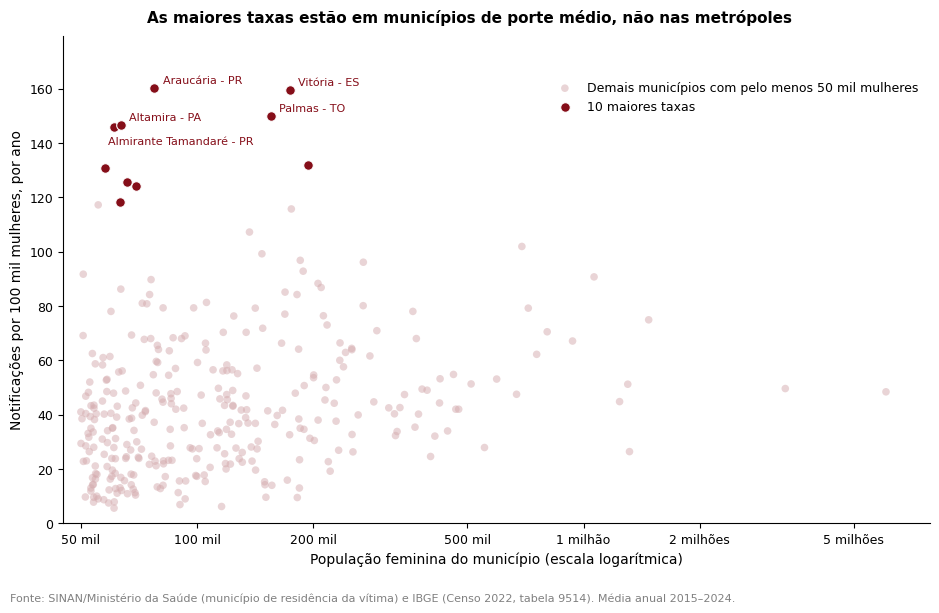

In [ ]:
# --- GRÁFICO 2: população feminina × taxa, com as 10 maiores taxas destacadas ---
fig, ax = plt.subplots(figsize=(9.5, 5.6))
ax.scatter(df_mun_porte["pop_feminina_2022"], df_mun_porte["taxa_100mil_ano"], alpha=0.5, color=VERMELHO_CLARO,
           edgecolors="none", s=30, label="Demais municípios com pelo menos 50 mil mulheres")
ax.scatter(top10_taxa["pop_feminina_2022"], top10_taxa["taxa_100mil_ano"], color=VERMELHO, s=48, zorder=3,
           edgecolors="white", linewidths=0.8, label="10 maiores taxas")
ax.set_xscale("log")
marcas = [50_000, 100_000, 200_000, 500_000, 1_000_000, 2_000_000, 5_000_000]
ax.set_xticks(marcas, ["50 mil", "100 mil", "200 mil", "500 mil", "1 milhão", "2 milhões", "5 milhões"])
ax.minorticks_off()
ax.set_xlim(45_000, df_mun_porte["pop_feminina_2022"].max() * 1.3)
ax.set_ylim(0, df_mun_porte["taxa_100mil_ano"].max() * 1.12)
legenda = ax.legend(loc="upper right", bbox_to_anchor=(1, 0.93))  # um pouco abaixo do topo do gráfico
ax.set_xlabel("População feminina do município (escala logarítmica)")
ax.set_ylabel("Notificações por 100 mil mulheres, por ano")
plt.tight_layout()
# nome das cinco maiores taxas (depois do layout, para medir certo)
cinco_maiores = top10_taxa.tail(5)
sem_lugar = rotulos_sem_sobrepor(ax, cinco_maiores["pop_feminina_2022"], cinco_maiores["taxa_100mil_ano"],
                                 cinco_maiores["MUNICIPIO_UF"], tamanho=8, cor=VERMELHO, evitar=[legenda])
# Um ponto colado em outro (como Almirante Tamandaré, ao lado de Altamira) pode ficar sem lugar para o nome perto dele.
# Nesse caso, o nome vai logo abaixo do ponto, começando embaixo dele, sem traço
for _, row in cinco_maiores[cinco_maiores["MUNICIPIO_UF"].isin(sem_lugar)].iterrows():
    ax.annotate(row["MUNICIPIO_UF"], (row["pop_feminina_2022"], row["taxa_100mil_ano"]), xytext=(-4, -6),
                textcoords="offset points", ha="left", va="top", fontsize=8, color=VERMELHO)
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (município de residência da vítima) e IBGE (Censo 2022, tabela 9514). "
                   "Média anual 2015–2024.")
titulo_na_imagem(fig, "As maiores taxas estão em municípios de porte médio, não nas metrópoles")
plt.savefig("../figures/p5_cidades_maior_taxa_populacao.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** Pelo município de residência, entre os municípios com pelo menos 50 mil mulheres, as maiores taxas estão em Araucária (PR, 160,1 notificações por 100 mil mulheres por ano), Vitória (ES, 159,4), Palmas (TO, 149,9), Altamira (PA, 146,7) e Almirante Tamandaré (PR, 145,7). A região metropolitana de Curitiba chama a atenção: Araucária, Almirante Tamandaré, Piraquara e Pinhais estão entre as dez maiores taxas. No gráfico de dispersão, todas as 10 maiores taxas estão em municípios com menos de 200 mil mulheres; nenhuma grande cidade aparece entre elas.

**Como interpretar.** Uma taxa municipal alta pode indicar mais violência, mas também uma rede local mais ativa na identificação e na notificação. O fato de cidades vizinhas de Curitiba aparecerem juntas, por exemplo, sugere uma rede regional que notifica muito, hipótese que estes dados não permitem confirmar.

In [ ]:
# 1. Nomes dos municípios de NOTIFICAÇÃO (coluna MUN_NOTIF), da tabela de população do IBGE baixada acima
mapa_mun_nome = dict(zip(pop_mun["COD_MUN_6"], pop_mun["MUNICIPIO_UF"]))
nome_notif = sinan["MUN_NOTIF"].map(mapa_mun_nome)

# 2. As 5 cidades com mais notificações no país, ano a ano
top5_cidades_cod = sinan.loc[nome_notif.notna(), "MUN_NOTIF"].value_counts().head(5).index.tolist()
no_top5 = sinan["MUN_NOTIF"].isin(top5_cidades_cod)
df_top5_br = (
    pd.DataFrame({"ANO": sinan.loc[no_top5, "ANO"], "MUN_NOME_UF": nome_notif[no_top5]})
    .groupby(["ANO", "MUN_NOME_UF"]).size()
    .unstack(fill_value=0)
)
df_top5_br = df_top5_br[df_top5_br.sum().sort_values(ascending=False).index]

# 3. Versão estática (imagem salva na pasta figures, para o README e os slides): uma linha por cidade, com o nome e o
#    valor de 2024 no fim de cada linha. Fica visível no notebook porque o GitHub não mostra gráficos do plotly
cores_cidades = [VERMELHO, LARANJA, VERDE, AZUL, "#C9A227"]
fig, ax = plt.subplots(figsize=(10, 6.5))  # mais alto, para os pontos não ficarem tão encostados
ax.axvspan(2019.4, 2020.6, color="gray", alpha=0.12)  # mesma largura do gráfico 1
ax.text(2020, df_top5_br.values.max() * 1.06, "Pandemia", ha="center", fontsize=9, color=CINZA)
for cidade, cor in zip(df_top5_br.columns, cores_cidades):
    ax.plot(df_top5_br.index, df_top5_br[cidade], marker="o", linewidth=2, color=cor, label=cidade)
ax.set_xlabel("Ano da notificação")
ax.set_ylabel("Número de notificações")
ax.set_xticks(df_top5_br.index)
ax.set_xlim(df_top5_br.index.min() - 0.4, df_top5_br.index.max() + 1.9)
ax.set_ylim(0, df_top5_br.values.max() * 1.15)
ax.yaxis.set_major_formatter(fmt_milhar)
ax.legend(loc="upper left", bbox_to_anchor=(0.03, 1))  # um pouco para a direita
plt.tight_layout()
ultimo = df_top5_br.index.max()
rotulos_fim_de_linha(ax, ultimo, df_top5_br.loc[ultimo].to_numpy(),
                     [f"{c.split(' - ')[0]}: {ptbr(v, 0)}" for c, v in df_top5_br.loc[ultimo].items()], cores_cidades)
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (2015–2024), município de notificação. As cinco cidades com mais "
                   "notificações no período.")
titulo_na_imagem(fig, "Notificações por ano nas cinco cidades com mais casos")
plt.savefig("../figures/p5_evolucao_top_cidades.png", dpi=200, bbox_inches="tight")
plt.show()

# 4. Versão interativa (plotly): passe o mouse sobre um ponto para ver o número de notificações daquela cidade naquele ano
ALTURA, MARGEM_CIMA, MARGEM_BAIXO = 650, 100, 100  # mais alto, para os pontos não ficarem tão encostados
y_max = df_top5_br.values.max() * 1.15

fig_int = go.Figure()
for cidade, cor in zip(df_top5_br.columns, cores_cidades):
    fig_int.add_trace(go.Scatter(
        x=df_top5_br.index, y=df_top5_br[cidade], name=cidade, mode="lines+markers",
        line=dict(color=cor, width=2.5), marker=dict(color=cor, size=8),
        hovertemplate="<b>" + cidade + "</b><br>Ano: %{x}<br>Nº de notificações: %{y:,.0f}<extra></extra>"))

# faixa cinza da pandemia (2020), com a mesma largura do gráfico 1
fig_int.add_vrect(x0=2019.4, x1=2020.6, fillcolor="gray", opacity=0.12, line_width=0, layer="below")
fig_int.add_annotation(x=2020, y=df_top5_br.values.max() * 1.06, text="Pandemia", showarrow=False,
                       font=dict(size=12, color=CINZA))

# nome e valor de 2024 no fim de cada linha, afastados na vertical (pelo menos 15 pixels) para não se sobreporem
valores_fim = df_top5_br.loc[ultimo].sort_values()
espaco = 15 * y_max / (ALTURA - MARGEM_CIMA - MARGEM_BAIXO)  # 15 pixels, em unidades do eixo y
pos = espalha_posicoes(valores_fim.to_numpy(), espaco, tolerancia=1e-9)
cor_da_cidade = dict(zip(df_top5_br.columns, cores_cidades))
for (cidade, valor), y_rotulo in zip(valores_fim.items(), pos):
    deslocamento = (y_rotulo - valor) / y_max * (ALTURA - MARGEM_CIMA - MARGEM_BAIXO)  # em pixels
    fig_int.add_annotation(x=ultimo, y=valor, text=f"<b>{cidade.split(' - ')[0]}: {ptbr(valor, 0)}</b>",
                           showarrow=True, arrowhead=0, arrowwidth=0.8, arrowcolor=cor_da_cidade[cidade],
                           ax=14, ay=-deslocamento, xanchor="left", font=dict(size=11, color=cor_da_cidade[cidade]))

# nota de fonte no rodapé, encostada na esquerda da imagem (xshift puxa a nota para a esquerda, para dentro da margem)
# e 76 pixels abaixo do gráfico (yshift), qualquer que seja a altura da figura
fig_int.add_annotation(text="Fonte: SINAN/Ministério da Saúde (2015–2024), município de notificação. As cinco cidades "
                            "com mais notificações no período.", xref="paper", yref="paper", x=0, xshift=-70, y=0, yshift=-76,
                       xanchor="left", yanchor="top", align="left", showarrow=False, font=dict(size=11, color="gray"))

fig_int.update_layout(
    width=1100, height=ALTURA, template="simple_white", separators=",.",
    margin=dict(l=80, r=40, t=MARGEM_CIMA, b=MARGEM_BAIXO),
    font=dict(family="DejaVu Sans, Verdana, Arial, sans-serif", size=13, color="#222222"),
    title=dict(text="<b>Notificações por ano nas cinco cidades com mais casos</b>",
               x=0.5, xanchor="center", y=0.96, yanchor="top", font=dict(size=15, color="black")),
    legend=dict(x=0.04, xanchor="left", y=0.99, yanchor="top", bgcolor="rgba(0,0,0,0)"),  # um pouco para a direita
    hovermode="closest", hoverlabel=dict(bgcolor="white", font_size=12),
    xaxis=dict(title="Ano da notificação", tickmode="array", tickvals=list(df_top5_br.index),
               range=[df_top5_br.index.min() - 0.4, df_top5_br.index.max() + 1.9]),
    yaxis=dict(title="Número de notificações", range=[0, y_max], tickformat=",.0f"),
)
fig_int.show()

**O que o gráfico mostra.** Entre as cidades com mais notificações, o caso que mais chama a atenção é São Paulo: a cidade mais que dobra as notificações de 2022 para 2023 e chega a 8.187 em 2024. O Rio de Janeiro também cresce de forma contínua desde 2020, até 3.294 notificações em 2024.

**Como interpretar.** Um salto tão grande de um ano para o outro, numa só cidade, é mais compatível com uma mudança na forma de notificar, como mais serviços passando a notificar, do que com uma mudança tão rápida na violência. Como a cidade de São Paulo responde por 7,7% de todas as notificações do período, esse salto também pesa na alta nacional de 2023 vista na seção 1.

Município usado: ID_MN_RESI | taxa média do Brasil: 41.5 por 100 mil mulheres por ano

Renda: Valor do rendimento nominal médio mensal domiciliar per capita dos moradores em domicílios particulares permanentes ocupados, exclusive os cuja condição no domicílio era pensionista, empregado(a) doméstico(a) ou parente do(a) empregado(a) doméstico(a) (5570 municípios)
                             min     max
quinto_renda                            
1º quinto\n(mais pobres)   289.0   735.0
2º quinto                  735.0   982.0
3º quinto                  982.0  1328.0
4º quinto                 1328.0  1603.0
5º quinto\n(mais ricos)   1603.0  4300.0 

Renda 
                           municipios  notificacoes  pop_feminina  taxa_100mil_ano
quinto_renda                                                                     
1º quinto\n(mais pobres)        1114       26501.0       9430253             28.1
2º quinto                       1114       33681.0      11742660             28.7
3º quinto  

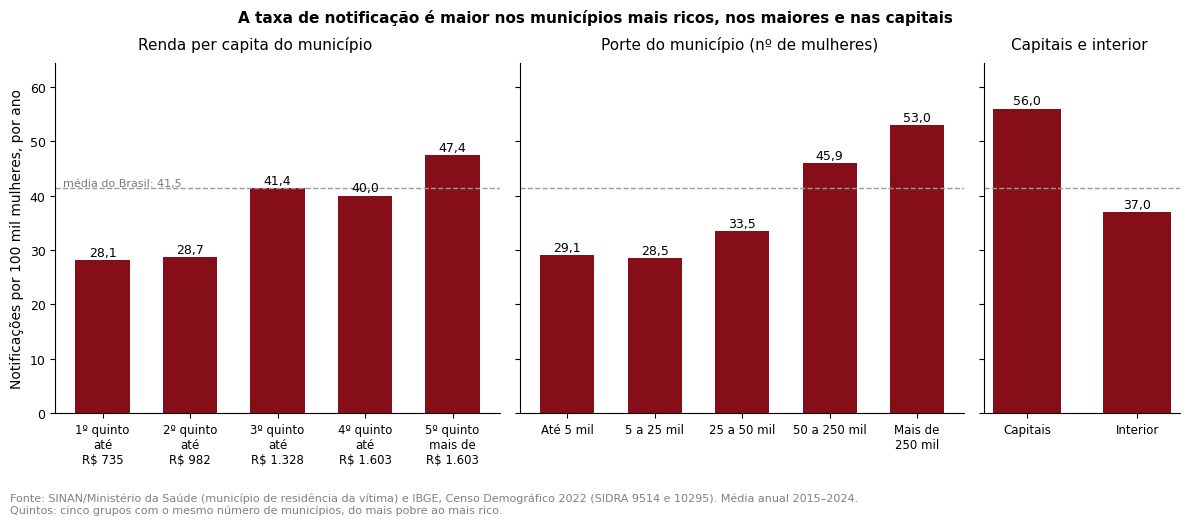

In [ ]:
# Taxas pelo município de RESIDÊNCIA da vítima, agrupando os municípios por renda, porte e capital/interior
notif_res = sinan["MUN_RESI"].value_counts().rename("notificacoes_total")
mun = pop_mun[["COD_MUN_6", "MUNICIPIO_UF", "pop_feminina_2022"]].merge(
    notif_res, left_on="COD_MUN_6", right_index=True, how="left")
mun["notificacoes_total"] = mun["notificacoes_total"].fillna(0)
taxa_brasil_res = mun["notificacoes_total"].sum() / N_ANOS / mun["pop_feminina_2022"].sum() * 100_000
print(f"Município usado: ID_MN_RESI | taxa média do Brasil: {taxa_brasil_res:.1f} por 100 mil mulheres por ano\n")

def taxa_por_grupo(coluna):
    g = mun.groupby(coluna, observed=True).agg(municipios=("COD_MUN_6", "size"),
                                               notificacoes=("notificacoes_total", "sum"),
                                               pop_feminina=("pop_feminina_2022", "sum"))
    g["taxa_100mil_ano"] = (g["notificacoes"] / N_ANOS / g["pop_feminina"] * 100_000).round(1)
    return g

# (a) Renda domiciliar per capita média de cada município (Censo 2022, SIDRA 10295)
try:
    meta = requests.get("https://servicodados.ibge.gov.br/api/v3/agregados/10295/metadados", timeout=60).json()
    var_renda = next(v for v in meta["variaveis"] if "per capita" in v["nome"].lower() and "médi" in v["nome"].lower())
    resp = requests.get(f"https://apisidra.ibge.gov.br/values/t/10295/n6/all/v/{var_renda['id']}/p/2022", timeout=180).json()
    renda = pd.DataFrame(resp[1:])
    col_cod = next(c for c in renda.columns if c.endswith("C") and renda[c].astype(str).str.len().eq(7).mean() > 0.9)
    renda = pd.DataFrame({"COD_MUN_6": renda[col_cod].astype(str).str.slice(0, 6),
                          "renda_pc": pd.to_numeric(renda["V"], errors="coerce")}).dropna()
    mun = mun.merge(renda, on="COD_MUN_6", how="left")
    mun["quinto_renda"] = pd.qcut(mun["renda_pc"], 5, labels=["1º quinto\n(mais pobres)", "2º quinto", "3º quinto",
                                                              "4º quinto", "5º quinto\n(mais ricos)"])
    print(f"Renda: {var_renda['nome']} ({mun['renda_pc'].notna().sum()} municípios)")
    print(mun.groupby("quinto_renda", observed=True)["renda_pc"].agg(["min", "max"]).round(0).to_string(), "\n")
    tab_renda = taxa_por_grupo("quinto_renda")
except Exception as erro:
    print("Não foi possível baixar a renda municipal do SIDRA:", erro, "\n")
    tab_renda = None

# (b) Porte do município, pela população feminina (aproximação do grau de urbanização)
mun["porte"] = pd.cut(mun["pop_feminina_2022"], bins=[0, 5_000, 25_000, 50_000, 250_000, np.inf],
                      labels=["Até 5 mil", "5 a 25 mil", "25 a 50 mil", "50 a 250 mil", "Mais de\n250 mil"])
tab_porte = taxa_por_grupo("porte")

# (c) Capitais × interior
capitais_6 = {"110020", "120040", "130260", "140010", "150140", "160030", "172100", "211130", "221100",
              "230440", "240810", "250750", "261160", "270430", "280030", "292740", "310620", "320530",
              "330455", "355030", "410690", "420540", "431490", "500270", "510340", "520870", "530010"}
mun["capital"] = np.where(mun["COD_MUN_6"].isin(capitais_6), "Capitais", "Interior")
tab_capital = taxa_por_grupo("capital")

for nome, tab in [("Renda", tab_renda), ("Porte (mulheres)", tab_porte), ("Capital", tab_capital)]:
    if tab is not None:
        print(nome, "\n", tab.to_string(), "\n")

# Três painéis com a taxa média anual de cada grupo de municípios
if tab_renda is not None:  # rótulos dos quintos com a faixa de renda per capita de cada um
    faixas_renda = mun.groupby("quinto_renda", observed=True)["renda_pc"].agg(["min", "max"])
    rot_renda = [f"{i + 1}º quinto\naté\nR$ {ptbr(mx, 0)}" for i, mx in enumerate(faixas_renda["max"].iloc[:-1])]
    rot_renda.append(f"5º quinto\nmais de\nR$ {ptbr(faixas_renda['min'].iloc[-1], 0)}")
paineis = [("Renda per capita do município", tab_renda, rot_renda if tab_renda is not None else None),
           ("Porte do município (nº de mulheres)", tab_porte, [str(i) for i in tab_porte.index]),
           ("Capitais e interior", tab_capital, list(tab_capital.index))]
fig, eixos = plt.subplots(1, 3, figsize=(12, 4.6), gridspec_kw={"width_ratios": [5, 5, 2.2]}, sharey=True)
for ax, (titulo, tab, rotulos) in zip(eixos, paineis):
    ax.axhline(taxa_brasil_res, color="#9A9A9A", ls="--", lw=1)
    if tab is None:
        ax.text(0.5, 0.5, "renda municipal\nindisponível", ha="center", va="center", transform=ax.transAxes, color="gray")
    else:
        barras = ax.bar(range(len(tab)), tab["taxa_100mil_ano"], color=VERMELHO, width=0.62)
        for b, v in zip(barras, tab["taxa_100mil_ano"]):
            ax.annotate(ptbr(v), (b.get_x() + b.get_width() / 2, v), xytext=(0, 3),
                        textcoords="offset points", ha="center", fontsize=9)
        ax.set_xticks(range(len(tab)), rotulos)
    ax.set_title(titulo, fontsize=11)
    ax.tick_params(axis="x", labelsize=8.5)
eixos[0].set_ylabel("Notificações por 100 mil mulheres, por ano")
eixos[0].set_ylim(0, max(t["taxa_100mil_ano"].max() for t in [tab_renda, tab_porte, tab_capital] if t is not None) * 1.15)
eixos[0].text(-0.45, taxa_brasil_res, f"média do Brasil: {ptbr(taxa_brasil_res)}", va="bottom", fontsize=8, color=CINZA)
plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (município de residência da vítima) e IBGE, Censo Demográfico 2022 "
                   "(SIDRA 9514 e 10295). Média anual 2015–2024.\nQuintos: cinco grupos com o mesmo número de municípios, "
                   "do mais pobre ao mais rico.")
centraliza_subtitulos(fig, eixos)
titulo_na_imagem(fig, "A taxa de notificação é maior nos municípios mais ricos, nos maiores e nas capitais")
plt.savefig("../figures/p5_taxa_por_renda_porte_capital.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** A taxa de notificação tende a crescer com a renda e com o porte do município. Nos dois quintos mais pobres, fica em torno de 28 por 100 mil mulheres por ano, abaixo da média do Brasil (41,5); no quinto mais rico, chega a 47,4. Nos municípios com até 25 mil mulheres, a taxa fica perto de 29; nos com mais de 250 mil, chega a 53,0. As capitais têm taxa de 56,0, contra 37,0 no interior.

**Como interpretar.** É pouco provável que a violência sexual seja de fato menor nos municípios pobres e pequenos. O padrão é mais coerente com diferenças no acesso e na notificação: municípios maiores e mais ricos têm mais serviços de saúde, mais profissionais preparados para identificar a violência e mais estrutura de vigilância, enquanto o Ipea aponta que muitos municípios não notificam nenhuma violência em um ano. Assim, em vez de mostrar onde há menos violência, as taxas baixas dos municípios pobres e pequenos provavelmente mostram onde a subnotificação é maior. Lembrando que a comparação é entre municípios e não diz nada sobre a renda das próprias vítimas.

### Síntese da pergunta 5

Em volume, as notificações se concentram nos estados e nas cidades mais populosos, mas as maiores taxas estão em municípios de porte médio, como Araucária, Vitória e Palmas. A taxa cresce com a renda e com o porte do município e é maior nas capitais, um padrão que provavelmente reflete mais a capacidade de notificação do que a violência em si.

## 6. As vítimas recebem o atendimento previsto após a violência sexual, como profilaxia de IST e HIV, contracepção de emergência e encaminhamento à delegacia? Isso varia entre estados?

**Pergunta de dados:** que proporção das vítimas recebeu profilaxia de IST, profilaxia de HIV e contracepção de emergência, e que proporção foi encaminhada a uma delegacia? Essas proporções mudam entre os estados?

**Transformação:** as profilaxias e a contracepção de emergência só são indicadas até 72 horas depois da violência. Por isso, calculamos o tempo entre a data da ocorrência (`DT_OCOR`) e a data da notificação (`DT_NOTIFIC`) e separamos os casos notificados até 3 dias depois da violência, em que esses procedimentos ainda fazem sentido, dos notificados mais tarde, como os abusos repetidos revelados tempos depois. As porcentagens consideram só as notificações com o campo preenchido como "sim" ou "não". Para o encaminhamento, consideramos a Delegacia de Atendimento à Mulher, a Delegacia de Proteção à Criança e ao Adolescente e outras delegacias.

**Cuidado:** a data da notificação pode ser um pouco posterior à do atendimento, então o prazo de 3 dias é uma aproximação.

Tempo entre a violência e a notificação (% das notificações):
PRAZO
Até 3 dias         56.1
Mais de 3 dias     43.9
Sem data válida     0.0 



prazo                       Até 3 dias  Mais de 3 dias
procedimento                                          
Contracepção de emergência        21.4             5.3
Profilaxia de HIV                 33.0             9.6
Profilaxia de IST                 34.4            12.7


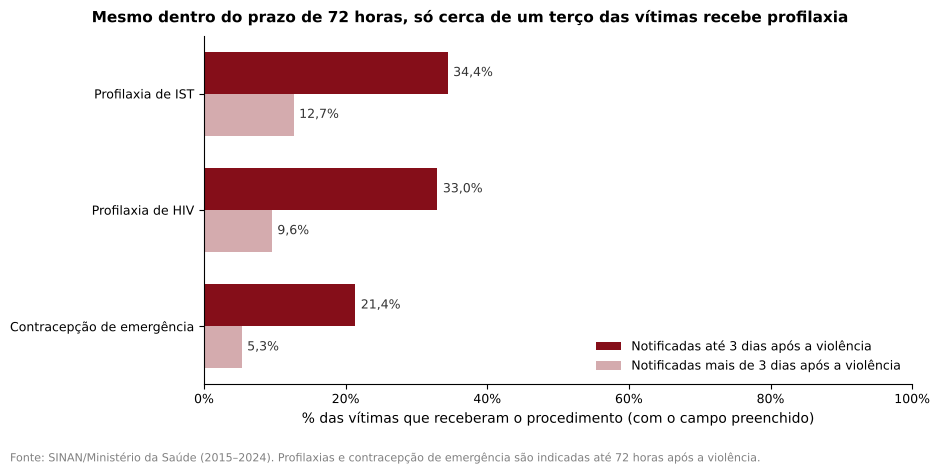

In [ ]:
# 1. Tempo entre a violência (DT_OCOR) e a notificação (DT_NOTIFIC), as duas já convertidas para data na limpeza
sinan["DIAS_ATE_NOTIF"] = (sinan["DT_NOTIFIC"] - sinan["DT_OCOR"]).dt.days
sinan["PRAZO"] = np.select([sinan["DIAS_ATE_NOTIF"].between(0, 3), sinan["DIAS_ATE_NOTIF"] > 3],
                           ["Até 3 dias", "Mais de 3 dias"], default="Sem data válida")
print("Tempo entre a violência e a notificação (% das notificações):")
print(sinan["PRAZO"].value_counts(normalize=True).mul(100).round(1).to_string(), "\n")

# 2. % que recebeu cada procedimento, entre as notificações com o campo preenchido (1 = sim, 2 = não)
procedimentos = {"PROC_DST": "Profilaxia de IST", "PROC_HIV": "Profilaxia de HIV",
                 "PROC_CONTR": "Contracepção de emergência"}
linhas = []
for col, nome in procedimentos.items():
    cod = limpa_codigo(sinan[col])
    for prazo in ["Até 3 dias", "Mais de 3 dias"]:
        sel = (sinan["PRAZO"] == prazo) & cod.isin(["1", "2"])
        linhas.append({"procedimento": nome, "prazo": prazo, "pct_sim": (cod[sel] == "1").mean() * 100, "n": int(sel.sum())})
tab_proc = pd.DataFrame(linhas)
pivo = tab_proc.pivot(index="procedimento", columns="prazo", values="pct_sim").reindex(list(procedimentos.values()))
print(pivo.sort_index().round(1).to_string())

# 3. Barras agrupadas: até 3 dias × mais de 3 dias
cores_prazo = {"Até 3 dias": VERMELHO, "Mais de 3 dias": VERMELHO_CLARO}
fig, ax = plt.subplots(figsize=(9.5, 4.2))
y = np.arange(len(pivo))
for k, prazo in enumerate(["Até 3 dias", "Mais de 3 dias"]):
    barras = ax.barh(y + (k - 0.5) * 0.36, pivo[prazo], height=0.36, color=cores_prazo[prazo],
                     label=f"Notificadas {prazo.lower()} após a violência")
    for b, v in zip(barras, pivo[prazo]):
        ax.annotate(ptbr(v) + "%", (v, b.get_y() + b.get_height() / 2), xytext=(4, 0),
                    textcoords="offset points", va="center", fontsize=9, color="#333333")
ax.set_yticks(y)
ax.set_yticklabels(pivo.index)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% das vítimas que receberam o procedimento (com o campo preenchido)")
ax.xaxis.set_major_formatter(fmt_pct)
ax.legend(loc="lower right")
plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (2015–2024). Profilaxias e contracepção de emergência são indicadas "
                   "até 72 horas após a violência.")
titulo_na_imagem(fig, "Mesmo dentro do prazo de 72 horas, só cerca de um terço das vítimas recebe profilaxia")
plt.savefig("../figures/p6_procedimentos_por_prazo.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** Mais da metade das notificações (56,1%) foi feita até 3 dias depois da violência. Mesmo entre essas vítimas, para as quais os procedimentos ainda são indicados, a cobertura é baixa: 34,4% receberam profilaxia de IST, 33,0% profilaxia de HIV e 21,4% contracepção de emergência. Entre as notificadas mais tarde, as porcentagens caem para 5% a 13%, o que é esperado, já que o prazo de 72 horas já passou.

**Como interpretar.** A diferença entre os dois grupos mostra que separar os casos pelo prazo é essencial: sem esse filtro, a cobertura pareceria ainda menor. Mesmo assim, cerca de um terço de cobertura nos casos dentro do prazo é preocupante, porque esses procedimentos previnem infecções e gravidez. Parte da diferença pode vir de casos em que o procedimento não se aplica: a contracepção de emergência não é indicada para crianças que ainda não menstruam, e em abusos repetidos pelo mesmo agressor a data registrada pode ser a da revelação, e não a do último episódio. Ainda assim, os números sugerem que muitas vítimas não recebem o atendimento previsto.

Brasil: 36.3% receberam profilaxia de IST ou HIV (casos notificados até 3 dias)
Brasil: 29.2% foram encaminhadas a alguma delegacia
Encaminhamento a delegacia por idade (%):
FAIXA
0 a 13 anos        22.5
14 a 17 anos       24.5
18 anos ou mais    43.0 

Menores % de profilaxia: AC 19.3, PI 19.9, PA 21.7, CE 23.9, AM 27.7
Maiores % de profilaxia: RR 49.6, SE 50.4, RN 52.8, AP 53.3, DF 57.8
Menores % de delegacia: TO 12.5, AP 14.9, AC 19.0, AM 19.5, AL 19.7
Maiores % de delegacia: RN 32.1, CE 32.7, MT 33.1, SP 34.7, MG 39.8


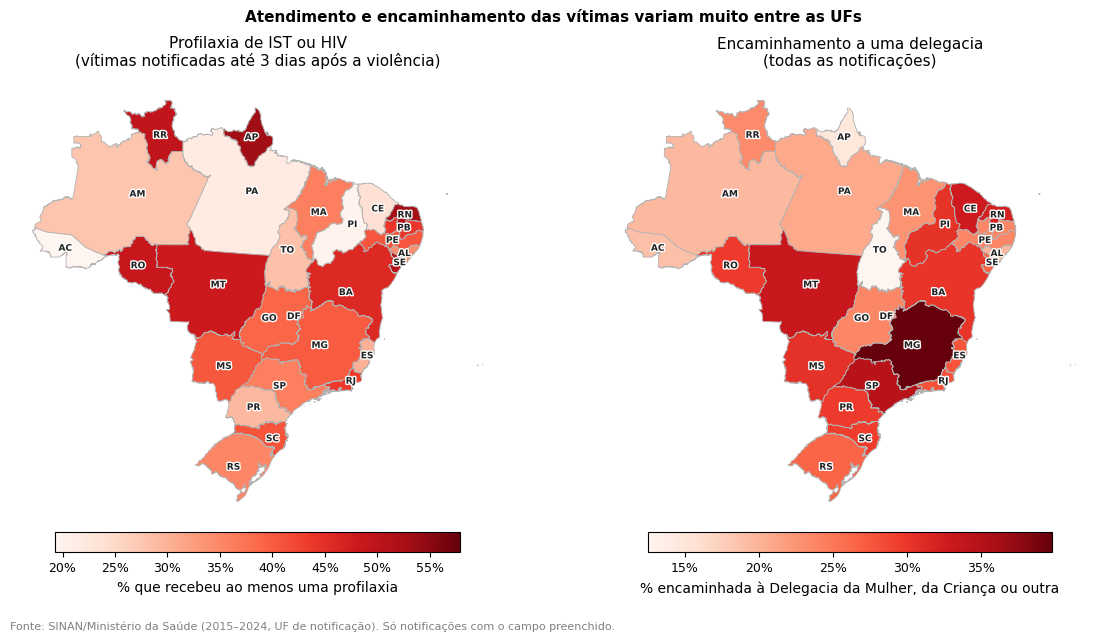

In [ ]:
# Por UF: (a) profilaxia entre os casos notificados até 3 dias; (b) encaminhamento a delegacia (todos os casos)
cols_prof = ["PROC_DST", "PROC_HIV"]
prof = sinan.loc[sinan["PRAZO"] == "Até 3 dias", ["COD_UF", *cols_prof]]
prof_valido = np.logical_or.reduce([limpa_codigo(prof[c]).isin(["1", "2"]).to_numpy() for c in cols_prof])
prof["RECEBEU_PROF"] = np.logical_or.reduce([limpa_codigo(prof[c]).eq("1").to_numpy() for c in cols_prof])
prof_uf = prof[prof_valido].groupby("COD_UF")["RECEBEU_PROF"].mean().mul(100).rename("pct_profilaxia")

cols_deleg = ["DELEG_MULH", "DELEG_CRIA", "DELEG"]
deleg_valido = np.logical_or.reduce([limpa_codigo(sinan[c]).isin(["1", "2"]).to_numpy() for c in cols_deleg])
sinan["ENC_DELEGACIA"] = np.logical_or.reduce([limpa_codigo(sinan[c]).eq("1").to_numpy() for c in cols_deleg])
deleg = sinan.loc[deleg_valido, ["COD_UF", "FAIXA", "ENC_DELEGACIA"]]
deleg_uf = deleg.groupby("COD_UF")["ENC_DELEGACIA"].mean().mul(100).rename("pct_delegacia")
print(f"Brasil: {prof[prof_valido]['RECEBEU_PROF'].mean() * 100:.1f}% receberam profilaxia de IST ou HIV "
      f"(casos notificados até 3 dias)")
print(f"Brasil: {deleg['ENC_DELEGACIA'].mean() * 100:.1f}% foram encaminhadas a alguma delegacia")
print("Encaminhamento a delegacia por idade (%):")
print(deleg.groupby("FAIXA", observed=True)["ENC_DELEGACIA"].mean().mul(100).round(1).to_string(), "\n")

# cruza com o mapa dos estados baixado na seção 1
indic_uf = pd.concat([prof_uf, deleg_uf], axis=1).reset_index().astype({"COD_UF": int})
mapa_atend = mapa_brasil.merge(indic_uf, left_on="code_state", right_on="COD_UF")
for col, rotulo in [("pct_profilaxia", "profilaxia"), ("pct_delegacia", "delegacia")]:
    ordenado = mapa_atend.sort_values(col)
    print(f"Menores % de {rotulo}:", ", ".join(f"{r.abbrev_state} {getattr(r, col):.1f}" for r in ordenado.head(5).itertuples()))
    print(f"Maiores % de {rotulo}:", ", ".join(f"{r.abbrev_state} {getattr(r, col):.1f}" for r in ordenado.tail(5).itertuples()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
for ax, col, titulo, rotulo in [
    (ax1, "pct_profilaxia", "Profilaxia de IST ou HIV\n(vítimas notificadas até 3 dias após a violência)",
     "% que recebeu ao menos uma profilaxia"),
    (ax2, "pct_delegacia", "Encaminhamento a uma delegacia\n(todas as notificações)",
     "% encaminhada à Delegacia da Mulher, da Criança ou outra"),
]:
    mapa_atend.plot(column=col, cmap="Reds", linewidth=0.6, edgecolor="0.7", ax=ax, legend=True,
                    legend_kwds={"label": rotulo, "orientation": "horizontal", "shrink": 0.7, "pad": 0.02,
                                 "format": fmt_pct})
    rotula_ufs(ax, mapa_atend, tamanho=6.5)
    ax.set_title(titulo, fontsize=11)
    ax.axis("off")
plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (2015–2024, UF de notificação). Só notificações com o campo preenchido.")
centraliza_subtitulos(fig, [ax1, ax2])
titulo_na_imagem(fig, "Atendimento e encaminhamento das vítimas variam muito entre as UFs")
plt.savefig("../figures/p6_mapas_profilaxia_delegacia.png", dpi=200, bbox_inches="tight")
plt.show()

**O que os mapas mostram.** Entre as vítimas notificadas até 3 dias depois da violência, a cobertura de profilaxia varia de cerca de 20% no Acre, no Piauí e no Pará a mais de 50% em Sergipe, no Rio Grande do Norte, no Amapá e no Distrito Federal (57,8%). O encaminhamento a uma delegacia acontece em 29,2% das notificações, com variação de 12,5% no Tocantins a 39,8% em Minas Gerais, e é bem mais comum entre mulheres adultas (43,0%) do que entre crianças (22,5%) e adolescentes (24,5%).

**Como interpretar.** Acre, Piauí, Pará e Amazonas, que estão entre as menores coberturas de profilaxia, fazem parte do grupo de estados com as maiores taxas de notificação (seção 8): notificar muito não garante atender bem. Já o encaminhamento menor de crianças à delegacia não significa que esses casos fiquem fora da polícia. Para crianças e adolescentes, o caso também é comunicado ao conselho tutelar, que pode levá-lo à delegacia por outro caminho, o que é coerente com a seção 7, em que a polícia registra mais casos de crianças do que a saúde.

### Síntese da pergunta 6

O atendimento previsto após a violência sexual chega a uma minoria das vítimas: mesmo dentro do prazo de 72 horas, só cerca de um terço recebe profilaxia, e a cobertura vai de cerca de 20% a 58% entre os estados. Menos de um terço das vítimas é encaminhado a uma delegacia, e a proporção é menor entre crianças e adolescentes.

## 7. Os registros de saúde e os de polícia contam a mesma história? Onde mais divergem?

**Pergunta de dados:** em 2024, como a taxa de notificações de violência sexual contra meninas e mulheres no SINAN se compara, em cada UF, com a taxa de vítimas mulheres de estupro e de estupro de vulnerável registradas pelas polícias? Essa relação é a mesma para crianças (0 a 13 anos) e para meninas e mulheres de 14 anos ou mais?

**Dados da polícia.** O *Anuário Brasileiro de Segurança Pública 2026*, do Fórum Brasileiro de Segurança Pública (FBSP), reúne os registros de ocorrência das secretarias estaduais de segurança e das polícias civis. Uma de suas tabelas traz, por UF, o número de vítimas mulheres de estupro e de estupro de vulnerável em 2024 e 2025. Usamos 2024, o último ano comum às duas fontes, já com os valores atualizados nesta edição. Os 27 valores foram transcritos do Anuário, e a soma confere com os totais do Brasil publicados (18.944 estupros e 59.197 estupros de vulnerável).

**Transformação.** Contamos as notificações do SINAN de 2024 por UF de notificação: as duas fontes registram o caso onde a vítima é atendida ou denuncia. Dividimos as duas fontes pela mesma população feminina de 2024 (estimativas do Ministério da Saúde), para que as taxas sejam comparáveis. Também calculamos a razão entre as fontes (notificações de saúde ÷ registros policiais): acima de 1, a saúde registra mais casos que a polícia; abaixo de 1, a polícia registra mais. Para a comparação por idade, pareamos as vítimas de 0 a 13 anos do SINAN com o estupro de vulnerável, crime definido pela idade da vítima (menos de 14 anos), e as de 14 anos ou mais com o estupro.

**Cuidados.** As duas fontes não medem exatamente a mesma coisa. A violência sexual no SINAN inclui outras formas além do estupro, como assédio e exploração sexual, e uma mesma vítima pode ser notificada mais de uma vez. O estupro de vulnerável também inclui vítimas de 14 anos ou mais que não podiam oferecer resistência, então o pareamento por idade é aproximado (no Distrito Federal, só entram vítimas menores de 14 anos). A comparação mostra onde cada sistema enxerga mais ou menos casos, e não qual deles está certo. Por fim, comparamos só 2024: montar a série de 2015 a 2024 exigiria juntar várias edições do Anuário, cujos números são revisados de uma edição para outra.

In [ ]:
# Vítimas mulheres de estupro e de estupro de vulnerável registradas pelas polícias em 2024, por UF.
# Fonte: FBSP, Anuário Brasileiro de Segurança Pública 2026, tabela "Estupro e Estupro de Vulnerável -
# vítimas mulheres" (Brasil e UFs, 2024-2025). Usamos a coluna de 2024, já atualizada nesta edição.
# Os 27 valores foram transcritos à mão do PDF do Anuário.
fbsp_2024 = pd.DataFrame(
    [
        (11, "RO", "Rondônia", 330, 1163),
        (12, "AC", "Acre", 204, 656),
        (13, "AM", "Amazonas", 356, 997),
        (14, "RR", "Roraima", 178, 725),
        (15, "PA", "Pará", 834, 3861),
        (16, "AP", "Amapá", 152, 561),
        (17, "TO", "Tocantins", 159, 775),
        (21, "MA", "Maranhão", 364, 1246),
        (22, "PI", "Piauí", 258, 1058),
        (23, "CE", "Ceará", 316, 1440),
        (24, "RN", "Rio Grande do Norte", 237, 880),
        (25, "PB", "Paraíba", 239, 789),
        (26, "PE", "Pernambuco", 630, 1750),
        (27, "AL", "Alagoas", 283, 975),
        (28, "SE", "Sergipe", 222, 746),
        (29, "BA", "Bahia", 1189, 3617),
        (31, "MG", "Minas Gerais", 1419, 3654),
        (32, "ES", "Espírito Santo", 449, 1155),
        (33, "RJ", "Rio de Janeiro", 1583, 3430),
        (35, "SP", "São Paulo", 3306, 10484),
        (41, "PR", "Paraná", 1756, 5316),
        (42, "SC", "Santa Catarina", 1435, 3011),
        (43, "RS", "Rio Grande do Sul", 1090, 3702),
        (50, "MS", "Mato Grosso do Sul", 367, 1967),
        (51, "MT", "Mato Grosso", 544, 1814),
        (52, "GO", "Goiás", 728, 3005),
        (53, "DF", "Distrito Federal", 316, 420),
    ],
    columns=["COD_UF", "SIGLA", "ESTADO", "estupro", "estupro_vulneravel"],
)
fbsp_2024["policia_total"] = fbsp_2024["estupro"] + fbsp_2024["estupro_vulneravel"]

# Conferência da transcrição: as somas batem com os totais do Brasil publicados no Anuário
assert fbsp_2024["estupro"].sum() == 18_944
assert fbsp_2024["estupro_vulneravel"].sum() == 59_197
print("Transcrição conferida: 18.944 estupros e 59.197 estupros de vulnerável (vítimas mulheres, 2024).")

Transcrição conferida: 18.944 estupros e 59.197 estupros de vulnerável (vítimas mulheres, 2024).


In [ ]:
# 1. SINAN 2024 por UF de notificação, separando as vítimas por idade
s24 = sinan.loc[sinan["ANO"] == 2024, ["COD_UF", "IDADE", "SEX_ESTUPR"]]
s24 = s24.assign(GRUPO_IDADE=np.select([s24["IDADE"] < 14, s24["IDADE"] >= 14], ["saude_0a13", "saude_14mais"],
                                       default="sem_idade"))
saude_uf = (
    s24.groupby(["COD_UF", "GRUPO_IDADE"]).size()
    .unstack(fill_value=0)
    .reindex(columns=["saude_0a13", "saude_14mais", "sem_idade"], fill_value=0)
)
saude_uf.index = saude_uf.index.astype(int)
saude_uf["saude_total"] = saude_uf.sum(axis=1)

# 2. População feminina de 2024 por UF (a mesma base para as duas fontes)
pop_2024 = pop_estados[["COD_UF", "2024"]].rename(columns={"2024": "pop_feminina_2024"})

# 3. Junta saúde, polícia e população; calcula taxas e razões
p7 = (fbsp_2024
      .merge(saude_uf.reset_index(), on="COD_UF", how="left")
      .merge(pop_2024, on="COD_UF", how="left"))
p7["taxa_saude"] = p7["saude_total"] / p7["pop_feminina_2024"] * 100_000
p7["taxa_policia"] = p7["policia_total"] / p7["pop_feminina_2024"] * 100_000
p7["razao_total"] = p7["saude_total"] / p7["policia_total"]        # > 1: a saúde registra mais
p7["razao_0a13"] = p7["saude_0a13"] / p7["estupro_vulneravel"]    # crianças × estupro de vulnerável
p7["razao_14mais"] = p7["saude_14mais"] / p7["estupro"]            # 14 anos ou mais × estupro

# 4. Brasil (soma das UFs)
br = p7[["saude_total", "saude_0a13", "saude_14mais", "policia_total",
         "estupro", "estupro_vulneravel", "pop_feminina_2024"]].sum()
br_taxa_saude = br["saude_total"] / br["pop_feminina_2024"] * 100_000
br_taxa_policia = br["policia_total"] / br["pop_feminina_2024"] * 100_000

# Correlação entre as taxas das 27 UFs (Pearson nos valores; Spearman nas posições do ranking)
r_pearson = p7["taxa_saude"].corr(p7["taxa_policia"])
r_spearman = p7["taxa_saude"].rank().corr(p7["taxa_policia"].rank())

print(f"Brasil, 2024: saúde {ptbr(br['saude_total'], 0)} notificações | polícia {ptbr(br['policia_total'], 0)} vítimas")
print(f"Taxas por 100 mil mulheres: saúde {br_taxa_saude:.1f} | polícia {br_taxa_policia:.1f}")
print(f"Razão saúde ÷ polícia: total {br['saude_total'] / br['policia_total']:.2f} | "
      f"0 a 13 anos {br['saude_0a13'] / br['estupro_vulneravel']:.2f} | "
      f"14 anos ou mais {br['saude_14mais'] / br['estupro']:.2f}")
print(f"Correlação entre as taxas das UFs: Pearson {r_pearson:.2f} | Spearman {r_spearman:.2f}")
pct_estupro = (limpa_codigo(s24["SEX_ESTUPR"]) == "1").mean() * 100
print(f"Notificações do SINAN de 2024 em que o tipo 'estupro' está marcado: {pct_estupro:.1f}%")

tabela_p7 = (p7.set_index("SIGLA")
             [["saude_total", "policia_total", "taxa_saude", "taxa_policia",
               "razao_total", "razao_0a13", "razao_14mais"]]
             .sort_values("razao_total", ascending=False)
             .round({"taxa_saude": 1, "taxa_policia": 1, "razao_total": 2, "razao_0a13": 2, "razao_14mais": 2}))
tabela_p7

Brasil, 2024: saúde 73.638 notificações | polícia 78.141 vítimas
Taxas por 100 mil mulheres: saúde 67.6 | polícia 71.7
Razão saúde ÷ polícia: total 0.94 | 0 a 13 anos 0.65 | 14 anos ou mais 1.86
Correlação entre as taxas das UFs: Pearson 0.24 | Spearman 0.28
Notificações do SINAN de 2024 em que o tipo 'estupro' está marcado: 72.9%


,saude_total,policia_total,taxa_saude,taxa_policia,razao_total,razao_0a13,razao_14mais
SIGLA,,,,,,,
DF,1785,736,114.6,47.2,2.43,1.74,3.34
AM,2775,1353,130.3,63.5,2.05,1.68,3.09
ES,2739,1604,130.9,76.6,1.71,0.92,3.73
CE,2923,1756,61.5,37.0,1.66,0.81,5.56
MG,6903,5073,63.5,46.7,1.36,1.00,2.28
RJ,6582,5013,72.8,55.5,1.31,0.83,2.35
SP,17076,13790,72.0,58.1,1.24,0.86,2.45
PE,2788,2380,56.2,48.0,1.17,0.63,2.68
AL,1463,1258,87.7,75.4,1.16,0.94,1.93


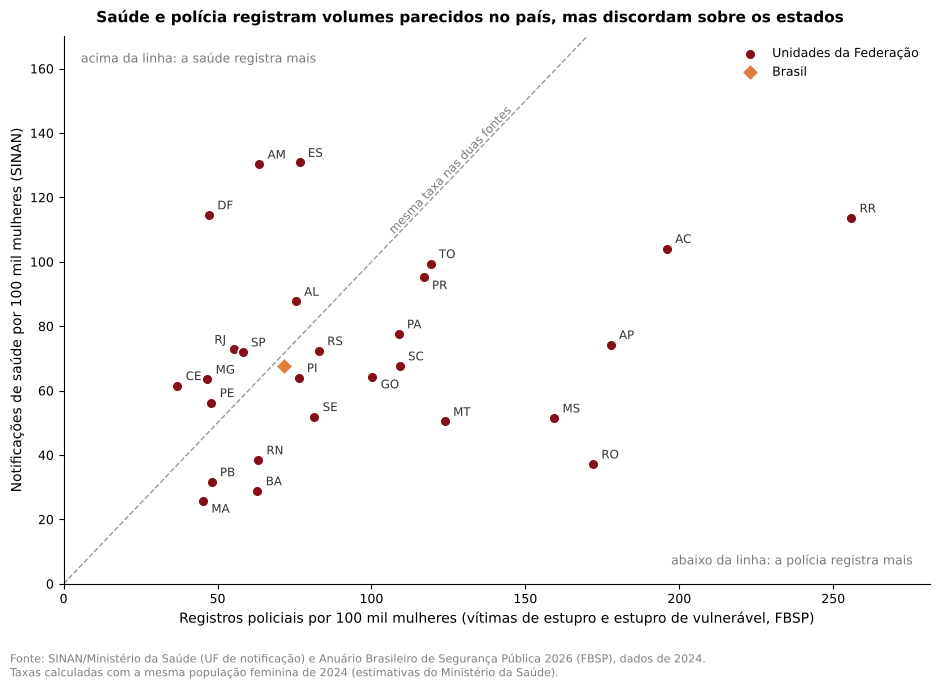

In [ ]:
# Dispersão: taxa de registros policiais (x) × taxa de notificações de saúde (y), por UF
fig, ax = plt.subplots(figsize=(9.5, 6.2))
xmax, ymax = p7["taxa_policia"].max() * 1.1, p7["taxa_saude"].max() * 1.3
ax.set_xlim(0, xmax)
ax.set_ylim(0, ymax)

ax.plot([0, max(xmax, ymax)], [0, max(xmax, ymax)], ls="--", lw=1, color="#9A9A9A", zorder=1)
ax.scatter(p7["taxa_policia"], p7["taxa_saude"], s=60, color=VERMELHO, edgecolor="white", linewidth=1.2, zorder=3,
           label="Unidades da Federação")
ax.scatter([br_taxa_policia], [br_taxa_saude], s=75, marker="D", color=LARANJA, edgecolor="white", linewidth=1.2,
           zorder=4, label="Brasil")

textos_apoio = [
    ax.text(0.02, 0.97, "acima da linha: a saúde registra mais", transform=ax.transAxes, ha="left", va="top",
            fontsize=9, color=CINZA),
    ax.text(0.98, 0.03, "abaixo da linha: a polícia registra mais", transform=ax.transAxes, ha="right", va="bottom",
            fontsize=9, color=CINZA),
]
legenda = ax.legend(loc="upper right")
ax.set_xlabel("Registros policiais por 100 mil mulheres (vítimas de estupro e estupro de vulnerável, FBSP)")
ax.set_ylabel("Notificações de saúde por 100 mil mulheres (SINAN)")
plt.tight_layout()

# rótulo da linha tracejada, inclinado na mesma direção da linha
fig.canvas.draw()
(x0, y0), (x1, y1) = ax.transData.transform([(0, 0), (1, 1)])
angulo = np.degrees(np.arctan2(y1 - y0, x1 - x0))
pos_rotulo = ymax * 0.86
textos_apoio.append(ax.text(pos_rotulo, pos_rotulo, "mesma taxa nas duas fontes", rotation=angulo, rotation_mode="anchor",
                            ha="right", va="bottom", fontsize=8.5, color=CINZA))

# siglas das UFs: começa pelas que mais se afastam da linha; o Brasil é identificado pela legenda
ordem = p7.assign(desvio=np.abs(np.log(p7["razao_total"]))).sort_values("desvio", ascending=False)
sem_rotulo = rotulos_sem_sobrepor(ax, list(ordem["taxa_policia"]) + [br_taxa_policia],
                                  list(ordem["taxa_saude"]) + [br_taxa_saude], list(ordem["SIGLA"]) + [""],
                                  evitar=textos_apoio + [legenda])
sem_rotulo = [s for s in sem_rotulo if s]
if sem_rotulo:
    print("UFs sem rótulo neste gráfico (aparecem no próximo):", ", ".join(sem_rotulo))

nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (UF de notificação) e Anuário Brasileiro de Segurança Pública 2026 "
                   "(FBSP), dados de 2024.\nTaxas calculadas com a mesma população feminina de 2024 (estimativas do "
                   "Ministério da Saúde).")
titulo_na_imagem(fig, "Saúde e polícia registram volumes parecidos no país, mas discordam sobre os estados")
plt.savefig("../figures/p7_saude_vs_policia.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** No Brasil como um todo, as duas fontes registram volumes parecidos em 2024: 73.638 notificações de saúde e 78.141 vítimas nos registros policiais, ou 67,6 e 71,7 por 100 mil mulheres (losango laranja, perto da linha). Nos estados, porém, a semelhança desaparece. A correlação entre as taxas das 27 UFs é fraca (0,24; 0,28 considerando só a ordem dos estados): saber que um estado tem taxa alta em uma fonte diz pouco sobre a taxa na outra. Roraima tem a maior taxa policial do país (255,8 por 100 mil), mas uma taxa de saúde menor que a metade disso (113,6). No sentido oposto, Distrito Federal e Amazonas notificam na saúde mais que o dobro do que a polícia registra, e o Espírito Santo, 1,7 vez. A polícia registra bem mais que a saúde sobretudo no Norte e no Centro-Oeste: em Rondônia, a saúde registra só 22% do volume policial; em Mato Grosso do Sul, 32%; em Mato Grosso, Amapá e Roraima, pouco mais de 40%.

**Como interpretar.** A distância entre as fontes não diz qual delas está certa, porque cada sistema só enxerga as vítimas que chegaram até ele. Onde a polícia registra muito mais, uma explicação possível é a subnotificação na saúde, coerente com a constatação do Ipea de que muitos municípios não notificam nenhuma violência. Onde a saúde registra mais, pode haver uma rede de notificação mais estruturada ou vítimas que procuram atendimento sem registrar boletim de ocorrência. No Distrito Federal, parte da diferença também vem da definição policial: lá, só entram como estupro de vulnerável as vítimas menores de 14 anos. Para a análise geográfica da seção 1, isso significa que o mapa de onde a violência sexual é mais registrada depende da fonte escolhida.

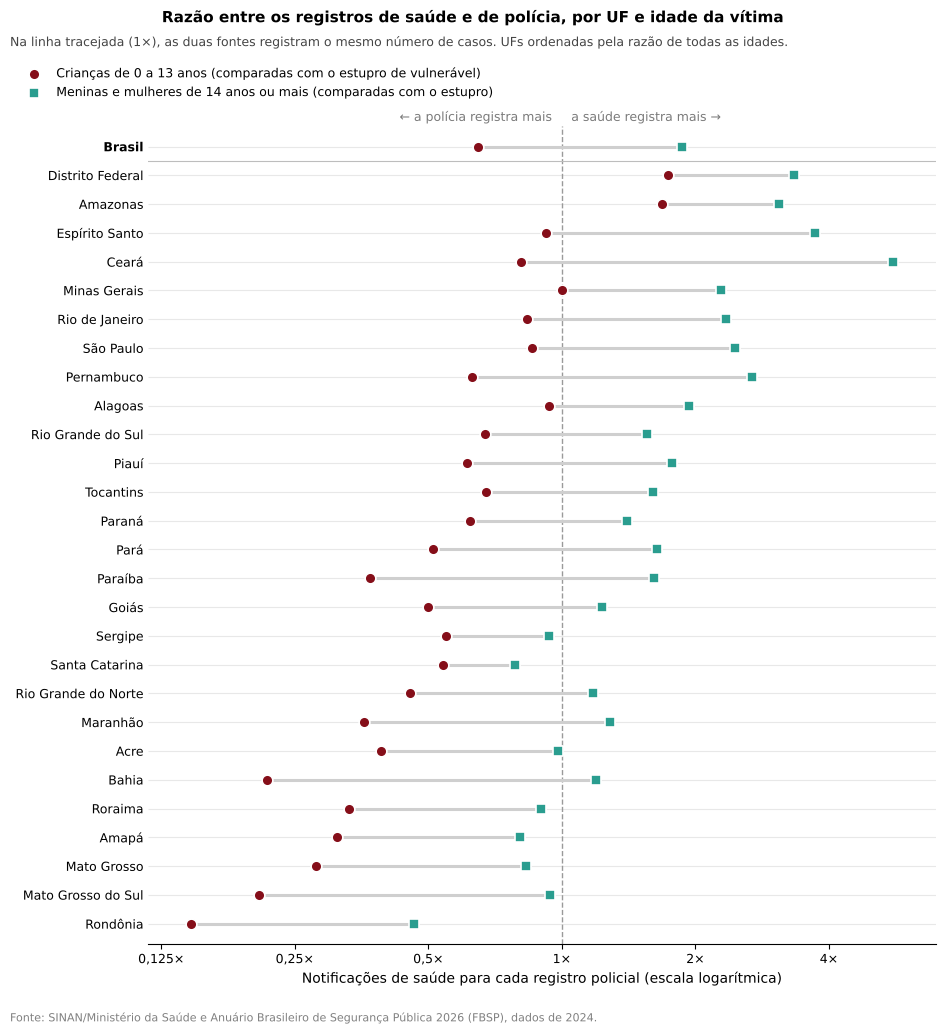

In [ ]:
# Razão saúde ÷ polícia por UF, separando crianças (0 a 13 anos) de meninas e mulheres de 14 anos ou mais
ordem = p7.sort_values("razao_total")
linhas = pd.concat([
    ordem[["ESTADO", "razao_0a13", "razao_14mais"]],
    pd.DataFrame({"ESTADO": ["Brasil"],
                  "razao_0a13": [br["saude_0a13"] / br["estupro_vulneravel"]],
                  "razao_14mais": [br["saude_14mais"] / br["estupro"]]}),
], ignore_index=True)
y = np.arange(len(linhas))
valores = linhas[["razao_0a13", "razao_14mais"]].to_numpy()
xmin, xmax = np.nanmin(valores) * 0.8, np.nanmax(valores) * 1.25

fig, ax = plt.subplots(figsize=(9.5, 10))
# linhas-guia cinza claras ligando o nome de cada UF aos seus pontos
ax.hlines(y, xmin, xmax, color="#E8E8E8", lw=0.8, zorder=0)
ax.axvline(1, color="#9A9A9A", lw=1, ls="--", zorder=1)
ax.hlines(y, valores.min(axis=1), valores.max(axis=1), color="#CFCFCF", lw=2.2, zorder=2)
ax.scatter(linhas["razao_0a13"], y, s=60, marker="o", color=VERMELHO, edgecolor="white", linewidth=1.2, zorder=3,
           label="Crianças de 0 a 13 anos (comparadas com o estupro de vulnerável)")
ax.scatter(linhas["razao_14mais"], y, s=60, marker="s", color=VERDE, edgecolor="white", linewidth=1.2, zorder=3,
           label="Meninas e mulheres de 14 anos ou mais (comparadas com o estupro)")

ax.set_xscale("log")
ax.set_xlim(xmin, xmax)
marcas = [t for t in [0.125, 0.25, 0.5, 1, 2, 4, 8] if xmin <= t <= xmax]
ax.set_xticks(marcas, [f"{ptbr_curto(t)}×" if t >= 1 else f"{ptbr(t, 3 if t < 0.25 else 2).rstrip('0')}×" for t in marcas])
ax.minorticks_off()
ax.set_yticks(y, linhas["ESTADO"])
ax.get_yticklabels()[-1].set_fontweight("bold")
ax.axhline(len(linhas) - 1.5, color="#BDBDBD", lw=0.8)
ax.set_ylim(-0.7, len(linhas) - 0.3)
ax.spines[["left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

ax.text(0.95, 1.003, "← a polícia registra mais", transform=ax.get_xaxis_transform(), ha="right", va="bottom",
        fontsize=9, color=CINZA)
ax.text(1.05, 1.003, "a saúde registra mais →", transform=ax.get_xaxis_transform(), ha="left", va="bottom",
        fontsize=9, color=CINZA)
ax.set_xlabel("Notificações de saúde para cada registro policial (escala logarítmica)")

fig.text(0.01, 0.965, "Na linha tracejada (1×), as duas fontes registram o mesmo número de casos. UFs ordenadas pela razão "
         "de todas as idades.", fontsize=9, color="#444444")
fig.legend(loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=1, fontsize=9)
plt.tight_layout(rect=(0, 0.01, 1, 0.915))
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde e Anuário Brasileiro de Segurança Pública 2026 (FBSP), dados de 2024.")
titulo_na_imagem(fig, "Razão entre os registros de saúde e de polícia, por UF e idade da vítima")
plt.savefig("../figures/p7_razao_por_idade.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** A divergência muda de sentido conforme a idade da vítima. Para crianças de 0 a 13 anos, a polícia registra mais: no Brasil, há 0,65 notificação de saúde para cada vítima de estupro de vulnerável, e a razão fica abaixo de 1 em 24 das 27 UFs (só Distrito Federal e Amazonas ficam acima, e Minas Gerais empata). Para meninas e mulheres de 14 anos ou mais, acontece o contrário: a saúde notifica 1,86 vez o número de vítimas de estupro registradas pela polícia, a razão passa de 1 em 19 UFs e chega a 5,6 no Ceará. Em todas as 27 UFs, a razão das vítimas de 14 anos ou mais é maior que a das crianças, inclusive nos estados em que a polícia registra mais no total, como Rondônia.

**Como interpretar.** Os dados não mostram por que isso acontece, mas há explicações plausíveis. Muitas vítimas de 14 anos ou mais procuram um serviço de saúde, por exemplo para a profilaxia ou a contracepção de emergência, sem registrar boletim de ocorrência: o atendimento no SUS é obrigatório (Lei nº 12.845/2013), não depende de registro policial, e a notificação é feita mesmo quando a vítima não quer denunciar. Isso é coerente com a estimativa do Ipea de que só 8,5% dos estupros chegam à polícia. Com as crianças, o caminho costuma ser outro: a violência é revelada pela família, pela escola ou pelo conselho tutelar, e o caso pode chegar à delegacia sem passar por um serviço de saúde que notifique. Além disso, o estupro de vulnerável inclui qualquer ato sexual com menor de 14 anos, mesmo sem violência física, situação que nem sempre leva a um atendimento de saúde.

**Cuidado com os números.** Em 2024, 72,9% das notificações do SINAN tinham o tipo estupro marcado; contando só essas, todas as razões ficariam menores. Por isso, damos mais peso às diferenças entre idades e entre estados do que ao valor exato de cada razão.

### Síntese da pergunta 7

No total do país, saúde e polícia registram volumes parecidos de violência sexual contra meninas e mulheres, mas contam histórias diferentes. Elas discordam sobre quais estados têm mais casos (correlação de 0,24 entre as taxas das UFs) e sobre quem são as vítimas: a polícia registra mais crianças, e a saúde, mais meninas e mulheres de 14 anos ou mais. Como cada sistema enxerga uma parte diferente do problema, um retrato baseado em uma só fonte fica incompleto, o que reforça a importância de usar e integrar os dois registros.

## 8. Existem grupos de estados com perfis parecidos de violência sexual registrada?

**Pergunta de dados:** se descrevermos cada UF por cinco indicadores do SINAN de 2015 a 2024 (taxa de notificação, proporção de vítimas de 0 a 13 anos, proporção de casos na residência e proporção de agressores da família e de desconhecidos), as UFs se dividem em grupos com perfis parecidos? Esses grupos seguem algum padrão geográfico?

**Transformação.** Calculamos os cinco indicadores para cada UF, com todas as notificações de 2015 a 2024 e a UF de notificação. A proporção de casos na residência exclui os registros com local ignorado; as de vínculo usam todas as notificações, e uma vítima pode ter mais de um agressor marcado. Como a taxa está numa escala diferente da dos percentuais, padronizamos cada indicador (média 0 e desvio-padrão 1) antes do agrupamento; sem isso, a taxa dominaria as distâncias entre as UFs.

**Método.** Usamos o k-means, que separa as UFs em k grupos de modo que cada UF fique mais próxima do centro do seu grupo do que do centro dos outros. Para escolher k, comparamos de 2 a 6 grupos por dois critérios: o método do cotovelo, que mostra quanto a inércia (a soma das distâncias ao quadrado até o centro do grupo) cai a cada grupo a mais, e o coeficiente de silhueta, que mede quanto cada UF está mais perto do próprio grupo do que do grupo vizinho (vai de −1 a 1; quanto maior, mais bem separados os grupos).

**Cuidados.** Com só 27 UFs, os grupos são sensíveis a estados com valores extremos, e o k-means sempre forma grupos, mesmo quando as diferenças são pequenas; por isso conferimos a silhueta e o perfil de cada grupo antes de interpretá-los. Os grupos descrevem semelhanças nos registros, que dependem tanto da violência quanto da capacidade de notificação de cada estado, como mostrou a seção 7. Trabalhamos com estados, e não com municípios, porque muitos municípios têm poucas notificações por ano, o que tornaria as proporções instáveis.

In [ ]:
# Indicadores de cada UF, com todas as notificações de 2015 a 2024 (UF de notificação), a partir das colunas já
# criadas nas seções anteriores (IDADE, LOCAL_NOME e os vínculos marcados em rel_sim)
base = pd.DataFrame({
    "COD_UF": sinan["COD_UF"].astype(int),
    "crianca": np.where(sinan["IDADE"].notna(), sinan["IDADE"] < 14, np.nan),
    "residencia": np.where(sinan["LOCAL_NOME"] != "Ignorado", sinan["LOCAL_NOME"] == "Residência", np.nan),  # sem os ignorados
    "familiar": rel_sim[["REL_PAI", "REL_MAE", "REL_PAD", "REL_MAD", "REL_IRMAO"]].any(axis=1),
    "desconhecido": rel_sim["REL_DESCO"],
})

indicadores = base.groupby("COD_UF").agg(
    notificacoes=("crianca", "size"),
    pct_criancas=("crianca", "mean"),
    pct_residencia=("residencia", "mean"),
    pct_familiar=("familiar", "mean"),
    pct_desconhecido=("desconhecido", "mean"),
)
for c in ["pct_criancas", "pct_residencia", "pct_familiar", "pct_desconhecido"]:
    indicadores[c] = (indicadores[c] * 100).round(1)

# taxa média anual por 100 mil mulheres (a mesma do mapa da seção 1)
pop_10anos = pop_estados.set_index("COD_UF")["pop_soma_10anos"]
indicadores["taxa_anual"] = (indicadores["notificacoes"] / pop_10anos * 100_000).round(1)

indicadores = indicadores.join(fbsp_2024.set_index("COD_UF")[["SIGLA", "ESTADO"]])
variaveis = {
    "taxa_anual": "Taxa por 100 mil\nmulheres por ano",
    "pct_criancas": "% de vítimas\nde 0 a 13 anos",
    "pct_residencia": "% de casos\nna residência",
    "pct_familiar": "% de agressores\nda família",
    "pct_desconhecido": "% de agressores\ndesconhecidos",
}
indicadores.set_index("SIGLA")[list(variaveis)].sort_values("taxa_anual", ascending=False)

,taxa_anual,pct_criancas,pct_residencia,pct_familiar,pct_desconhecido
SIGLA,,,,,
AC,132.0,43.3,87.8,7.5,11.0
TO,90.3,66.7,77.8,20.9,14.9
RR,89.0,60.4,70.2,17.9,24.2
DF,84.0,47.3,71.2,18.2,23.8
AM,83.6,61.5,82.6,18.7,15.1
ES,62.5,43.5,72.9,20.8,15.9
PR,59.0,57.1,70.3,25.2,17.0
PA,54.6,62.4,78.6,21.2,12.9
AP,46.5,56.7,76.4,12.9,19.6


k:          [2, 3, 4, 5, 6]
silhueta:   [0.355, 0.262, 0.272, 0.21, 0.281]


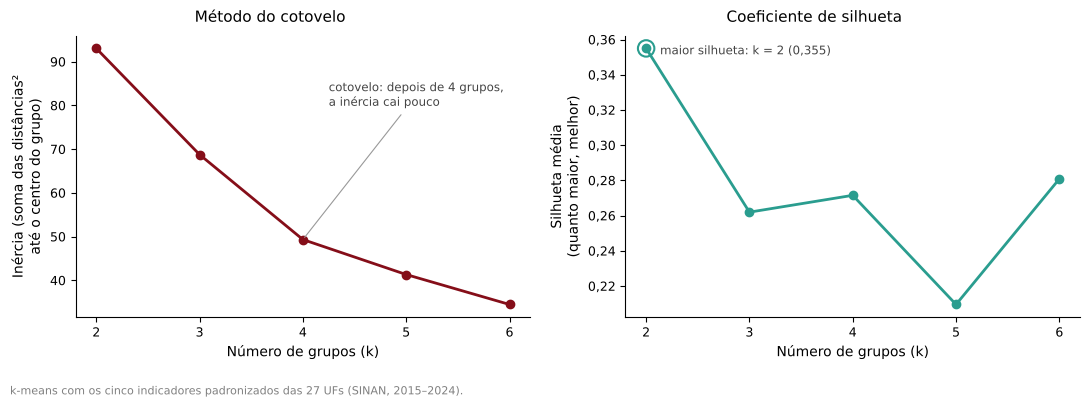

In [ ]:
# Padroniza cada indicador (média 0, desvio-padrão 1), para que a taxa, medida em outra escala,
# não pese mais que os percentuais no cálculo das distâncias
X = StandardScaler().fit_transform(indicadores[list(variaveis)])

ks = list(range(2, 7))
inercias, silhuetas = [], []
for k in ks:
    modelo = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    inercias.append(modelo.inertia_)
    silhuetas.append(silhouette_score(X, modelo.labels_))
print("k:         ", ks)
print("silhueta:  ", [round(float(s), 3) for s in silhuetas])

k_silhueta = ks[int(np.argmax(silhuetas))]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(ks, inercias, marker="o", color=VERMELHO, lw=2)
ax1.annotate("cotovelo: depois de 4 grupos,\na inércia cai pouco", (4, inercias[2]), xytext=(4.25, inercias[0] * 0.92),
             fontsize=8.5, color="#444444", va="top", arrowprops=dict(arrowstyle="-", color="#999999", lw=0.8))
ax1.set_title("Método do cotovelo", fontsize=11)
ax1.set_ylabel("Inércia (soma das distâncias²\naté o centro do grupo)")
ax2.plot(ks, silhuetas, marker="o", color=VERDE, lw=2)
ax2.scatter([k_silhueta], [max(silhuetas)], s=140, facecolor="none", edgecolor=VERDE, lw=1.5, zorder=3)
ax2.annotate(f"maior silhueta: k = {k_silhueta} ({ptbr(max(silhuetas), 3)})", (k_silhueta, max(silhuetas)),
             xytext=(10, -2), textcoords="offset points", fontsize=8.5, color="#444444", va="center")
ax2.set_title("Coeficiente de silhueta", fontsize=11)
ax2.set_ylabel("Silhueta média\n(quanto maior, melhor)")
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: ptbr(v, 2)))
for ax in (ax1, ax2):
    ax.set_xticks(ks)
    ax.set_xlabel("Número de grupos (k)")
ax1.yaxis.set_major_formatter(fmt_milhar)
plt.tight_layout()
nota_de_fonte(fig, "k-means com os cinco indicadores padronizados das 27 UFs (SINAN, 2015–2024).")
centraliza_subtitulos(fig, [ax1, ax2])
plt.savefig("../figures/p8_escolha_k.png", dpi=200, bbox_inches="tight")
plt.show()

**Como escolhemos k.** A silhueta é maior com 2 grupos (0,36) e cai para 0,26 a 0,28 com 3, 4 ou 6 grupos (0,21 com 5). Na inércia, as quedas são grandes até 4 grupos e depois ficam pequenas, formando um cotovelo em k = 4. Os dois critérios não concordam, e todas as silhuetas são baixas (abaixo de 0,4): as UFs não formam grupos muito separados, e os perfis variam de forma mais contínua do que em blocos. Usamos k = 2, que tem a melhor silhueta, e mais abaixo mostramos a divisão em 4 grupos como visão complementar.

In [ ]:
# Número de grupos escolhido a partir do gráfico acima
K = ks[int(np.argmax(silhuetas))]

modelo = KMeans(n_clusters=K, n_init=50, random_state=42).fit(X)
indicadores["grupo_km"] = modelo.labels_

# numera os grupos da maior para a menor taxa média, para que o nome não dependa do sorteio inicial
ordem_grupos = indicadores.groupby("grupo_km")["taxa_anual"].mean().sort_values(ascending=False).index
indicadores["GRUPO"] = indicadores["grupo_km"].map({g: f"Grupo {i + 1}" for i, g in enumerate(ordem_grupos)})
nomes_grupos = sorted(indicadores["GRUPO"].unique())
cores_grupos = dict(zip(nomes_grupos, [VERMELHO, "#2A9D8F", "#E07B39", "#3B75AF", "#C9A227", "#8C8C8C"]))

print(f"k = {K} grupos | silhueta = {silhouette_score(X, modelo.labels_):.3f}\n")
for g in nomes_grupos:
    ufs = indicadores.loc[indicadores["GRUPO"] == g, "SIGLA"].sort_values()
    print(f"{g} ({len(ufs)} UFs): {', '.join(ufs)}")

perfil = indicadores.groupby("GRUPO")[list(variaveis)].mean().round(1)
perfil.loc["Brasil (média das UFs)"] = indicadores[list(variaveis)].mean().round(1)
perfil

k = 2 grupos | silhueta = 0.355

Grupo 1 (5 UFs): AC, AM, PA, PI, TO
Grupo 2 (22 UFs): AL, AP, BA, CE, DF, ES, GO, MA, MG, MS, MT, PB, PE, PR, RJ, RN, RO, RR, RS, SC, SE, SP


,taxa_anual,pct_criancas,pct_residencia,pct_familiar,pct_desconhecido
GRUPO,,,,,
Grupo 1,81.0,59.2,80.6,17.6,12.7
Grupo 2,41.3,50.6,70.9,18.7,20.2
Brasil (média das UFs),48.6,52.2,72.7,18.5,18.8


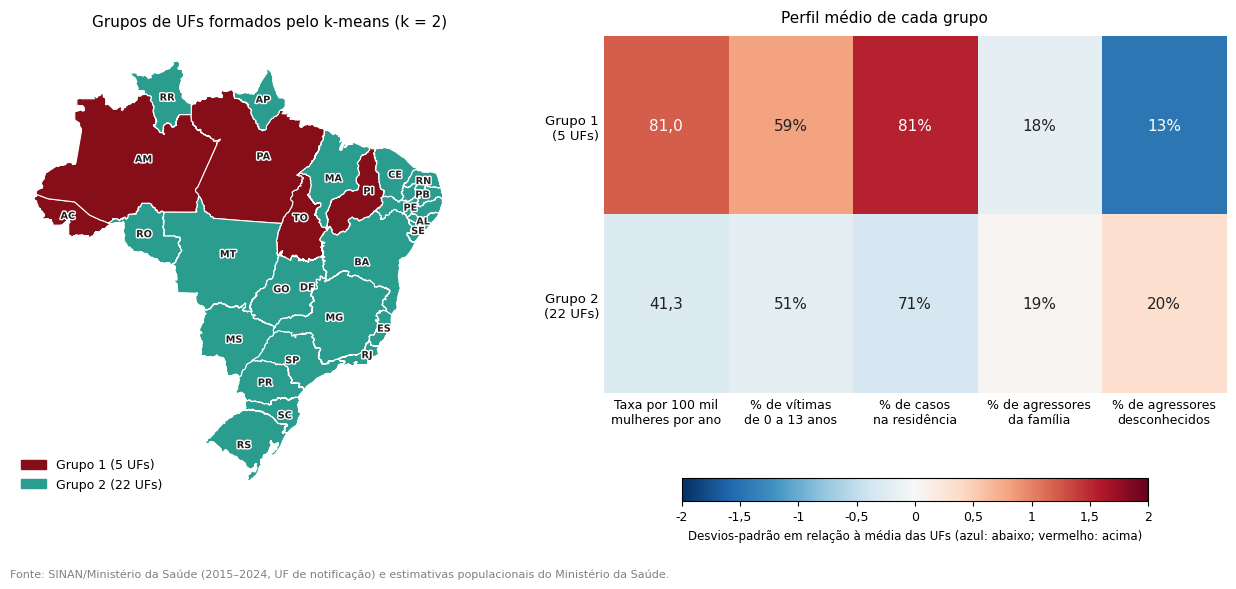

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.6), gridspec_kw={"width_ratios": [1, 1.2]})

# Painel 1: mapa das UFs coloridas pelo grupo (mapa dos estados baixado na seção 1)
mapa_grupos = mapa_brasil.merge(indicadores.reset_index(), left_on="code_state", right_on="COD_UF")
for g in nomes_grupos:
    mapa_grupos[mapa_grupos["GRUPO"] == g].plot(ax=ax1, color=cores_grupos[g], edgecolor="white", linewidth=0.8)
rotula_ufs(ax1, mapa_grupos, coluna="SIGLA")
ax1.legend(handles=[Patch(color=cores_grupos[g], label=f"{g} ({(indicadores['GRUPO'] == g).sum()} UFs)")
                    for g in nomes_grupos], loc="lower left", fontsize=9)
ax1.set_title("Grupos de UFs formados pelo k-means (k = 2)", fontsize=11)
ax1.axis("off")

# Painel 2: perfil médio de cada grupo (cor = distância da média das UFs em desvios-padrão; número = valor real)
z = (perfil.drop(index="Brasil (média das UFs)") - indicadores[list(variaveis)].mean()) / indicadores[list(variaveis)].std()
imagem = ax2.imshow(z.to_numpy(), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
for i, g in enumerate(z.index):
    for j, v in enumerate(variaveis):
        valor = perfil.loc[g, v]
        texto = ptbr(valor) if v == "taxa_anual" else f"{ptbr(valor, 0)}%"
        ax2.text(j, i, texto, ha="center", va="center", fontsize=11,
                 color="white" if abs(z.iloc[i, j]) > 1.2 else "#222222")
ax2.set_xticks(range(len(variaveis)), list(variaveis.values()), fontsize=9)
ax2.set_yticks(range(len(z)), [f"{g}\n({(indicadores['GRUPO'] == g).sum()} UFs)" for g in z.index], fontsize=9.5)
ax2.tick_params(length=0)
for lado in ax2.spines.values():
    lado.set_visible(False)
ax2.set_title("Perfil médio de cada grupo", fontsize=11)
barra = fig.colorbar(imagem, ax=ax2, orientation="horizontal", fraction=0.06, pad=0.18, shrink=0.75,
                     format=FuncFormatter(lambda v, _: ptbr_curto(v)))
barra.set_label("Desvios-padrão em relação à média das UFs (azul: abaixo; vermelho: acima)", fontsize=8.5)

plt.tight_layout()
nota_de_fonte(fig, "Fonte: SINAN/Ministério da Saúde (2015–2024, UF de notificação) e estimativas populacionais do "
                   "Ministério da Saúde.")
centraliza_subtitulos(fig, [ax1, ax2])
plt.savefig("../figures/p8_mapa_e_perfil_grupos.png", dpi=200, bbox_inches="tight")
plt.show()

**O que o gráfico mostra.** Com dois grupos, o k-means separa cinco UFs (Acre, Amazonas, Pará e Tocantins, no Norte, e Piauí) das outras 22. O Grupo 1 tem quase o dobro da taxa de notificação do Grupo 2 (81,0 contra 41,3 por 100 mil mulheres por ano, na média das UFs), mais vítimas de 0 a 13 anos (59% contra 51%), mais casos na residência (81% contra 71%) e menos agressores desconhecidos (13% contra 20%). A proporção de agressores da família é praticamente a mesma nos dois grupos (18% e 19%).

**Como interpretar.** O Grupo 1 reúne estados em que a violência notificada é mais frequente, mais concentrada na infância e mais doméstica, um perfil coerente com o que as seções 3 e 4 mostraram para as crianças: violência dentro de casa, cometida por alguém conhecido. Mas a taxa alta desses estados também pode refletir uma notificação mais ativa na saúde; o Amazonas, por exemplo, é um dos estados em que a saúde registra o dobro da polícia (seção 7). No sentido oposto, Rondônia e Mato Grosso, onde a polícia registra muito mais que a saúde, têm taxas de notificação baixas e ficaram no Grupo 2. Por isso, os grupos descrevem o perfil dos registros de saúde, que mistura a violência e a capacidade de notificação de cada estado.

k = 4 grupos | silhueta = 0.272

Grupo A (1 UFs): AC
Grupo B (6 UFs): AM, PA, PI, RS, SE, TO
Grupo C (15 UFs): AL, AP, DF, ES, GO, MG, MS, MT, PR, RJ, RN, RO, RR, SC, SP
Grupo D (5 UFs): BA, CE, MA, PB, PE


,taxa_anual,pct_criancas,pct_residencia,pct_familiar,pct_desconhecido
GRUPO_4,,,,,
Grupo A,132.0,43.3,87.8,7.5,11.0
Grupo B,57.8,61.8,77.0,21.5,13.6
Grupo C,47.2,53.2,70.5,19.9,20.8
Grupo D,25.2,39.5,70.7,12.7,20.7


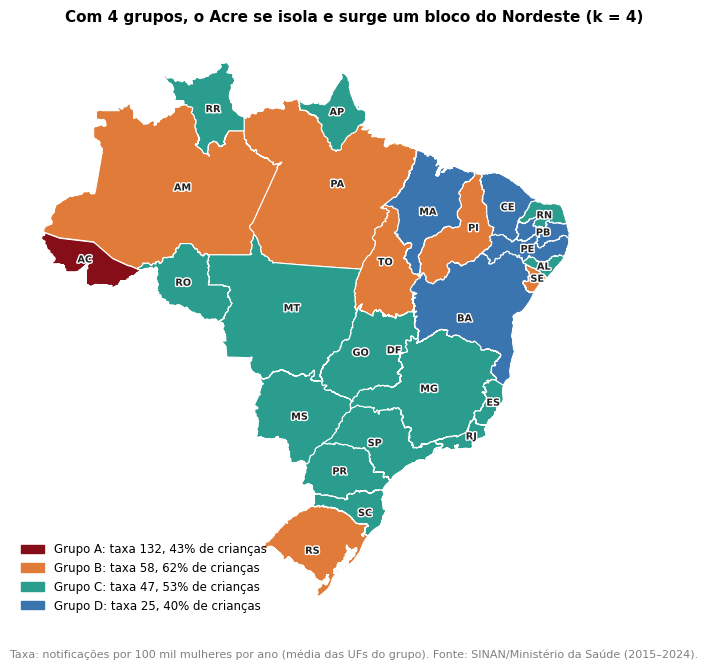

In [ ]:
# Visão complementar: 4 grupos, onde se forma o cotovelo do gráfico de inércia (grupos A a D, da maior para a menor taxa)
modelo4 = KMeans(n_clusters=4, n_init=50, random_state=42).fit(X)
indicadores["grupo4_km"] = modelo4.labels_
ordem4 = indicadores.groupby("grupo4_km")["taxa_anual"].mean().sort_values(ascending=False).index
indicadores["GRUPO_4"] = indicadores["grupo4_km"].map({g: f"Grupo {'ABCD'[i]}" for i, g in enumerate(ordem4)})
print(f"k = 4 grupos | silhueta = {silhouette_score(X, modelo4.labels_):.3f}\n")
for g in sorted(indicadores["GRUPO_4"].unique()):
    ufs = indicadores.loc[indicadores["GRUPO_4"] == g, "SIGLA"].sort_values()
    print(f"{g} ({len(ufs)} UFs): {', '.join(ufs)}")
perfil4 = indicadores.groupby("GRUPO_4")[list(variaveis)].mean().round(1)
display(perfil4)

# Mapa dos 4 grupos
cores4 = dict(zip(sorted(indicadores["GRUPO_4"].unique()), [VERMELHO, LARANJA, VERDE, AZUL]))
mapa4 = mapa_brasil.merge(indicadores.reset_index(), left_on="code_state", right_on="COD_UF")
fig, ax = plt.subplots(figsize=(7, 6.5))
for g, cor in cores4.items():
    mapa4[mapa4["GRUPO_4"] == g].plot(ax=ax, color=cor, edgecolor="white", linewidth=0.8)
rotula_ufs(ax, mapa4, coluna="SIGLA")
descricao = {}
for g in cores4:
    p = perfil4.loc[g]
    descricao[g] = f"{g}: taxa {ptbr(p['taxa_anual'], 0)}, {ptbr(p['pct_criancas'], 0)}% de crianças"
ax.legend(handles=[Patch(color=c, label=descricao[g]) for g, c in cores4.items()], loc="lower left", fontsize=8.5)
ax.axis("off")
plt.tight_layout()
nota_de_fonte(fig, "Taxa: notificações por 100 mil mulheres por ano (média das UFs do grupo). Fonte: SINAN/Ministério da "
                   "Saúde (2015–2024).")
titulo_na_imagem(fig, "Com 4 grupos, o Acre se isola e surge um bloco do Nordeste (k = 4)")
plt.savefig("../figures/p8_mapa_k4.png", dpi=200, bbox_inches="tight")
plt.show()

**Com quatro grupos.** A divisão em 4 grupos (silhueta 0,27) detalha a anterior. O Acre fica sozinho no Grupo A, pela taxa muito acima das demais (132 por 100 mil mulheres por ano) e por ter só 7,5% de agressores da família. O Grupo B junta Amazonas, Pará, Piauí e Tocantins (o Grupo 1 anterior, sem o Acre) com Rio Grande do Sul e Sergipe: taxa acima da média, mais crianças entre as vítimas (62%) e mais casos em casa (77%). O Grupo C reúne 15 UFs, todas as do Sudeste e do Centro-Oeste, além de Paraná, Santa Catarina e algumas do Norte e do Nordeste, com perfil próximo da média. O Grupo D reúne cinco estados do Nordeste (Bahia, Ceará, Maranhão, Paraíba e Pernambuco), com a menor taxa (25,2), a menor proporção de crianças (40%) e poucos agressores da família (13%).

**Como interpretar.** O Grupo D é o retrato mais claro da subnotificação. São estados com taxas de notificação baixas na saúde e, como mostrou a seção 7, com a polícia registrando mais casos de crianças do que a saúde (na Bahia, mais de quatro vezes). Ou seja, a proporção menor de crianças nesse grupo provavelmente vem de crianças que não chegam à notificação de saúde, e não de menos violência contra elas.

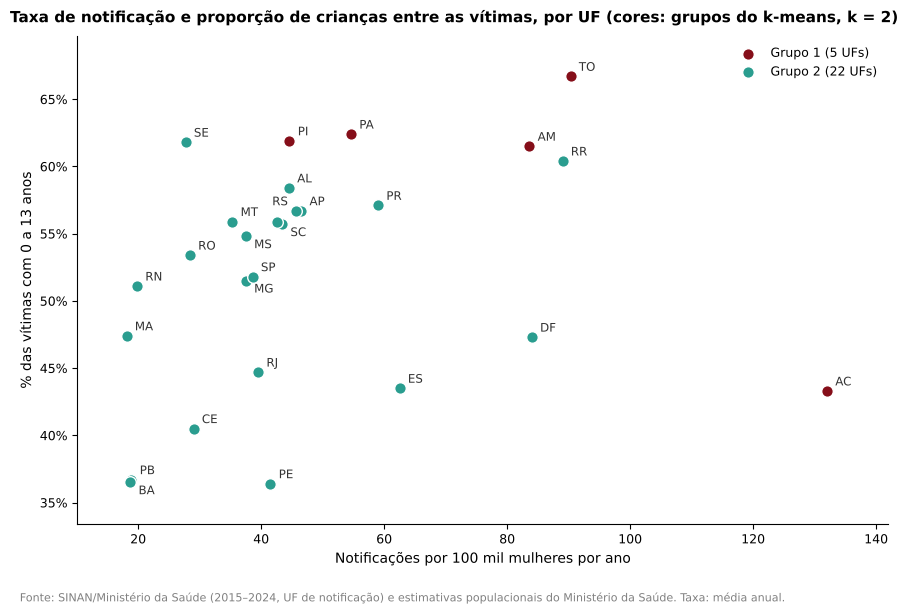

In [ ]:
# Taxa de notificação × proporção de crianças entre as vítimas, por UF, com as cores dos grupos do k-means (k = 2)
x_col, y_col = "taxa_anual", "pct_criancas"
dados_uf = indicadores.reset_index()
x_lim = [dados_uf[x_col].min() - 8, dados_uf[x_col].max() + 10]
y_lim = [dados_uf[y_col].min() - 3, dados_uf[y_col].max() + 3]
titulo_disp = "Taxa de notificação e proporção de crianças entre as vítimas, por UF"
fonte_disp = ("Fonte: SINAN/Ministério da Saúde (2015–2024, UF de notificação) e estimativas populacionais do Ministério "
              "da Saúde. Taxa: média anual.")

# Versão estática (imagem salva na pasta figures). Fica visível no notebook porque o GitHub não mostra gráficos do
# plotly (JavaScript): sem ela, o notebook aberto no GitHub teria um espaço em branco
fig, ax = plt.subplots(figsize=(9, 5.6))
for g in nomes_grupos:
    d = dados_uf[dados_uf["GRUPO"] == g]
    ax.scatter(d[x_col], d[y_col], s=70, color=cores_grupos[g], edgecolor="white", linewidth=1, zorder=3,
               label=f"{g} ({len(d)} UFs)")
legenda = ax.legend(loc="upper right")
ax.set_xlim(x_lim)
ax.set_ylim(y_lim)
ax.yaxis.set_major_formatter(fmt_pct)
ax.set_xlabel("Notificações por 100 mil mulheres por ano")
ax.set_ylabel("% das vítimas com 0 a 13 anos")
plt.tight_layout()
rotulos_sem_sobrepor(ax, dados_uf[x_col], dados_uf[y_col], dados_uf["SIGLA"], evitar=[legenda])
nota_de_fonte(fig, fonte_disp)
titulo_na_imagem(fig, titulo_disp + " (cores: grupos do k-means, k = 2)")
plt.savefig("../figures/p8_taxa_criancas_grupos.png", dpi=200, bbox_inches="tight")
plt.show()

# Versão interativa: passe o mouse sobre um ponto para ver todos os indicadores da UF
LARGURA, ALTURA = 900, 560
MARGEM = dict(l=70, r=30, t=120, b=90)

def em_pixels(x, y):
    """Converte um ponto do gráfico para pixels (origem no canto superior esquerdo)."""
    largura_util = LARGURA - MARGEM["l"] - MARGEM["r"]
    altura_util = ALTURA - MARGEM["t"] - MARGEM["b"]
    px = MARGEM["l"] + (x - x_lim[0]) / (x_lim[1] - x_lim[0]) * largura_util
    py = MARGEM["t"] + (y_lim[1] - y) / (y_lim[1] - y_lim[0]) * altura_util
    return px, py

# Escolhe a posição de cada sigla: primeiro ao lado do ponto; se não couber, um pouco mais longe, com uma linha até ele
pontos = [em_pixels(x, y) for x, y in zip(dados_uf[x_col], dados_uf[y_col])]
ocupado = [(px - 6, py - 6, px + 6, py + 6) for px, py in pontos]
perto = [(0, -13), (0, 13), (16, 0), (-16, 0), (14, -11), (-14, -11), (14, 11), (-14, 11)]
longe = [(30, -24), (-30, -24), (30, 24), (-30, 24), (44, 0), (-44, 0), (0, -34), (0, 34)]
sobrepoe = lambda a, b: not (a[2] <= b[0] or b[2] <= a[0] or a[3] <= b[1] or b[3] <= a[1])
anotacoes = []
for (px, py), sigla, x, y in zip(pontos, dados_uf["SIGLA"], dados_uf[x_col], dados_uf[y_col]):
    larg, alt = 8 * len(sigla) + 2, 14
    escolha = None
    for dx, dy in perto + longe:
        caixa = (px + dx - larg / 2, py + dy - alt / 2, px + dx + larg / 2, py + dy + alt / 2)
        if not any(sobrepoe(caixa, o) for o in ocupado):
            escolha = (dx, dy, caixa)
            break
    if escolha is None:
        escolha = (0, -13, (px - larg / 2, py - 19, px + larg / 2, py - 6))
    dx, dy, caixa = escolha
    ocupado.append(caixa)
    afastado = (dx, dy) in longe
    anotacoes.append(dict(x=x, y=y, text=sigla, showarrow=afastado, ax=dx, ay=dy, arrowhead=0, arrowwidth=0.8,
                          arrowcolor="#AAAAAA", standoff=5, xshift=0 if afastado else dx,
                          yshift=0 if afastado else -dy, font=dict(size=11, color="#333333")))

# nota de fonte no rodapé, abaixo do título do eixo x
anotacoes.append(dict(text=fonte_disp, xref="paper", yref="paper", x=0, xanchor="left", yanchor="bottom",
                      y=-(MARGEM["b"] - 8) / (ALTURA - MARGEM["t"] - MARGEM["b"]), showarrow=False,
                      font=dict(size=10, color="gray")))

fig_int = go.Figure()
for g in nomes_grupos:
    d = dados_uf[dados_uf["GRUPO"] == g]
    fig_int.add_trace(go.Scatter(
        x=d[x_col], y=d[y_col], mode="markers", name=f"{g} ({len(d)} UFs)",
        marker=dict(size=12, color=cores_grupos[g], line=dict(width=1, color="white")),
        customdata=d[["ESTADO", "pct_residencia", "pct_familiar", "pct_desconhecido"]],
        hovertemplate=("<b>%{customdata[0]}</b><br>Taxa: %{x:.1f} por 100 mil mulheres/ano<br>"
                       "Vítimas de 0 a 13 anos: %{y:.1f}%<br>Casos na residência: %{customdata[1]:.1f}%<br>"
                       "Agressor da família: %{customdata[2]:.1f}%<br>Agressor desconhecido: %{customdata[3]:.1f}%"
                       "<extra></extra>"),
    ))
fig_int.update_layout(
    width=LARGURA, height=ALTURA, margin=MARGEM, template="simple_white", annotations=anotacoes,
    title=dict(text=(f"<b>{titulo_disp}</b><br>"
                     "<sup>Passe o mouse sobre um ponto para ver todos os indicadores da UF. "
                     "Cores: grupos do k-means (k = 2).</sup>"), x=0.5, xanchor="center",
               font=dict(size=15, color="black")),  # 15 px na tela ≈ tamanho 11 dos outros gráficos
    legend=dict(orientation="h", x=0.0, y=1.02, xanchor="left", yanchor="bottom"),
    xaxis=dict(title="Notificações por 100 mil mulheres por ano", range=x_lim),
    yaxis=dict(title="% das vítimas com 0 a 13 anos", range=y_lim, ticksuffix="%"),
    separators=",.",
)
fig_int.show()

**Versão interativa.** Passando o mouse sobre cada ponto, aparecem todos os indicadores da UF. O gráfico ajuda a ver que os grupos combinam vários indicadores ao mesmo tempo: o Acre, por exemplo, tem a maior taxa do país (132 por 100 mil mulheres por ano), mas uma proporção de crianças entre as vítimas abaixo da média (43%), e está no Grupo 1 sobretudo pela taxa e pela concentração de casos na residência (88%).

### Síntese da pergunta 8

Os estados não formam grupos muito separados, mas dois perfis se destacam: estados do Norte, com o Piauí, que têm muitas notificações, concentradas em crianças e dentro de casa, e estados do Nordeste com poucas notificações e menos crianças entre as vítimas. Lidos junto com a seção 7, esses perfis parecem refletir tanto diferenças na violência quanto diferenças em quem chega a ser notificado.

## Conclusão

**Síntese.** Os registros de saúde mostram uma violência sexual que atinge sobretudo meninas, com o pico de notificações entre 10 e 14 anos, que acontece principalmente dentro de casa e é cometida, nas crianças, por pais, padrastos e conhecidos, muitas vezes de forma repetida. Entre as mulheres adultas, o perfil muda: mais agressores desconhecidos e parceiros e mais casos na via pública. As notificações quase triplicaram em dez anos, mas os dados também mostram, por vários caminhos, que o que é registrado depende muito de quem consegue chegar a um serviço: as taxas são maiores nos municípios mais ricos, nos maiores e nas capitais; saúde e polícia discordam sobre quais estados têm mais casos; e a polícia registra mais crianças, enquanto a saúde registra mais adolescentes e adultas. Quando as vítimas chegam ao serviço de saúde a tempo, a maioria ainda não recebe a profilaxia prevista.

**Recomendações.**

- **Integrar os registros.** Como saúde e polícia enxergam partes diferentes do problema, cruzar as duas fontes de forma sistemática, por estado e por idade, daria um retrato mais completo do que qualquer uma delas sozinha.
- **Fortalecer a notificação onde ela é baixa.** Municípios pequenos e de menor renda e estados como Bahia, Maranhão, Paraíba, Pernambuco e Ceará têm taxas baixas na saúde e mais registros policiais de crianças do que notificações, um sinal de subnotificação a ser investigado.
- **Garantir o atendimento nas primeiras 72 horas.** Só cerca de um terço das vítimas atendidas dentro do prazo recebe profilaxia de IST ou HIV, e a cobertura varia de cerca de 20% a 58% entre os estados. Protocolos de atendimento e a oferta de profilaxia e de contracepção de emergência merecem atenção, sobretudo nos estados com menor cobertura.
- **Priorizar a prevenção na infância.** A faixa de 10 a 14 anos concentra a maior taxa, e o ritmo das notificações de crianças acompanha o calendário escolar. Isso reforça o papel da escola na identificação da violência e a importância de ações voltadas ao ambiente doméstico.

**Limitações.**

- **Registro não é ocorrência.** Os dados medem casos registrados, não a violência real, e a subnotificação é grande. Por isso, o crescimento ao longo do tempo e as diferenças entre lugares misturam variações na violência e na capacidade de notificar.
- **Qualidade do preenchimento.** Alguns campos do SINAN têm muitos registros ignorados, como deficiência (11,5%); uma mesma vítima pode ser notificada mais de uma vez; e as datas podem ser aproximadas, como indica o excesso de ocorrências registradas em 1º de janeiro (seção 2).
- **Comparação entre saúde e polícia.** Ela se limita a 2024, porque cada edição do Anuário traz só dois anos e os números são revisados de uma edição para outra. As duas fontes também usam definições diferentes.
- **Comparações entre municípios.** Renda e porte foram analisados no nível do município, não das vítimas; o porte foi usado como aproximação do grau de urbanização; e as taxas municipais usam a população de 2022 para todo o período.
- **Agrupamento.** Com só 27 UFs, o k-means formou grupos pouco separados (silhueta máxima de 0,36), então os grupos devem ser lidos como perfis aproximados.
- **População por cor/raça.** Só está disponível no Censo 2022, então as taxas por cor/raça usam apenas os anos de 2021 a 2023.

## Referências

- Fórum Brasileiro de Segurança Pública. *Anuário Brasileiro de Segurança Pública 2026*. São Paulo: FBSP, 2026.
- Ipea. *Dados sobre estupro no Brasil*. Em Questão nº 22. Brasília: Ipea, 2023.
- Ministério da Saúde. Portaria nº 104, de 25 de janeiro de 2011, e Portaria nº 1.271, de 6 de junho de 2014, sobre a notificação compulsória de violências.
- Ministério da Saúde. Sistema de Informação de Agravos de Notificação (SINAN): violência interpessoal/autoprovocada, 2015 a 2024. Dados obtidos com a biblioteca PySUS.
- IBGE. Censo Demográfico 2022: tabelas 9514, 9606 e 10295 do SIDRA.
- Brasil. Lei nº 12.845, de 1º de agosto de 2013, sobre o atendimento obrigatório e integral de pessoas em situação de violência sexual.